# Household wealth and solar lighting in Pakistan
**An empirical investigation using HIES FY 2024–25 household data.**

**How to run:** Open this notebook in Google Colab, choose **Runtime → Run all**, and upload exactly one copy of `Pakistan_Wealth_Solar_Clean(2).xlsx` when prompted. A CPU runtime is sufficient. The notebook creates an interactive HTML dashboard, research tables, PNG/SVG figures, a findings brief, and a ZIP containing the results. No API key is needed.

**Research questions**
1. How do solar-only and grid-plus-solar lighting vary across household wealth, provinces, and rural/urban residence?
2. Are wealth differences still present after adjusting for observed household and head characteristics?
3. Does the wealth association differ between rural and urban households? Does it change when wealth is ranked using consumption instead of the asset index?

The sample is a **single household cross-section**, not a country-year panel. Results describe associations. The survey does not measure solar generation, capacity, CO₂ savings, reasons for adoption, or the timing of adoption. Solar-only lighting does not by itself establish that the household lacks grid access.


In [1]:
# Block 1 — Dependencies and imports
import sys, os, json, math, time, warnings, subprocess, importlib.util, html, zipfile
from pathlib import Path
from contextlib import nullcontext

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
requirements = {"numpy":"numpy", "pandas":"pandas", "scipy":"scipy", "openpyxl":"openpyxl", "matplotlib":"matplotlib"}
missing = [pip_name for module, pip_name in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    if IN_COLAB:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    else:
        raise ImportError("Install these notebook requirements first: " + ", ".join(missing))

import numpy as np
import pandas as pd
from scipy.special import expit
from scipy import stats, linalg
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
try:
    from IPython.display import display, HTML
    HAVE_DISPLAY = True
except ImportError:
    HAVE_DISPLAY = False
    def display(obj):
        print(obj.to_string(index=False) if isinstance(obj, pd.DataFrame) else str(obj))
try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None
def cpu_limit():
    return threadpool_limits(limits=1) if threadpool_limits else nullcontext()


## Editable settings
Keep the three lighting outcomes separate. `asset_wealth_score` and `wealth_quintile` already exist in the workbook; they are **not rebuilt or logged again**. The monetary columns are nominal PKR. Only new, explicitly named transformations such as `log_hh_size` are created below.

The original wealth quintiles remain fixed under dashboard filters and bootstrap resampling. Change the controls here before running the modelling blocks. Do not place solar panels, UPS, generators, or the lighting outcome among the wealth predictors.


In [2]:
# Block 2 — Settings
FILE_PATH = os.environ.get("PAK_SOLAR_INPUT", "")  # Leave empty to upload in Colab.
OUTPUT_DIR = Path(os.environ.get("PAK_SOLAR_OUTPUT", "/content/pakistan_solar_results" if IN_COLAB else "pakistan_solar_results"))
BOOTSTRAP_REPS = int(os.environ.get("PAK_SOLAR_BOOTSTRAPS", "999"))
SEED = 20261103
CONFIDENCE_LEVEL = 0.95
SHOW_DASHBOARD = True
AUTO_DOWNLOAD_ZIP = True

PRIMARY_WEALTH = "wealth_quintile"
CONTINUOUS_CONTROLS = ["head_age10", "head_age10_sq", "log_hh_size"]
BINARY_CONTROLS = ["urban", "head_female"]
CATEGORICAL_CONTROLS = ["province", "survey_quarter", "education_group"]

OUTCOMES = ["solar_any", "solar_grid", "solar_only"]
OUTCOME_LABELS = {"solar_any":"Any solar", "solar_grid":"Grid plus solar", "solar_only":"Solar only"}
PROVINCES = ["Punjab", "Sindh", "Khyber Pakhtunkhwa", "Balochistan"]
COLORS = {"solar_any":"#155e75", "solar_grid":"#c27414", "solar_only":"#087f72", "grid_only":"#526276", "other":"#b5bdc8"}
ALPHA = 1 - CONFIDENCE_LEVEL
assert BOOTSTRAP_REPS >= 99, "Use at least 99 bootstrap replicates; 999 or more is preferable for final reporting."
assert 0 < CONFIDENCE_LEVEL < 1
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR, FIGURE_DIR = OUTPUT_DIR / "tables", OUTPUT_DIR / "figures"
TABLE_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)
TABLES, FIGURES = {}, []
def save_table(name, frame):
    TABLES[name] = frame.copy()
    frame.to_csv(TABLE_DIR / (name + ".csv"), index=False)
    return frame


## Read the workbook and audit it
The code checks actual values rather than assuming the word “Clean” guarantees consistency. A schema or identity failure stops the run. Financial zero assumptions remain visible and are not treated as proof that the original survey had no missing data.


In [3]:
# Block 3 — Upload one Excel workbook
if not FILE_PATH:
    if not IN_COLAB:
        raise ValueError("Set FILE_PATH to your .xlsx file, or run this notebook in Google Colab.")
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Upload exactly one .xlsx workbook, then rerun this block.")
    FILE_PATH = next(iter(uploaded))
if Path(FILE_PATH).suffix.lower() != ".xlsx":
    raise ValueError("Expected one .xlsx workbook.")
df = pd.read_excel(FILE_PATH, sheet_name="Dataset", dtype={"hh_id":str, "psu_id":str})
guide = pd.read_excel(FILE_PATH, sheet_name="Guide", header=None)
required = set(OUTCOMES + ["hh_id", "psu_id", "fiscal_year", "province", "urban", "survey_weight", "lighting_code", "lighting_source", "asset_wealth_score", "wealth_quintile", "hh_size", "head_age", "head_female", "head_education_code", "head_literate", "survey_quarter", "home_owned", "rooms", "n_solar_panel", "n_ups", "n_generator", "n_car", "n_air_conditioner", "n_refrigerator", "has_smartphone", "covered_assets_pkr", "covered_assets_less_loans_pkr", "finance_zero_assumptions", "reported_cash_receipts_monthly_pkr", "consumption_nondurable_pc_pkr"])
absent = sorted(required - set(df.columns))
if absent:
    raise ValueError("Missing required columns: " + ", ".join(absent))
if df.empty or df.hh_id.isna().any() or df.psu_id.isna().any():
    raise ValueError("The data are empty or identifiers are missing.")
if df.hh_id.duplicated().any():
    raise ValueError("Duplicate household IDs found; resolve these before analysis.")
for col in required - {"hh_id", "psu_id", "fiscal_year", "province", "lighting_source"}:
    df[col] = pd.to_numeric(df[col], errors="raise")
if df[list(required)].isna().any().any():
    raise ValueError("A required analysis field contains missing values. Review the audit; no automatic imputation is performed.")
numeric = df.select_dtypes(include=[np.number])
if not np.isfinite(numeric.to_numpy(dtype=float)).all():
    raise ValueError("Non-finite numeric values found.")
if not (df.survey_weight > 0).all() or not (df.hh_size > 0).all():
    raise ValueError("Sampling weights and household sizes must be positive.")
if not set(df.province).issubset(PROVINCES):
    raise ValueError("Unrecognised province names; update PROVINCES deliberately.")
if not df.wealth_quintile.isin(range(1,6)).all() or not df.urban.isin([0,1]).all():
    raise ValueError("Invalid wealth-quintile or residence coding.")
for y in OUTCOMES:
    if not df[y].isin([0,1]).all():
        raise ValueError(y + " must be binary.")
assert np.array_equal(df.solar_any, df.solar_grid + df.solar_only), "Solar identity failed."
assert np.array_equal(df.solar_grid, (df.lighting_code == 2).astype(int)), "Hybrid recode failed."
assert np.array_equal(df.solar_only, (df.lighting_code == 3).astype(int)), "Solar-only recode failed."
if df.fiscal_year.nunique() != 1:
    raise ValueError("This notebook is specified for one survey round. Review pooling before proceeding.")

var_rows = []
for row in guide.itertuples(index=False, name=None):
    if row[0] in df.columns:
        var_rows.append(list(row[:6]))
dictionary = pd.DataFrame(var_rows, columns=["variable","meaning","unit_or_coding","source_fields","construction","group"]).drop_duplicates("variable", keep="first")
save_table("variable_dictionary", dictionary)
SOURCE_NOTES = {str(row[0]): row[1] for row in guide.itertuples(index=False, name=None) if isinstance(row[0],str) and len(row)>1}
N, G = len(df), df.psu_id.nunique()
W = df.survey_weight.to_numpy(float)
W_TOTAL = W.sum()
PSU_LABELS, PSU_CODES = np.unique(df.psu_id, return_inverse=True)
KISH_N = W_TOTAL**2 / np.dot(W,W)
audit = pd.DataFrame([
    ["Households retained",N], ["Dataset columns",len(df.columns)], ["Sampling units",G],
    ["Missing cells in supplied Dataset",int(df.isna().sum().sum())], ["Duplicate household IDs",int(df.hh_id.duplicated().sum())],
    ["Households with assumed financial zeros",int((df.finance_zero_assumptions>0).sum())],
    ["Negative recorded assets less loans",int((df.covered_assets_less_loans_pkr<0).sum())],
    ["Kish weight-only effective n (not full design n)",KISH_N],
], columns=["check","value"])
save_table("data_audit",audit)
display(audit)
print("Survey round:", df.fiscal_year.iloc[0], "| retained provinces:", ", ".join(PROVINCES))


Saving Pakistan_Wealth_Solar_Clean.xlsx to Pakistan_Wealth_Solar_Clean.xlsx


,check,value
0,Households retained,27882.000000
1,Dataset columns,89.000000
2,Sampling units,2145.000000
3,Missing cells in supplied Dataset,0.000000
4,Duplicate household IDs,0.000000
5,Households with assumed financial zeros,27868.000000
6,Negative recorded assets less loans,1329.000000
7,Kish weight-only effective n (not full design n),23763.794124


Survey round: 2024-25 | retained provinces: Punjab, Sindh, Khyber Pakhtunkhwa, Balochistan


## Definitions and uncertainty
All population-style percentages use **household sampling weights**, so the estimand is a share of households, not a share of people. The original weights were not adjusted after complete-case exclusions. Results therefore refer to the weighted retained sample.

Descriptive confidence intervals use a **PSU bootstrap**: resample sampling units with replacement, keep their households together, and recompute the weighted ratio. These intervals approximate clustering; the workbook does not supply verified original survey strata, finite population corrections, or official replicate weights. Increasing the number of replicates reduces simulation noise, not those design limitations.

`Kish effective n = (sum w)^2 / sum(w^2)` only describes weight dispersion. It is not a substitute for the full survey design effective sample size. No confidence interval should be inferred from it alone.


In [12]:
# Block 4 — Derived variables and weighted utilities
df["residence"] = df.urban.map({0:"Rural",1:"Urban"})
df["panel_owned"] = (df.n_solar_panel > 0).astype(int)
df["lighting_mode"] = np.select([df.lighting_code.eq(1), df.solar_grid.eq(1), df.solar_only.eq(1)], ["Grid only","Grid plus solar","Solar only"], default="Other lighting")
df["head_age10"] = (df.head_age - 50) / 10
df["head_age10_sq"] = df.head_age10**2
df["log_hh_size"] = np.log(df.hh_size)
df["assets_pc_pkr"] = df.covered_assets_pkr / df.hh_size
df["cash_pc_monthly_pkr"] = df.reported_cash_receipts_monthly_pkr / df.hh_size
edu = df.head_education_code
df["education_group"] = np.select(
    [edu.eq(0), edu.between(1,5), edu.between(6,9), edu.eq(10), edu.between(11,12), edu.between(13,24)],
    ["Never attended","Primary (1–5)","Middle / class 6–9","Secondary / O-level","Higher secondary / diploma","Tertiary / professional"],
    default="Other / early education")
EDUCATION_LEVELS = ["Never attended","Primary (1–5)","Middle / class 6–9","Secondary / O-level","Higher secondary / diploma","Tertiary / professional","Other / early education"]

def wmean(values, weights):
    v, w = np.asarray(values,float), np.asarray(weights,float)
    return float(np.dot(v,w)/w.sum()) if w.sum()>0 else np.nan
def wquantile(values, weights, probs):
    v, w = np.asarray(values,float), np.asarray(weights,float)
    order = np.argsort(v, kind="stable")
    v, w = v[order], w[order]
    pos = (np.cumsum(w)-w/2)/w.sum()
    return np.interp(np.asarray(probs,float), pos, v)
def weighted_rank_groups(values, weights, groups=5):
    vals, inv = np.unique(np.asarray(values,float), return_inverse=True)
    gw = np.bincount(inv,weights=np.asarray(weights,float),minlength=len(vals))
    midpoint = (np.cumsum(gw)-gw/2)/gw.sum()
    return np.minimum(groups, np.floor(midpoint[inv]*groups).astype(int)+1)
df["consumption_quintile"] = weighted_rank_groups(df.consumption_nondurable_pc_pkr,W)

province_index = pd.Categorical(df.province, categories=PROVINCES).codes
CELL_CODES = province_index*10 + df.urban.to_numpy(int)*5 + df.wealth_quintile.to_numpy(int)-1
CELL_W = np.bincount(CELL_CODES, weights=W, minlength=40).reshape(4,2,5)
CELL_N = np.bincount(CELL_CODES, minlength=40).reshape(4,2,5)
PSU_W = np.zeros((G,40))
np.add.at(PSU_W,(PSU_CODES,CELL_CODES),W)
PSU_Y = []
for y in OUTCOMES:
    tmp = np.zeros((G,40))
    np.add.at(tmp,(PSU_CODES,CELL_CODES),W*df[y].to_numpy())
    PSU_Y.append(tmp)
CELL_Y = np.array([a.sum(axis=0).reshape(4,2,5) for a in PSU_Y])
rng = np.random.default_rng(SEED)
BOOT_COUNTS = rng.multinomial(G, np.full(G,1/G), size=BOOTSTRAP_REPS)
with cpu_limit():
    BOOT_W = (BOOT_COUNTS @ PSU_W).reshape(BOOTSTRAP_REPS,4,2,5)
    BOOT_Y = np.array([(BOOT_COUNTS @ a).reshape(BOOTSTRAP_REPS,4,2,5) for a in PSU_Y])

def cell_selector(province="All provinces", residence="All residences", quintile=None):
    selector = np.ones((4,2,5),dtype=bool)
    if province != "All provinces":
        selector &= np.arange(4)[:,None,None] == PROVINCES.index(province)
    if residence != "All residences":
        selector &= np.arange(2)[None,:,None] == (1 if residence=="Urban" else 0)
    if quintile is not None:
        selector &= np.arange(1,6)[None,None,:] == quintile
    return selector
def estimate_cells(selector, y):
    j = OUTCOMES.index(y)
    den = CELL_W[selector].sum()
    if den<=0:
        return {"estimate":None,"lower":None,"upper":None,"n":0,"weight":0.0}
    bd = BOOT_W[:,selector].sum(axis=1)
    bn = BOOT_Y[j][:,selector].sum(axis=1)
    br = np.divide(bn,bd,out=np.full_like(bn,np.nan),where=bd>0)
    ci = np.nanquantile(br,[ALPHA/2,1-ALPHA/2])
    return {"estimate":float(CELL_Y[j][selector].sum()/den),"lower":float(ci[0]),"upper":float(ci[1]),"n":int(CELL_N[selector].sum()),"weight":float(den)}
def rate_table(grouping):
    records = []
    groups = [((), df)] if not grouping else df.groupby(grouping,observed=True,sort=True)
    for key, sub in groups:
        key = key if isinstance(key,tuple) else (key,)
        fields = dict(zip(grouping,key))
        selector = cell_selector(fields.get("province","All provinces"),fields.get("residence","All residences"),fields.get("wealth_quintile"))
        for y in OUTCOMES:
            z=estimate_cells(selector,y)
            records.append({**fields,"outcome":y,"households":len(sub),"psus":sub.psu_id.nunique(),"weighted_percent":100*z["estimate"],"ci_lower":100*z["lower"],"ci_upper":100*z["upper"]})
    return pd.DataFrame(records)

summary = save_table("solar_summary",rate_table([]))
by_wealth = save_table("solar_by_wealth",rate_table(["wealth_quintile"]))
by_province = save_table("solar_by_province",rate_table(["province"]))
by_place = save_table("solar_by_province_residence",rate_table(["province","residence"]))
by_province_wealth = save_table("solar_by_province_quintile",rate_table(["province","wealth_quintile"]))
def bootstrap_ratio(selector,y):
    denominator=BOOT_W[:,selector].sum(axis=1)
    numerator=BOOT_Y[OUTCOMES.index(y)][:,selector].sum(axis=1)
    return np.divide(numerator,denominator,out=np.full_like(numerator,np.nan),where=denominator>0)
def difference_estimate(first,second,y):
    point=100*(estimate_cells(first,y)["estimate"]-estimate_cells(second,y)["estimate"])
    replicas=100*(bootstrap_ratio(first,y)-bootstrap_ratio(second,y))
    lower,upper=np.nanquantile(replicas,[ALPHA/2,1-ALPHA/2])
    return {"difference_pp":point,"ci_lower_pp":float(lower),"ci_upper_pp":float(upper)}
gap_rows=[]
for province in ["All provinces"]+PROVINCES:
    for residence in ["All residences","Rural","Urban"]:
        for y in OUTCOMES:
            gap_rows.append({"province":province,"residence":residence,"outcome":y,**difference_estimate(cell_selector(province,residence,5),cell_selector(province,residence,1),y)})
wealth_gaps=save_table("wealth_endpoint_gaps",pd.DataFrame(gap_rows))
urban_gaps=[]
for province in ["All provinces"]+PROVINCES:
    for y in OUTCOMES:
        urban_gaps.append({"province":province,"outcome":y,**difference_estimate(cell_selector(province,"Urban"),cell_selector(province,"Rural"),y)})
save_table("urban_rural_gaps",pd.DataFrame(urban_gaps))
display(summary.round(3))
display(by_wealth.round(3))


,outcome,households,psus,weighted_percent,ci_lower,ci_upper
0,solar_any,27882,2145,18.030,16.828,19.301
1,solar_grid,27882,2145,10.676,9.764,11.605
2,solar_only,27882,2145,7.354,6.494,8.100


,wealth_quintile,outcome,households,psus,weighted_percent,ci_lower,ci_upper
0,1,solar_any,6498,1314,30.382,27.781,32.780
1,1,solar_grid,6498,1314,5.730,4.799,6.680
2,1,solar_only,6498,1314,24.652,22.291,26.901
3,2,solar_any,5898,1716,18.588,16.824,20.313
4,2,solar_grid,5898,1716,10.285,9.096,11.537
5,2,solar_only,5898,1716,8.303,7.065,9.610
6,3,solar_any,5349,1749,14.380,12.860,16.062
7,3,solar_grid,5349,1749,12.127,10.706,13.658
8,3,solar_only,5349,1749,2.254,1.684,2.826
9,4,solar_any,5256,1679,12.996,11.492,14.601


## Investigate distribution and measurement
Concentration curves rank households using the **continuous asset wealth score**, preserving ties. A curve below equality means solar use is relatively concentrated among wealthier households; a curve above equality means concentration among poorer households. Neither direction alone establishes fairness or a welfare benefit.

The conventional concentration index is `C = 2 × sum(w*y*R) / sum(w*y) − 1`, using weighted fractional ranks `R`. For a binary outcome, the **Erreygers index** is `E = 4 × mean(y) × C`. Bootstrap ranks are recomputed in each replicate. Wealth-group definitions used elsewhere remain fixed.

Panel ownership and solar lighting use are different survey concepts. A mismatch is an investigative finding, not automatically a coding error. Negative partial net assets are retained; no ordinary logarithm or conventional nonnegative-wealth Gini is applied to them.


In [ ]:
# Block 5 — Concentration indices, lighting categories, and measurement checks
SCORE_VALUES, SCORE_CODES = np.unique(df.asset_wealth_score.to_numpy(),return_inverse=True)
Y_ARRAY = df[OUTCOMES].to_numpy(float)
def concentration_stats(weights, return_curves=False):
    gw = np.bincount(SCORE_CODES,weights=weights,minlength=len(SCORE_VALUES))
    gy = np.stack([np.bincount(SCORE_CODES,weights=weights*Y_ARRAY[:,j],minlength=len(SCORE_VALUES)) for j in range(3)],axis=1)
    ranks = (np.cumsum(gw)-gw/2)/gw.sum()
    totals = gy.sum(axis=0)
    mu = totals/gw.sum()
    c = np.divide(2*(gy*ranks[:,None]).sum(axis=0),totals,out=np.full(3,np.nan),where=totals>0)-1
    e = 4*mu*c
    if return_curves:
        x = np.r_[0,np.cumsum(gw)/gw.sum()]
        curves = np.vstack([np.zeros(3),np.divide(np.cumsum(gy,axis=0),totals,out=np.zeros_like(gy),where=totals>0)])
        return c,e,x,curves
    return c,e
C_POINT,E_POINT,CONC_X,CONC_Y = concentration_stats(W,True)
ci_boot = np.empty((BOOTSTRAP_REPS,2,3))
for b in range(BOOTSTRAP_REPS):
    ci_boot[b] = concentration_stats(W*BOOT_COUNTS[b,PSU_CODES])
ci_rows=[]
for j,y in enumerate(OUTCOMES):
    lo,hi=np.nanquantile(ci_boot[:,:,j],[ALPHA/2,1-ALPHA/2],axis=0)
    ci_rows.append({"outcome":y,"concentration_index":C_POINT[j],"c_lower":lo[0],"c_upper":hi[0],"erreygers_index":E_POINT[j],"e_lower":lo[1],"e_upper":hi[1]})
inequality = save_table("concentration_indices",pd.DataFrame(ci_rows))
curve_table=pd.DataFrame({"weighted_household_share":CONC_X,**{y:CONC_Y[:,j] for j,y in enumerate(OUTCOMES)}})
save_table("concentration_curves",curve_table)

lighting_rows=[]
for code,sub in df.groupby("lighting_code"):
    lighting_rows.append({"lighting_code":int(code),"lighting_source":sub.lighting_source.iloc[0],"households":len(sub),"weighted_percent":100*sub.survey_weight.sum()/W_TOTAL})
save_table("lighting_categories",pd.DataFrame(lighting_rows))
matrix_rows=[]
for used in [0,1]:
    for owned in [0,1]:
        sub=df[(df.solar_any==used)&(df.panel_owned==owned)]
        matrix_rows.append({"solar_lighting":used,"panel_owned":owned,"households":len(sub),"weighted_percent":100*sub.survey_weight.sum()/W_TOTAL})
panel_matrix=save_table("panel_ownership_vs_lighting",pd.DataFrame(matrix_rows))
finance_rows=[]
for k,sub in df.groupby("finance_zero_assumptions"):
    finance_rows.append({"assumed_zeros":int(k),"households":len(sub),"weighted_percent":100*sub.survey_weight.sum()/W_TOTAL})
save_table("financial_zero_assumptions",pd.DataFrame(finance_rows))
display(inequality.round(4))
display(panel_matrix.round(3))


## Adjusted models: specify before reading the results
Five fits address the specified questions and sensitivity comparisons.

**A. Any solar:** a sampling-weighted binary logit for `solar_any` in the full retained sample.
**B. Solar mode:** a sampling-weighted binary logit for `solar_grid` among solar-using households. Its comparison is **hybrid versus solar-only among users**, not hybrid versus everyone else.
**C. Urban interaction:** Model A plus the four wealth-group × urban interactions, tested jointly.
**D. Weighting sensitivity:** Model A without sampling weights, with the same PSU clustering.
**E. Wealth-proxy sensitivity:** Model A with consumption-per-person quintiles replacing asset wealth quintiles. These are different rankings of households, not interchangeable wealth concepts.

Models use age and age squared, log household size, head sex, education groups, province, survey quarter, and rural/urban residence. Qualifications are categorical, not invented years of schooling. Solar inventory and backup devices are excluded from the regressors.

The code maximizes a weighted Bernoulli log likelihood directly using NumPy/SciPy. Weights are normalized for numerical stability. Covariance is a **PSU cluster sandwich**, with finite-cluster correction. It does not treat expansion weights as a count of independent households.

Coherent probabilities are obtained as `P(hybrid)=P(any solar)×P(hybrid | solar)` and `P(solar only)=P(any solar)×[1−P(hybrid | solar)]`. Adjusted probabilities average predictions across the weighted observed covariate distribution. Their delta-method intervals use **joint cluster scores across Models A and B**, and condition on that covariate distribution. They are not causal effects or a complete survey-design variance estimate.


In [ ]:
# Block 6 — Transparent weighted logit and cluster covariance
def design_matrix(data, wealth_col=PRIMARY_WEALTH, schema=None, interaction=False):
    if schema is None:
        levels={wealth_col:sorted(data[wealth_col].unique().tolist())}
        fixed={"province":PROVINCES,"survey_quarter":[1,2,3,4],"education_group":EDUCATION_LEVELS}
        for col in CATEGORICAL_CONTROLS:
            preferred=fixed.get(col,sorted(data[col].unique().tolist()))
            levels[col]=[z for z in preferred if z in set(data[col])]
        schema={"levels":levels,"continuous":list(CONTINUOUS_CONTROLS),"binary":list(BINARY_CONTROLS),"wealth":wealth_col,"interaction":interaction}
    pieces={"Intercept":np.ones(len(data))}
    for col in schema["continuous"]+schema["binary"]:
        pieces[col]=data[col].to_numpy(float)
    for col,levels in schema["levels"].items():
        if not set(data[col]).issubset(levels):
            raise ValueError("Prediction includes a category absent at estimation: "+col)
        for level in levels[1:]:
            pieces[f"{col}={level}"]=(data[col].to_numpy()==level).astype(float)
    if schema["interaction"]:
        if "urban" not in schema["binary"]:
            raise ValueError("The interaction model requires urban in BINARY_CONTROLS.")
        for level in schema["levels"][schema["wealth"]][1:]:
            pieces[f"{schema['wealth']}={level}:urban"]=pieces[f"{schema['wealth']}={level}"]*data.urban.to_numpy()
    names=list(pieces)
    return np.column_stack(list(pieces.values())),names,schema

def fit_logit(data, outcome, name, wealth_col=PRIMARY_WEALTH, weighted=True, interaction=False, schema=None):
    X,names,schema=design_matrix(data,wealth_col,schema,interaction)
    y=data[outcome].to_numpy(float)
    weight=data.survey_weight.to_numpy(float) if weighted else np.ones(len(data))
    wn=weight/weight.mean()
    n,p=X.shape
    if np.linalg.matrix_rank(X)<p:
        raise ValueError(name+": rank-deficient predictors. Review redundant or empty categories.")
    if y.min()==y.max():
        raise ValueError(name+": outcome has only one class.")
    beta=np.zeros(p)
    mu=np.average(y,weights=wn)
    beta[0]=np.log(mu/(1-mu))
    def objective(b):
        z=X@b
        return float(np.sum(wn*(np.logaddexp(0,z)-y*z)))
    converged=False
    with cpu_limit():
        for iteration in range(100):
            pr=expit(X@beta)
            score=X.T@(wn*(y-pr))
            if np.max(np.abs(score))/wn.sum()<1e-9:
                converged=True
                break
            H=X.T@((wn*pr*(1-pr))[:,None]*X)
            step=np.linalg.solve(H,score)
            current=objective(beta)
            factor=1.0
            while factor>2**-24:
                candidate=beta+factor*step
                if objective(candidate)<=current+1e-10:
                    break
                factor*=0.5
            if factor<=2**-24:
                raise RuntimeError(name+": line search failed. Inspect separation and design conditioning.")
            beta=candidate
        if not converged:
            raise RuntimeError(name+": logit did not converge; no result is silently accepted.")
        pr=expit(X@beta)
        H=X.T@((wn*pr*(1-pr))[:,None]*X)
        bread=np.linalg.inv(H)
        labels,groups=np.unique(data.psu_id,return_inverse=True)
        nclusters=len(labels)
        if nclusters<=p:
            raise ValueError(name+": too few sampling units for this specification.")
        cluster_scores=np.zeros((nclusters,p))
        np.add.at(cluster_scores,groups,(wn*(y-pr))[:,None]*X)
        correction=nclusters/(nclusters-1)*(n-1)/(n-p)
        covariance=correction*bread@(cluster_scores.T@cluster_scores)@bread
    if np.min(pr)<1e-8 or np.max(pr)>1-1e-8:
        warnings.warn(name+": extreme fitted probabilities; inspect sparse categories and possible separation.")
    return {"name":name,"outcome":outcome,"beta":beta,"cov":covariance,"bread":bread,"cluster_scores":cluster_scores,"cluster_labels":labels,"correction":correction,"names":names,"schema":schema,"X":X,"y":y,"weight":weight,"predicted":pr,"n":n,"p":p,"G":nclusters,"iterations":iteration+1,"score_error":float(np.max(np.abs(X.T@(wn*(y-pr))))/wn.sum()),"condition_number":float(np.linalg.cond(H))}

def coefficient_table(model):
    se=np.sqrt(np.maximum(np.diag(model["cov"]),0))
    crit=stats.t.ppf(1-ALPHA/2,model["G"]-1)
    tstat=np.divide(model["beta"],se,out=np.full_like(se,np.nan),where=se>0)
    return pd.DataFrame({"model":model["name"],"term":model["names"],"coefficient":model["beta"],"cluster_se":se,"odds_ratio":np.exp(model["beta"]),"or_lower":np.exp(model["beta"]-crit*se),"or_upper":np.exp(model["beta"]+crit*se),"p_value":2*stats.t.sf(np.abs(tstat),model["G"]-1)})
def joint_test(model,term_indices,label):
    idx=np.asarray(term_indices,int)
    b=model["beta"][idx]
    c=model["cov"][np.ix_(idx,idx)]
    rank=np.linalg.matrix_rank(c)
    if rank<len(idx):
        raise ValueError("Joint-test covariance is singular: "+label)
    wald=float(b@np.linalg.solve(c,b))
    return {"model":model["name"],"test":label,"terms":len(idx),"wald_F":wald/len(idx),"df_numerator":len(idx),"df_denominator":model["G"]-1,"p_value":float(stats.f.sf(wald/len(idx),len(idx),model["G"]-1))}

model_a=fit_logit(df,"solar_any","A: Any solar, weighted")
solar_users=df[df.solar_any==1].copy()
model_b=fit_logit(solar_users,"solar_grid","B: Hybrid vs solar-only among users",schema=model_a["schema"])
model_c=fit_logit(df,"solar_any","C: Wealth × urban",interaction=True)
model_d=fit_logit(df,"solar_any","D: Any solar, unweighted",weighted=False)
model_e=fit_logit(df,"solar_any","E: Consumption-ranking sensitivity",wealth_col="consumption_quintile")
MODELS=[model_a,model_b,model_c,model_d,model_e]
MODEL_TABLES=[]
for key,model in zip(["model_a","model_b","model_c","model_d","model_e"],MODELS):
    table=save_table(key+"_coefficients",coefficient_table(model))
    MODEL_TABLES.append(table)
diagnostics=pd.DataFrame([{k:m[k] for k in ["name","n","p","G","iterations","score_error","condition_number"]} for m in MODELS])
save_table("model_diagnostics",diagnostics)
tests=[]
for m in [model_a,model_b,model_e]:
    idx=[i for i,t in enumerate(m["names"]) if t.startswith(m["schema"]["wealth"]+"=")]
    tests.append(joint_test(m,idx,"All wealth-group coefficients equal zero"))
tests.append(joint_test(model_c,[i for i,t in enumerate(model_c["names"]) if ":urban" in t],"All wealth × urban interactions equal zero"))
joint_tests=save_table("joint_tests",pd.DataFrame(tests))
display(diagnostics)
display(joint_tests)


In [ ]:
# Block 7 — Adjusted probabilities with joint cluster uncertainty
p_a,p_b=model_a["p"],model_b["p"]
stack_scores=np.zeros((G,p_a+p_b))
for m,start in [(model_a,0),(model_b,p_a)]:
    positions=np.searchsorted(PSU_LABELS,m["cluster_labels"])
    stack_scores[positions,start:start+m["p"]]=m["cluster_scores"]*np.sqrt(m["correction"])
joint_bread=linalg.block_diag(model_a["bread"],model_b["bread"])
JOINT_COV=joint_bread@(stack_scores.T@stack_scores)@joint_bread
crit=stats.t.ppf(1-ALPHA/2,min(model_a["G"],model_b["G"])-1)
adjusted_rows=[]
with cpu_limit():
    for q in model_a["schema"]["levels"][PRIMARY_WEALTH]:
        reference=df.copy()
        reference[PRIMARY_WEALTH]=q
        xa,_,_=design_matrix(reference,schema=model_a["schema"])
        xb,_,_=design_matrix(reference,schema=model_b["schema"])
        a,b=expit(xa@model_a["beta"]),expit(xb@model_b["beta"])
        da=a*(1-a)
        db=b*(1-b)
        specifications=[("solar_any",a,da,np.zeros(N)),("solar_grid",a*b,da*b,a*db),("solar_only",a*(1-b),da*(1-b),-a*db)]
        for y,pred,ga,gb in specifications:
            gradient=np.r_[xa.T@(W*ga)/W_TOTAL,xb.T@(W*gb)/W_TOTAL]
            value=wmean(pred,W)
            se=np.sqrt(max(0,float(gradient@JOINT_COV@gradient)))
            adjusted_rows.append({"wealth_quintile":int(q),"outcome":y,"adjusted_percent":100*value,"ci_lower":100*max(0,value-crit*se),"ci_upper":100*min(1,value+crit*se)})
adjusted=save_table("adjusted_probabilities",pd.DataFrame(adjusted_rows))

interaction_rows=[]
with cpu_limit():
    for urban in [0,1]:
        for q in range(1,6):
            reference=df.copy()
            reference[PRIMARY_WEALTH]=q
            reference["urban"]=urban
            x,_,_=design_matrix(reference,schema=model_c["schema"])
            pr=expit(x@model_c["beta"])
            value=wmean(pr,W)
            grad=x.T@(W*pr*(1-pr))/W_TOTAL
            se=np.sqrt(max(0,float(grad@model_c["cov"]@grad)))
            tc=stats.t.ppf(1-ALPHA/2,model_c["G"]-1)
            interaction_rows.append({"residence":"Urban" if urban else "Rural","wealth_quintile":q,"adjusted_percent":100*value,"ci_lower":100*max(0,value-tc*se),"ci_upper":100*min(1,value+tc*se)})
interaction_table=save_table("adjusted_urban_interactions",pd.DataFrame(interaction_rows))

sensitivity_rows=[]
for model in [model_a,model_d,model_e]:
    top=max(model["schema"]["levels"][model["schema"]["wealth"]])
    term=f"{model['schema']['wealth']}={top}"
    row=coefficient_table(model).set_index("term").loc[term]
    sensitivity_rows.append({"model":model["name"],"comparison":f"{model['schema']['wealth']} group {top} vs lowest group","odds_ratio":row.odds_ratio,"or_lower":row.or_lower,"or_upper":row.or_upper,"p_value":row.p_value})
sensitivity=save_table("sensitivity_comparison",pd.DataFrame(sensitivity_rows))
display(adjusted.round(3))
display(sensitivity)


## Export publication figures
These figures use the actual weighted estimates and their uncertainty. The HTML dashboard provides filters, hover details, SVG/PNG export, and corresponding aggregate CSV downloads. The static files provide a reproducible starting point for a manuscript; captions and colour schemes can be edited here.

Error bars are the configured confidence level. Small domain samples should be read cautiously. Observed values are preserved. Inspect unusual monetary values against the source records before final reporting.


In [ ]:
# Block 8 — Static charts in PNG and SVG
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.titleweight":"bold","axes.labelcolor":"#344254","text.color":"#182b3e","axes.edgecolor":"#c8d0d8","figure.facecolor":"white","axes.facecolor":"white","savefig.facecolor":"white"})
def save_figure(fig,name):
    for ext in ["png","svg"]:
        fig.savefig(FIGURE_DIR/(name+"."+ext),dpi=240,bbox_inches="tight")
    FIGURES.append(name)
    plt.close(fig)
fig,ax=plt.subplots(figsize=(8.5,5))
for y in OUTCOMES:
    t=by_wealth[by_wealth.outcome.eq(y)].sort_values("wealth_quintile")
    ax.errorbar(t.wealth_quintile,t.weighted_percent,yerr=[t.weighted_percent-t.ci_lower,t.ci_upper-t.weighted_percent],fmt="o-",capsize=3,lw=2,color=COLORS[y],label=OUTCOME_LABELS[y])
ax.set(xlabel="Asset wealth quintile (1 poorest, 5 richest)",ylabel="Weighted share of households (%)",title="Solar lighting follows different wealth patterns",xticks=range(1,6),ylim=(0,None))
ax.grid(axis="y",alpha=.15);ax.legend(frameon=False)
fig.text(.13,-.015,"PSU-bootstrap intervals. Weighted retained sample, FY 2024–25.",fontsize=9,color="#526276")
save_figure(fig,"01_wealth_gradient")

fig,axes=plt.subplots(1,3,figsize=(13.5,4.3),sharey=True)
vmax=max(by_province_wealth.weighted_percent.max(),1)
for ax,y in zip(axes,OUTCOMES):
    t=by_province_wealth[by_province_wealth.outcome.eq(y)].pivot(index="province",columns="wealth_quintile",values="weighted_percent").reindex(PROVINCES)
    im=ax.imshow(t.to_numpy(),cmap="YlGnBu",vmin=0,vmax=vmax,aspect="auto")
    ax.set(title=OUTCOME_LABELS[y],xlabel="Wealth quintile",xticks=range(5),xticklabels=range(1,6),yticks=range(4),yticklabels=PROVINCES)
    for i in range(4):
        for j in range(5):
            val=t.iloc[i,j]
            ax.text(j,i,f"{val:.1f}",ha="center",va="center",color="white" if val>vmax*.55 else "#142c3d",fontsize=9)
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.75,label="Weighted households (%)",pad=.02)
fig.suptitle("Province and wealth differences in solar lighting",y=1.03,fontweight="bold")
save_figure(fig,"02_province_wealth_heatmap")

fig,ax=plt.subplots(figsize=(6.7,6))
ax.plot([0,100],[0,100],"--",color="#9ca8b5",label="Equality")
for j,y in enumerate(OUTCOMES):
    ax.plot(CONC_X*100,CONC_Y[:,j]*100,lw=2.2,color=COLORS[y],label=f"{OUTCOME_LABELS[y]} (E={E_POINT[j]:+.3f})")
ax.set(xlabel="Cumulative weighted households, poorest to richest (%)",ylabel="Cumulative weighted solar-using households (%)",title="Where solar lighting sits in the wealth distribution",xlim=(0,100),ylim=(0,100))
ax.grid(alpha=.12);ax.legend(frameon=False,loc="lower right",fontsize=9)
save_figure(fig,"03_concentration_curves")

fig,ax=plt.subplots(figsize=(8.5,5))
for y in OUTCOMES:
    t=adjusted[adjusted.outcome.eq(y)].sort_values("wealth_quintile")
    ax.plot(t.wealth_quintile,t.adjusted_percent,"o-",color=COLORS[y],lw=2,label=OUTCOME_LABELS[y])
    ax.fill_between(t.wealth_quintile.to_numpy(float),t.ci_lower.to_numpy(float),t.ci_upper.to_numpy(float),color=COLORS[y],alpha=.12)
ax.set(xlabel="Asset wealth quintile",ylabel="Adjusted probability (%)",title="Adjusted solar-lighting probabilities",xticks=range(1,6),ylim=(0,None))
ax.grid(axis="y",alpha=.15);ax.legend(frameon=False)
fig.text(.13,-.015,"Models A and B; joint PSU-cluster intervals, fixed covariate distribution. Associations.",fontsize=8.5,color="#526276")
save_figure(fig,"04_adjusted_probabilities")

fig,ax=plt.subplots(figsize=(8.5,5))
for label,color in [("Rural",COLORS["solar_only"]),("Urban",COLORS["solar_grid"])]:
    t=interaction_table[interaction_table.residence.eq(label)]
    ax.errorbar(t.wealth_quintile,t.adjusted_percent,yerr=[t.adjusted_percent-t.ci_lower,t.ci_upper-t.adjusted_percent],fmt="o-",capsize=3,lw=2,color=color,label=label)
ax.set(xlabel="Asset wealth quintile",ylabel="Adjusted probability of any solar (%)",title="Does the wealth pattern vary by residence?",xticks=range(1,6),ylim=(0,None))
ax.grid(axis="y",alpha=.15);ax.legend(frameon=False)
save_figure(fig,"05_urban_interaction")


## Interactive investigation dashboard
The dashboard contains aggregate results only. The province, residence, and outcome controls affect the descriptive exploration panels. The concentration and model panels use the full retained sample and are labelled separately. Hover or focus a chart mark for its values. Each chart can be saved as SVG or PNG, and each exploration panel has a CSV download.

The file is self-contained and works offline in a browser. No map is shown because the workbook has neither household coordinates nor district identifiers.


In [ ]:
# Block 9 — Prepare aggregate dashboard data
domains={}
RESOURCES=[("assets_pc_pkr","Recorded assets per person","PKR per person"),("cash_pc_monthly_pkr","Selected cash receipts per person","PKR per person per month"),("consumption_nondurable_pc_pkr","Consumption per person","PKR per person per month")]
for province in ["All provinces"]+PROVINCES:
    for residence in ["All residences","Rural","Urban"]:
        mask=np.ones(N,dtype=bool)
        if province!="All provinces":mask &= df.province.eq(province).to_numpy()
        if residence!="All residences":mask &= df.residence.eq(residence).to_numpy()
        sub=df.loc[mask]
        key=province+"|"+residence
        rates={y:estimate_cells(cell_selector(province,residence),y) for y in OUTCOMES}
        gradients={y:[estimate_cells(cell_selector(province,residence,q),y) for q in range(1,6)] for y in OUTCOMES}
        composition=[]
        for mode in ["Grid only","Grid plus solar","Solar only","Other lighting"]:
            composition.append({"mode":mode,"percent":100*sub.loc[sub.lighting_mode.eq(mode),"survey_weight"].sum()/sub.survey_weight.sum(),"n":int(sub.lighting_mode.eq(mode).sum())})
        resources={}
        for col,label,unit in RESOURCES:
            items=[]
            for q in range(1,6):
                s=sub[sub.wealth_quintile.eq(q)]
                med=wquantile(s[col],s.survey_weight,[.25,.5,.75]) if len(s) else [None]*3
                items.append({"q":q,"p25":med[0],"median":med[1],"p75":med[2],"n":len(s)})
            resources[col]={"label":label,"unit":unit,"data":items}
        gaps=wealth_gaps[wealth_gaps.province.eq(province)&wealth_gaps.residence.eq(residence)].set_index("outcome").to_dict("index")
        domains[key]={"n":len(sub),"psus":int(sub.psu_id.nunique()),"rates":rates,"gradient":gradients,"gaps":gaps,"composition":composition,"resources":resources}

heatmap_data={}
for residence in ["All residences","Rural","Urban"]:
    heatmap_data[residence]={y:[{"province":p,"q":q,**estimate_cells(cell_selector(p,residence,q),y)} for p in PROVINCES for q in range(1,6)] for y in OUTCOMES}
FOREST=[]
for m in [model_a,model_b]:
    t=coefficient_table(m)
    FOREST.append({"name":m["name"],"data":t[t.term.str.startswith(PRIMARY_WEALTH+"=")].to_dict("records")})
DATA_PAYLOAD={
    "year":str(df.fiscal_year.iloc[0]),"households":N,"psus":G,"bootstrap":BOOTSTRAP_REPS,"confidence":CONFIDENCE_LEVEL,
    "provinces":PROVINCES,"domains":domains,"heatmap":heatmap_data,"concentration":{"x":CONC_X,"series":{y:CONC_Y[:,j] for j,y in enumerate(OUTCOMES)},"indices":inequality.to_dict("records")},
    "adjusted":adjusted.to_dict("records"),"interactions":interaction_table.to_dict("records"),"forest":FOREST,"joint_tests":joint_tests.to_dict("records"),"sensitivities":sensitivity.to_dict("records"),
    "matrix":panel_matrix.to_dict("records"),"audit":audit.to_dict("records"),"lighting":TABLES["lighting_categories"].to_dict("records"),"finance":TABLES["financial_zero_assumptions"].to_dict("records"),
    "source_counts":{"source":SOURCE_NOTES.get("Source household records"),"retained":N,"removed":SOURCE_NOTES.get("Removed household records")},
}
def json_safe(obj):
    if isinstance(obj,dict):return {str(k):json_safe(v) for k,v in obj.items()}
    if isinstance(obj,(list,tuple,np.ndarray)):return [json_safe(x) for x in obj]
    if isinstance(obj,(np.integer,)):return int(obj)
    if isinstance(obj,(np.floating,float)):return float(obj) if np.isfinite(obj) else None
    if isinstance(obj,(np.bool_,)):return bool(obj)
    return obj
DATA_PAYLOAD=json_safe(DATA_PAYLOAD)
DASHBOARD_TEMPLATE = '<!doctype html>\n<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Pakistan household wealth and solar lighting</title>\n<style>\n:root{--ink:#182d40;--muted:#627283;--line:#e0e6e8;--paper:#f5f6f2;--teal:#087f72;--blue:#155e75;--gold:#c27414}*{box-sizing:border-box}body{margin:0;background:var(--paper);font-family:Inter,Arial,Helvetica,sans-serif;color:var(--ink);font-size:14px;line-height:1.5}header{background:#152d3e;color:white;padding:15px max(24px,calc((100% - 1260px)/2));display:flex;justify-content:space-between;align-items:center;gap:12px}header .brand{font-weight:700;letter-spacing:.04em;font-size:13px}header a{color:#d6e5e5;text-decoration:none;font-size:12px}header .tag{font-size:12px;color:#b9cece}.page{max-width:1308px;margin:auto;padding:34px 24px 45px}.hero{display:grid;grid-template-columns:1.6fr 1fr;gap:30px;align-items:end;margin-bottom:27px}.eyebrow{text-transform:uppercase;letter-spacing:.15em;color:var(--teal);font-weight:700;font-size:11px;margin-bottom:9px}h1{font-size:39px;line-height:1.16;letter-spacing:-1.2px;margin:0 0 12px;max-width:780px;font-weight:700}.lead{font-size:15px;line-height:1.65;color:var(--muted);max-width:730px;margin:0}.sample-note{border-left:3px solid #c5dcd8;padding:4px 0 4px 17px;color:var(--muted);font-size:12px}.sample-note strong{display:block;color:var(--ink);font-size:14px;margin-bottom:4px}.filters{background:white;border:1px solid var(--line);border-radius:12px;padding:15px 18px;display:flex;align-items:end;gap:18px;margin-bottom:18px;box-shadow:0 3px 8px #182d4003}.field{display:flex;flex-direction:column;gap:5px;flex:1}.field label{font-size:11px;text-transform:uppercase;letter-spacing:.07em;font-weight:700;color:var(--muted)}select{border:1px solid #cbd6dc;border-radius:6px;background:white;color:var(--ink);padding:8px 10px;font-family:inherit;font-size:13px;min-height:36px;max-width:100%}button{font-family:inherit;cursor:pointer;border:1px solid #cbd6dc;background:white;border-radius:6px;color:#365365;padding:7px 10px;font-size:11px;font-weight:600;white-space:nowrap}button:hover{background:#edf4f2;border-color:#88b5aa}button:focus-visible,select:focus-visible,a:focus-visible{outline:3px solid #c2741470;outline-offset:2px}.reset{margin-left:auto;min-height:36px}.kpis{display:grid;grid-template-columns:repeat(3,1fr);gap:17px;margin-bottom:25px}.kpi{background:white;border:1px solid var(--line);border-top:3px solid var(--c);border-radius:10px;padding:17px 20px 14px}.kpi .label{font-size:12px;font-weight:600;color:var(--muted)}.kpi .number{font-size:38px;letter-spacing:-1.5px;line-height:1.2;font-weight:700;margin:5px 0;color:var(--c)}.kpi .interval{font-size:11px;color:var(--muted)}.section-head{display:flex;justify-content:space-between;gap:25px;align-items:baseline;margin:29px 0 13px}.section-head h2{font-size:21px;margin:0;letter-spacing:-.3px}.section-head p{font-size:12px;color:var(--muted);margin:0}.grid{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:19px}.card{background:white;border:1px solid var(--line);border-radius:12px;overflow:hidden;box-shadow:0 3px 10px #182d4003}.card-head{padding:19px 20px 8px;display:flex;align-items:start;justify-content:space-between;gap:15px}.card h3{font-size:15px;letter-spacing:-.1px;margin:0 0 4px;line-height:1.4}.card .sub{font-size:11px;color:var(--muted);margin:0;max-width:430px}.tools{display:flex;gap:4px;padding-top:1px}.tools button{font-size:10px;padding:4px 7px}.chart{padding:0 9px;min-height:250px}.chart svg{width:100%;height:auto;display:block;overflow:visible}.chart svg [data-tip]{cursor:crosshair}.chart svg [data-tip]:focus{outline:none;stroke:#182d40;stroke-width:2.5}.foot{font-size:10.5px;color:var(--muted);padding:8px 20px 16px;border-top:1px solid #f0f3f3;margin:0;line-height:1.5}.legend{display:flex;gap:15px;flex-wrap:wrap;margin:5px 20px 9px;font-size:10.5px;color:#4c6071}.legend span{display:flex;align-items:center;gap:6px}.legend i{width:9px;height:9px;border-radius:50%;display:inline-block}.mini-control{padding:0 20px 10px;display:flex;gap:10px;align-items:center;font-size:11px;color:var(--muted)}.mini-control select{font-size:11px;min-height:29px;padding:5px}.table-scroll{overflow:auto;margin:5px 20px 18px}table{border-collapse:collapse;width:100%;font-size:11px;line-height:1.6}th{text-align:left;font-size:10px;font-weight:600;color:var(--muted);border-bottom:1px solid #dce4e6;padding:8px 10px 8px 0}td{border-bottom:1px solid #edf0f0;padding:8px 10px 8px 0;vertical-align:top}td.num{text-align:right;white-space:nowrap;font-variant-numeric:tabular-nums}.wide{grid-column:1/-1}.methodbox{background:#eaf1ee;border:1px solid #d6e4dc;border-radius:10px;padding:17px 21px;font-size:12px;color:#3f5b59;margin-top:24px}.methodbox strong{color:#234d49}.methodbox p{margin:6px 0}.methodbox a{color:#15675f}footer{font-size:11px;color:var(--muted);margin-top:19px;padding-top:17px;border-top:1px solid #dce4e0;display:flex;justify-content:space-between;gap:25px}.tooltip{position:fixed;z-index:1000;background:#172e40f5;color:white;border-radius:7px;padding:10px 13px;font-size:11px;line-height:1.65;box-shadow:0 5px 20px #0002;pointer-events:none;white-space:pre-line;max-width:310px;display:none}.status{font-size:11px;color:var(--muted);margin-top:9px}.chip{font-size:10px;border-radius:4px;background:#edf4f2;color:#276358;padding:3px 6px;display:inline-block}.empty{padding:70px 30px;text-align:center;color:var(--muted)}@media(max-width:900px){h1{font-size:31px}.hero{grid-template-columns:1fr}.sample-note{display:none}.filters{flex-wrap:wrap;gap:10px}.grid{grid-template-columns:1fr}.kpis{gap:9px}.kpi{padding:14px}.kpi .number{font-size:30px}.card-head{padding-left:16px;padding-right:16px}.section-head{display:block}.section-head p{margin-top:4px}.page{padding:23px 15px}.field{min-width:160px}header{padding:13px 18px}.tag{display:none}}@media print{header,.filters,.tools,.mini-control,footer button{display:none}body{background:white}.page{max-width:none;padding:0}.card{break-inside:avoid}.grid{gap:10px}h1{font-size:28px}.kpi .number{font-size:28px}.methodbox{break-inside:avoid}}\n</style></head>\n<body><header><div class="brand">PAKISTAN / HOUSEHOLD ENERGY</div><div class="tag">HIES FY <span id="survey-year"></span> · Empirical investigation</div><a href="#methods">Read the methods ↓</a></header>\n<main class="page">\n<section class="hero"><div><div class="eyebrow">WEALTH · PLACE · LIGHTING</div><h1>Household wealth and<br>solar lighting in Pakistan</h1><p class="lead">Explore solar-only and grid-plus-solar lighting separately. Compare weighted household patterns, inspect resource differences, and examine adjusted associations.</p></div><aside class="sample-note"><strong id="sample-info"></strong><span>Punjab, Sindh, Khyber Pakhtunkhwa and Balochistan.<br>One survey round. Household weights. Aggregate results.</span></aside></section>\n<div class="filters"><div class="field"><label for="province">Province</label><select id="province"></select></div><div class="field"><label for="residence">Residence</label><select id="residence"><option>All residences</option><option>Rural</option><option>Urban</option></select></div><div class="field"><label for="outcome">Outcome highlighted</label><select id="outcome"><option value="solar_any">Any solar</option><option value="solar_grid">Grid plus solar</option><option value="solar_only">Solar only</option></select></div><button class="reset" id="reset">Reset filters</button></div>\n<div class="kpis" id="kpis"></div>\n<div class="section-head"><h2>Explore household differences</h2><p id="domain-info"></p></div>\n<div class="grid">\n<article class="card"><div class="card-head"><div><h3>Solar lighting across wealth groups</h3><p class="sub">Weighted shares with PSU-bootstrap confidence intervals.</p></div><div class="tools" data-chart="gradient"></div></div><div class="legend" data-legend="modes"></div><div class="chart" id="gradient"></div><p class="foot" id="gradient-note">Quintiles use the original asset index: 1 poorest, 5 richest. Groups stay fixed when filtering. The highlighted outcome remains comparable with the other two.</p></article>\n<article class="card"><div class="card-head"><div><h3>Province × wealth</h3><p class="sub" id="heat-sub"></p></div><div class="tools" data-chart="heat"></div></div><div class="chart" id="heat"></div><p class="foot">Cell colour shows prevalence, not the number of households. Hover for the interval and sample count. Cells with fewer than 50 households have a dashed outline.</p></article>\n<article class="card"><div class="card-head"><div><h3>Lighting composition</h3><p class="sub">Shares of households in the selected province and residence.</p></div><div class="tools" data-chart="composition"></div></div><div class="chart" id="composition"></div><p class="foot">Other lighting combines gas, liquid fuels, firewood, candle and other. All eight original categories are retained in the exported research tables.</p></article>\n<article class="card"><div class="card-head"><div><h3>Resources within wealth groups</h3><p class="sub">Weighted median and interquartile range.</p></div><div class="tools" data-chart="resources"></div></div><div class="mini-control"><select id="resource"><option value="consumption_nondurable_pc_pkr">Consumption per person</option><option value="cash_pc_monthly_pkr">Selected cash receipts per person</option><option value="assets_pc_pkr">Recorded assets per person</option></select><label><input type="checkbox" id="log-scale" checked> Log scale</label></div><div class="chart" id="resources"></div><p class="foot">The shaded range describes household dispersion, not estimation uncertainty. Recorded assets and cash receipts have partial coverage. Values are nominal PKR.</p></article>\n</div>\n<div class="section-head"><h2>Full-sample investigation</h2><p>These panels use all retained households; the exploration filters above do not alter the fitted models.</p></div>\n<div class="grid">\n<article class="card"><div class="card-head"><div><h3>Wealth-related concentration</h3><p class="sub">How solar users accumulate from poorer to wealthier households.</p></div><div class="tools" data-chart="concentration"></div></div><div class="chart" id="concentration"></div><div class="table-scroll" id="concentration-table"></div><p class="foot">Below the diagonal: concentrated among wealthier households. Above: among poorer households. E is the Erreygers index for a binary outcome; its intervals use PSU resampling.</p></article>\n<article class="card"><div class="card-head"><div><h3>Adjusted solar probabilities</h3><p class="sub">Weighted standardization using Models A and B.</p></div><div class="tools" data-chart="adjusted"></div></div><div class="legend" data-legend="modes"></div><div class="chart" id="adjusted"></div><p class="foot">Adjusted for observed household, head and location characteristics. Hybrid plus solar-only probabilities equal any-solar probabilities. Joint cluster intervals condition on the covariate distribution. Associations only.</p></article>\n<article class="card"><div class="card-head"><div><h3>Does the wealth pattern vary by residence?</h3><p class="sub">Adjusted probabilities from the wealth × urban interaction model.</p></div><div class="tools" data-chart="interaction"></div></div><div class="legend"><span><i style="background:#087f72"></i>Rural</span><span><i style="background:#c27414"></i>Urban</span></div><div class="chart" id="interaction"></div><p class="foot" id="interaction-note"></p></article>\n<article class="card"><div class="card-head"><div><h3>Adjusted wealth-group odds ratios</h3><p class="sub">Compare with the poorest asset-wealth quintile.</p></div><div class="tools" data-chart="forest"></div></div><div class="mini-control"><label for="forest-model">Model</label><select id="forest-model"><option value="0">A · Any solar</option><option value="1">B · Hybrid vs solar-only among users</option></select></div><div class="chart" id="forest"></div><p class="foot">The reference line is OR = 1. Odds ratios are not probability ratios. Model B is conditional on already reporting solar lighting; its comparison differs from Model A.</p></article>\n<article class="card"><div class="card-head"><div><h3>Solar use and panel ownership</h3><p class="sub">Two survey measures that need not agree.</p></div><div class="tools" data-chart="matrix"></div></div><div class="chart" id="matrix"></div><p class="foot">Each cell is a share of all weighted retained households. A discrepancy between lighting use and panel inventory is not automatically a recording error.</p></article>\n<article class="card"><div class="card-head"><div><h3>Data checks and preparation</h3><p class="sub">Completeness in the prepared file does not remove source-data assumptions.</p></div><span class="chip">Audit</span></div><div class="table-scroll" id="audit-table"></div><p class="foot" id="sample-flow"></p></article>\n<article class="card wide"><div class="card-head"><div><h3>Sensitivity to weighting and resource ranking</h3><p class="sub">Highest versus lowest group. All estimates are reported.</p></div></div><div class="table-scroll" id="sensitivity-table"></div><p class="foot">The consumption model re-ranks households using nominal consumption per person. It measures a different resource dimension. The unweighted model changes the sample estimand.</p></article>\n</div>\n<section class="methodbox" id="methods"><strong>How to read this investigation</strong><p>Percentages describe households using the supplied sampling weights. Confidence intervals approximate clustering by resampling PSUs or using PSU-cluster score covariance. The workbook lacks the original survey strata, finite population corrections and official replicate weights. Complete-case exclusions were followed by retaining the original weights.</p><p>Solar outcomes describe lighting. They do not measure electricity generation, capacity, CO₂ savings, grid reliability, or verified grid access. Monetary asset and cash measures have partial coverage. This single-round cross-section supports adjusted associations, not causal effects.</p><p>Technical reference for concentration curves and binary Erreygers indices: <a href="https://www.who.int/docs/default-source/gho-documents/health-equity/explorations-of-inequality/technical-notes.pdf" target="_blank" rel="noopener">WHO technical notes</a>. Data definitions: supplied workbook’s Guide sheet. Full methods, model tables and metadata are included in the results ZIP.</p></section>\n<footer><span id="footer-meta"></span><span>Interactive aggregates only · SVG and PNG export · No external scripts</span></footer>\n</main><div class="tooltip" role="status" id="tooltip"></div><script type="application/json" id="study-data">__DATA_PAYLOAD__</script>\n<script>\n\'use strict\';\nconst D=JSON.parse(document.getElementById(\'study-data\').textContent),NS=\'http://www.w3.org/2000/svg\';\nconst color={solar_any:\'#155e75\',solar_grid:\'#c27414\',solar_only:\'#087f72\'},label={solar_any:\'Any solar\',solar_grid:\'Grid plus solar\',solar_only:\'Solar only\'},outcomes=Object.keys(label),exportData={};\nconst $=id=>document.getElementById(id),fmt=(v,d=1)=>v==null?\'Unavailable\':Number(v).toLocaleString(\'en-US\',{maximumFractionDigits:d,minimumFractionDigits:d}),pc=v=>fmt(v*100)+\'%\',num=v=>Number(v).toLocaleString(\'en-US\',{maximumFractionDigits:0}),pct=v=>fmt(v)+\'%\',short=v=>v>=1e6?(v/1e6).toFixed(1)+\'m\':v>=1e3?(v/1e3).toFixed(v>=1e5?0:1)+\'k\':num(v),pf=v=>v<.0001?v.toExponential(1):fmt(v,4);\nconst conf=(D.confidence*100).toFixed(0)+\'%\';\nfunction el(tag,attrs={},text){let n=document.createElementNS(NS,tag);for(let [k,v] of Object.entries(attrs)){if(v!==undefined&&v!==null)n.setAttribute(k,String(v));}if(text!==undefined)n.textContent=text;return n;}\nfunction text(svg,x,y,value,attrs={}){let n=el(\'text\',{x,y,fill:\'#526578\',\'font-size\':11,\'font-family\':\'Arial, Helvetica, sans-serif\',...attrs},value);svg.append(n);return n;}\nfunction line(svg,x1,y1,x2,y2,attrs={}){svg.append(el(\'line\',{x1,y1,x2,y2,stroke:\'#dfe6e8\',\'stroke-width\':1,...attrs}));}\nfunction makeSVG(id,title,height=330){let host=$(id);host.replaceChildren();let svg=el(\'svg\',{viewBox:`0 0 600 ${height}`,width:600,height,role:\'img\',\'aria-label\':title});svg.append(el(\'title\',{},title),el(\'rect\',{x:0,y:0,width:600,height,fill:\'#ffffff\'}));host.append(svg);return svg;}\nfunction tip(node,msg){node.setAttribute(\'data-tip\',msg);node.setAttribute(\'tabindex\',\'0\');node.setAttribute(\'aria-label\',msg.replaceAll(\'\\n\',\', \'));}\nfunction axis(svg,max,opts={}){let left=opts.left??58,right=opts.right??22,top=opts.top??25,bottom=opts.bottom??270,min=opts.min??0;for(let i=0;i<=4;i++){let v=min+(max-min)*i/4,y=bottom-(bottom-top)*i/4;line(svg,left,y,600-right,y,{stroke:i===0?\'#cbd6dc\':\'#edf1f2\'});text(svg,left-10,y+4,opts.tick?opts.tick(v):fmt(v,Number.isInteger(v)?0:1)+\'%\',{\'text-anchor\':\'end\'});}return {left,right,top,bottom,x:q=>left+(600-right-left)*(q-1)/4,y:v=>bottom-(bottom-top)*(v-min)/(max-min)};}\nfunction quintileAxis(svg,a,title=\'Asset wealth quintile\'){for(let q=1;q<=5;q++)text(svg,a.x(q),a.bottom+24,String(q),{\'text-anchor\':\'middle\',fill:\'#334f60\'});text(svg,(a.left+600-a.right)/2,a.bottom+49,title,{\'text-anchor\':\'middle\',\'font-size\':11,fill:\'#607385\'});}\nfunction pathFrom(x,y){return x.map((v,i)=>(i?\'L\':\'M\')+v.toFixed(2)+\',\'+y[i].toFixed(2)).join(\' \');}\nfunction rateLines(id,series,title,highlight=null){let svg=makeSVG(id,title,335),top=Math.max(5,...series.flatMap(s=>s.data.map(d=>d.upper??d.value??0)))*1.12,max=Math.min(100,Math.ceil(top/5)*5),a=axis(svg,max);quintileAxis(svg,a);for(let s of series){let vals=s.data;if(!vals.some(d=>d.value!=null))continue;let opacity=(highlight && s.key!==highlight)?0.45:1;let xs=vals.map((d,i)=>a.x(d.q??i+1)),ys=vals.map(d=>a.y(d.value));let band=el(\'path\',{d:pathFrom(xs,vals.map(d=>a.y(d.upper)))+\' \'+pathFrom(xs.toReversed(),vals.toReversed().map(d=>a.y(d.lower))).replace(\'M\',\'L\')+\' Z\',fill:s.color,\'fill-opacity\':.09*opacity,stroke:\'none\'});svg.append(band);svg.append(el(\'path\',{d:pathFrom(xs,ys),fill:\'none\',stroke:s.color,\'stroke-width\':2.4,opacity}));for(let i=0;i<vals.length;i++){let d=vals[i];line(svg,xs[i],a.y(d.lower),xs[i],a.y(d.upper),{stroke:s.color,\'stroke-width\':1.1,opacity});for(let v of [d.lower,d.upper])line(svg,xs[i]-3,a.y(v),xs[i]+3,a.y(v),{stroke:s.color,\'stroke-width\':1.1,opacity});let c=el(\'circle\',{cx:xs[i],cy:ys[i],r:4.5,fill:s.color,stroke:\'white\',\'stroke-width\':1.5,opacity});tip(c,`${s.name}\\nWealth quintile ${d.q??i+1}\\nEstimate: ${pct(d.value)}\\n${conf} interval: ${pct(d.lower)} – ${pct(d.upper)}${d.n!=null?\'\\nHouseholds: \'+num(d.n):\'\'}`);svg.append(c);}}\nexportData[id]=series.flatMap(s=>s.data.map(d=>({series:s.name,wealth_quintile:d.q,percent:d.value,lower:d.lower,upper:d.upper,...(d.n!=null?{households:d.n}:{})})));}\nfunction domain(){return D.domains[$(\'province\').value+\'|\'+$(\'residence\').value];}\nfunction renderKPIs(){let a=domain();$(\'kpis\').replaceChildren();for(let y of outcomes){let z=a.rates[y],div=document.createElement(\'div\');div.className=\'kpi\';div.style.setProperty(\'--c\',color[y]);div.innerHTML=`<div class="label">${label[y]}</div><div class="number">${pc(z.estimate)}</div><div class="interval">${conf} interval ${pc(z.lower)} – ${pc(z.upper)}</div>`;$(\'kpis\').append(div);}$(\'domain-info\').textContent=`${num(a.n)} households · ${num(a.psus)} sampling units in this selection`;}\nfunction renderGradient(){let a=domain();rateLines(\'gradient\',outcomes.map(y=>({key:y,name:label[y],color:color[y],data:a.gradient[y].map((r,i)=>({q:i+1,value:r.estimate*100,lower:r.lower*100,upper:r.upper*100,n:r.n}))})),\'Weighted solar lighting by asset wealth quintile\',$(\'outcome\').value);let gap=a.gaps[$(\'outcome\').value];$(\'gradient-note\').textContent=label[$(\'outcome\').value]+\': richest minus poorest = \'+fmt(gap.difference_pp,2)+\' percentage points (\'+conf+\' interval \'+fmt(gap.ci_lower_pp,2)+\' to \'+fmt(gap.ci_upper_pp,2)+\'). Original asset-wealth groups remain fixed under filtering.\';}\nfunction heatColor(t){let a=[231,244,239],b=[8,112,112];return \'rgb(\'+a.map((x,i)=>Math.round(x+(b[i]-x)*t)).join(\',\')+\')\';}\nfunction renderHeat(){let y=$(\'outcome\').value,p=$(\'province\').value,res=$(\'residence\').value,data=D.heatmap[res][y].filter(r=>p===\'All provinces\'||r.province===p),provs=p===\'All provinces\'?D.provinces:[p],height=provs.length===1?250:335,svg=makeSVG(\'heat\',label[y]+\' by province and wealth\',height),left=156,top=33,w=78,h=provs.length===1?78:53,max=Math.max(.05,...D.heatmap[res][y].map(r=>r.estimate??0));$(\'heat-sub\').textContent=label[y]+\' · \'+res.toLowerCase()+\'. Weighted share of households.\';for(let q=1;q<=5;q++)text(svg,left+(q-.5)*w,top-12,String(q),{\'text-anchor\':\'middle\',\'font-size\':11});for(let [i,prov] of provs.entries()){text(svg,left-13,top+i*h+h/2+4,prov===\'Khyber Pakhtunkhwa\'?\'Khyber Pakhtunkhwa\':prov,{\'text-anchor\':\'end\',\'font-size\':10.5});for(let q=1;q<=5;q++){let r=data.find(z=>z.province===prov&&z.q===q),x=left+(q-1)*w,yy=top+i*h,rect=el(\'rect\',{x:x+2,y:yy+2,width:w-4,height:h-4,rx:5,fill:r.estimate==null?\'#eee\':heatColor(r.estimate/max),stroke:r.n<50?\'#a46c25\':\'none\',\'stroke-dasharray\':r.n<50?\'3 3\':undefined});let value=r.estimate==null?\'—\':fmt(r.estimate*100);tip(rect,`${prov} · quintile ${q}\\n${label[y]}: ${pc(r.estimate)}\\n${conf} interval ${pc(r.lower)} – ${pc(r.upper)}\\nHouseholds: ${num(r.n)}${r.n<50?\'\\nSmall domain: fewer than 50 households.\':\'\'}`);svg.append(rect);text(svg,x+w/2,yy+h/2+4,value,{\'text-anchor\':\'middle\',\'font-size\':13,\'font-weight\':600,fill:r.estimate>max*.55?\'white\':\'#1d4e53\',\'pointer-events\':\'none\'});}}\nlet legendY=top+provs.length*h+27;for(let i=0;i<80;i++)svg.append(el(\'rect\',{x:left+i*2.1,y:legendY,width:2.2,height:9,fill:heatColor(i/79)}));text(svg,left,legendY+24,\'0%\',{\'font-size\':10});text(svg,left+168,legendY+24,pc(max),{\'text-anchor\':\'end\',\'font-size\':10});text(svg,left+210,legendY+8,\'Weighted prevalence\',{\'font-size\':10});exportData.heat=data.map(r=>({province:r.province,wealth_quintile:r.q,outcome:y,percent:r.estimate*100,lower:r.lower*100,upper:r.upper*100,households:r.n}));}\nfunction renderComposition(){let data=domain().composition,svg=makeSVG(\'composition\',\'Lighting composition\',300),left=135,top=34,barW=378,rowH=51,cs=[\'#526276\',color.solar_grid,color.solar_only,\'#acb8c4\'];for(let [i,d] of data.entries()){let yy=top+i*rowH;text(svg,left-11,yy+18,d.mode,{\'text-anchor\':\'end\',\'font-size\':11});svg.append(el(\'rect\',{x:left,y:yy,width:barW,height:28,rx:4,fill:\'#f0f3f3\'}));let bar=el(\'rect\',{x:left,y:yy,width:barW*d.percent/100,height:28,rx:4,fill:cs[i]});tip(bar,`${d.mode}\\nWeighted households: ${pct(d.percent)}\\nSample households: ${num(d.n)}`);svg.append(bar);text(svg,left+barW+13,yy+19,pct(d.percent),{\'font-size\':12,\'font-weight\':600,fill:\'#334f60\'});}for(let v of [0,25,50,75,100])text(svg,left+barW*v/100,top+4*rowH+13,v+\'%\',{\'text-anchor\':\'middle\',\'font-size\':10});exportData.composition=data;}\nfunction renderResources(){let resource=domain().resources[$(\'resource\').value],data=resource.data,isLog=$(\'log-scale\').checked,transform=v=>isLog?Math.log1p(v):v,reverse=v=>isLog?Math.expm1(v):v,rawMax=Math.max(1,...data.map(d=>transform(d.p75??0))),rawMin=Math.min(...data.map(d=>transform(d.p25??0))),lower=isLog&&rawMin>0?Math.max(0,rawMin-(rawMax-rawMin)*.15):0,max=rawMax+Math.max(.1,rawMax-lower)*.08,svg=makeSVG(\'resources\',resource.label,295),a=axis(svg,max,{min:lower,bottom:232,top:22,left:64,tick:v=>short(reverse(v))});quintileAxis(svg,a);let xs=data.map(d=>a.x(d.q)),lo=data.map(d=>a.y(transform(d.p25))),hi=data.map(d=>a.y(transform(d.p75))),med=data.map(d=>a.y(transform(d.median)));svg.append(el(\'path\',{d:pathFrom(xs,lo)+\' \'+pathFrom(xs.toReversed(),hi.toReversed()).replace(\'M\',\'L\')+\' Z\',fill:\'#d7eae4\',stroke:\'none\'}));svg.append(el(\'path\',{d:pathFrom(xs,med),fill:\'none\',stroke:\'#087f72\',\'stroke-width\':2.4}));for(let [i,d] of data.entries()){let c=el(\'circle\',{cx:xs[i],cy:med[i],r:4.5,fill:\'#087f72\',stroke:\'white\',\'stroke-width\':1.5});tip(c,`${resource.label}\\nWealth quintile ${d.q}\\nMedian: PKR ${num(d.median)}\\n25th–75th percentile: PKR ${num(d.p25)} – ${num(d.p75)}\\nHouseholds: ${num(d.n)}\\n${resource.unit}`);svg.append(c);}text(svg,a.left,12,resource.unit+(isLog?\' · logarithmic scale\':\'\'),{\'font-size\':10});exportData.resources=data.map(d=>({...d,resource:resource.label,unit:resource.unit}));}\nfunction renderConcentration(){let svg=makeSVG(\'concentration\',\'Wealth-related concentration curves\',350),a=axis(svg,100,{left:58,right:25,top:20,bottom:279});for(let v of [0,25,50,75,100])text(svg,a.left+(600-a.left-a.right)*v/100,a.bottom+24,v+\'%\',{\'text-anchor\':\'middle\',\'font-size\':10});text(svg,317,329,\'Weighted households, ranked poorest to richest\',{\'text-anchor\':\'middle\',\'font-size\':11});line(svg,a.left,a.bottom,600-a.right,a.top,{stroke:\'#9caab4\',\'stroke-dasharray\':\'5 4\'});text(svg,390,53,\'Equality\',{\'font-size\':10,fill:\'#8998a3\'});for(let y of outcomes){let xs=D.concentration.x.map(v=>a.left+(600-a.left-a.right)*v),ys=D.concentration.series[y].map(v=>a.y(v*100)),p=el(\'path\',{d:pathFrom(xs,ys),fill:\'none\',stroke:color[y],\'stroke-width\':2.5});let index=D.concentration.indices.find(r=>r.outcome===y);tip(p,`${label[y]}\\nErreygers E: ${fmt(index.erreygers_index,4)}\\n${conf} interval: ${fmt(index.e_lower,4)} to ${fmt(index.e_upper,4)}`);svg.append(p);}\n$(\'concentration-table\').innerHTML=\'<table><thead><tr><th>Outcome</th><th>E</th><th>\'+conf+\' interval</th></tr></thead><tbody>\'+D.concentration.indices.map(d=>`<tr><td style="color:${color[d.outcome]}">${label[d.outcome]}</td><td class="num">${fmt(d.erreygers_index,3)}</td><td class="num">${fmt(d.e_lower,3)} to ${fmt(d.e_upper,3)}</td></tr>`).join(\'\')+\'</tbody></table>\';exportData.concentration=D.concentration.x.map((x,i)=>({weighted_household_share:x,...Object.fromEntries(outcomes.map(y=>[y,D.concentration.series[y][i]]))}));}\nfunction renderAdjusted(){rateLines(\'adjusted\',outcomes.map(y=>({key:y,name:label[y],color:color[y],data:D.adjusted.filter(r=>r.outcome===y).map(r=>({q:r.wealth_quintile,value:r.adjusted_percent,lower:r.ci_lower,upper:r.ci_upper}))})),\'Adjusted solar probabilities\');}\nfunction renderInteraction(){rateLines(\'interaction\',[\'Rural\',\'Urban\'].map((r,i)=>({key:r,name:r,color:i?color.solar_grid:color.solar_only,data:D.interactions.filter(d=>d.residence===r).map(d=>({q:d.wealth_quintile,value:d.adjusted_percent,lower:d.ci_lower,upper:d.ci_upper}))})),\'Adjusted wealth pattern by residence\');let t=D.joint_tests.find(r=>r.test.includes(\'interactions\'));$(\'interaction-note\').textContent=`Joint test of wealth × urban coefficients: F(${t.df_numerator}, ${t.df_denominator}) = ${fmt(t.wald_F,2)}, p = ${pf(t.p_value)}. This tests interactions on the log-odds scale. Chart intervals are pointwise cluster intervals.`;}\nfunction renderForest(){let m=D.forest[Number($(\'forest-model\').value)],data=m.data,svg=makeSVG(\'forest\',\'Adjusted wealth odds ratios\',285),min=Math.min(.5,...data.map(d=>d.or_lower))*.8,max=Math.max(2,...data.map(d=>d.or_upper))*1.25,lo=Math.log(min),hi=Math.log(max),left=117,right=48,x=v=>left+(600-left-right)*(Math.log(v)-lo)/(hi-lo),top=34,rowH=43;for(let t of [.1,.2,.5,1,2,5,10,20,50,100])if(t>=min&&t<=max){line(svg,x(t),top-10,x(t),top+4*rowH-9,{stroke:t===1?\'#9eafb5\':\'#eef1f2\',\'stroke-dasharray\':t===1?\'4 4\':undefined});text(svg,x(t),top+4*rowH+16,String(t),{\'text-anchor\':\'middle\',\'font-size\':10});}for(let [i,d] of data.entries()){let yy=top+i*rowH+12,q=d.term.split(\'=\')[1];text(svg,left-14,yy+4,\'Quintile \'+q,{\'text-anchor\':\'end\',\'font-size\':11});line(svg,x(d.or_lower),yy,x(d.or_upper),yy,{stroke:\'#155e75\',\'stroke-width\':2.2});let c=el(\'circle\',{cx:x(d.odds_ratio),cy:yy,r:5,fill:\'#155e75\',stroke:\'white\',\'stroke-width\':1.5});tip(c,`${m.name}\\nQuintile ${q} vs quintile 1\\nOdds ratio: ${fmt(d.odds_ratio,3)}\\n${conf} interval: ${fmt(d.or_lower,3)} – ${fmt(d.or_upper,3)}\\np = ${pf(d.p_value)}`);svg.append(c);}text(svg,320,270,\'Odds ratio · logarithmic scale\',{\'text-anchor\':\'middle\',\'font-size\':11});exportData.forest=data;}\nfunction renderMatrix(){let data=D.matrix,svg=makeSVG(\'matrix\',\'Solar lighting use versus panel ownership\',315),left=166,top=59,w=171,h=85,max=Math.max(...data.map(d=>d.weighted_percent));text(svg,left+w,21,\'Panel inventory\',{\'text-anchor\':\'middle\',\'font-size\':11});for(let i=0;i<2;i++)text(svg,left+(i+.5)*w,43,i?\'Panels owned\':\'No panels owned\',{\'text-anchor\':\'middle\',\'font-size\':11});for(let used=0;used<2;used++){text(svg,left-14,top+(used+.5)*h+4,used?\'Solar lighting\':\'No solar lighting\',{\'text-anchor\':\'end\',\'font-size\':11});for(let owned=0;owned<2;owned++){let d=data.find(x=>x.solar_lighting===used&&x.panel_owned===owned),xx=left+owned*w,yy=top+used*h,rect=el(\'rect\',{x:xx+3,y:yy+3,width:w-6,height:h-6,rx:7,fill:heatColor(d.weighted_percent/max)});tip(rect,`${used?\'Solar lighting used\':\'No solar lighting reported\'}\\n${owned?\'Panels owned\':\'No panel ownership reported\'}\\nWeighted share: ${pct(d.weighted_percent)}\\nSample households: ${num(d.households)}`);svg.append(rect);text(svg,xx+w/2,yy+h/2+5,pct(d.weighted_percent),{\'text-anchor\':\'middle\',\'font-size\':22,\'font-weight\':600,fill:d.weighted_percent>max*.55?\'white\':\'#19565a\',\'pointer-events\':\'none\'});}}\ntext(svg,340,280,\'Share of all weighted retained households\',{\'text-anchor\':\'middle\',\'font-size\':11});exportData.matrix=data;}\nfunction renderTables(){let rows=D.audit.filter(r=>!r.check.startsWith(\'Dataset columns\'));$(\'audit-table\').innerHTML=\'<table><tbody>\'+rows.map(r=>`<tr><td>${r.check}</td><td class="num">${r.check.includes(\'Kish\')?fmt(r.value,1):num(r.value)}</td></tr>`).join(\'\')+\'</tbody></table>\';$(\'sample-flow\').textContent=`Source guide: ${num(D.source_counts.source)} source households, ${num(D.source_counts.removed)} excluded, ${num(D.source_counts.retained)} retained. Original weights were kept after exclusion.`;$(\'sensitivity-table\').innerHTML=\'<table><thead><tr><th>Model</th><th>Resource comparison</th><th>Odds ratio</th><th>\'+conf+\' interval</th><th>p</th></tr></thead><tbody>\'+D.sensitivities.map(r=>`<tr><td>${r.model}</td><td>${r.comparison.replaceAll(\'_\',\' \')}</td><td class="num">${fmt(r.odds_ratio,3)}</td><td class="num">${fmt(r.or_lower,3)} – ${fmt(r.or_upper,3)}</td><td class="num">${pf(r.p_value)}</td></tr>`).join(\'\')+\'</tbody></table>\';}\nfunction download(blob,name){let a=document.createElement(\'a\'),url=URL.createObjectURL(blob);a.href=url;a.download=name;document.body.append(a);a.click();a.remove();setTimeout(()=>URL.revokeObjectURL(url),3000);}\nfunction csv(id){let rows=exportData[id]??[];if(!rows.length)return;let cols=Object.keys(rows[0]),esc=v=>\'"\'+String(v??\'\').replaceAll(\'"\',\'""\')+\'"\',content=[cols.map(esc).join(\',\'),...rows.map(r=>cols.map(k=>esc(r[k])).join(\',\'))].join(\'\\r\\n\');download(new Blob([\'\\ufeff\'+content],{type:\'text/csv;charset=utf-8\'}),id+\'.csv\');}\nfunction image(id,format){let svg=$(id).querySelector(\'svg\').cloneNode(true);svg.setAttribute(\'xmlns\',NS);let source=new XMLSerializer().serializeToString(svg),blob=new Blob([source],{type:\'image/svg+xml;charset=utf-8\'});if(format===\'svg\'){download(blob,id+\'.svg\');return;}let img=new Image(),url=URL.createObjectURL(blob);img.onload=()=>{let canvas=document.createElement(\'canvas\'),box=svg.viewBox.baseVal;canvas.width=box.width*3;canvas.height=box.height*3;let ctx=canvas.getContext(\'2d\');ctx.fillStyle=\'white\';ctx.fillRect(0,0,canvas.width,canvas.height);ctx.drawImage(img,0,0,canvas.width,canvas.height);URL.revokeObjectURL(url);canvas.toBlob(b=>download(b,id+\'.png\'),\'image/png\');};img.onerror=()=>{URL.revokeObjectURL(url);alert(\'PNG export could not be completed; use SVG export.\');};img.src=url;}\nfor(let host of document.querySelectorAll(\'[data-chart]\')){let id=host.dataset.chart;for(let format of [\'svg\',\'png\',\'csv\']){let b=document.createElement(\'button\');b.textContent=format.toUpperCase();b.title=\'Download \'+format.toUpperCase();b.addEventListener(\'click\',()=>format===\'csv\'?csv(id):image(id,format));host.append(b);}}\nfor(let host of document.querySelectorAll(\'[data-legend="modes"]\'))for(let y of outcomes){let s=document.createElement(\'span\');s.innerHTML=`<i style="background:${color[y]}"></i>${label[y]}`;host.append(s);}\nconst tooltip=$(\'tooltip\');function showTip(node,x,y){tooltip.textContent=node.getAttribute(\'data-tip\');tooltip.style.display=\'block\';let w=tooltip.offsetWidth,h=tooltip.offsetHeight;tooltip.style.left=Math.max(8,Math.min(x+13,innerWidth-w-10))+\'px\';tooltip.style.top=Math.max(8,Math.min(y+13,innerHeight-h-10))+\'px\';}\ndocument.addEventListener(\'pointermove\',e=>{let mark=e.target.closest?.(\'[data-tip]\');if(mark)showTip(mark,e.clientX,e.clientY);else tooltip.style.display=\'none\';});document.addEventListener(\'focusin\',e=>{if(e.target.hasAttribute?.(\'data-tip\')){let r=e.target.getBoundingClientRect();showTip(e.target,r.x,r.y+r.height/2);}});document.addEventListener(\'focusout\',()=>tooltip.style.display=\'none\');document.addEventListener(\'keydown\',e=>{if(e.key===\'Escape\')tooltip.style.display=\'none\';});\n$(\'province\').innerHTML=[\'All provinces\',...D.provinces].map(p=>`<option>${p}</option>`).join(\'\');$(\'survey-year\').textContent=D.year;$(\'sample-info\').textContent=num(D.households)+\' households · \'+num(D.psus)+\' sampling units\';$(\'footer-meta\').textContent=`FY ${D.year} · ${num(D.bootstrap)} PSU bootstrap replicates · ${conf} intervals`;\nfunction renderExploration(){renderKPIs();renderGradient();renderHeat();renderComposition();renderResources();}\nfor(let id of [\'province\',\'residence\',\'outcome\'])$(id).addEventListener(\'change\',renderExploration);for(let id of [\'resource\',\'log-scale\'])$(id).addEventListener(\'change\',renderResources);$(\'forest-model\').addEventListener(\'change\',renderForest);$(\'reset\').addEventListener(\'click\',()=>{$(\'province\').value=\'All provinces\';$(\'residence\').value=\'All residences\';$(\'outcome\').value=\'solar_any\';renderExploration();});\nrenderExploration();renderConcentration();renderAdjusted();renderInteraction();renderForest();renderMatrix();renderTables();\nwindow.studyDashboardReady=true;\n</script></body></html>\n'
dashboard_path=OUTPUT_DIR/"Pakistan_Solar_Interactive_Dashboard.html"
dashboard_html=DASHBOARD_TEMPLATE.replace("__DATA_PAYLOAD__",json.dumps(DATA_PAYLOAD,ensure_ascii=False,allow_nan=False).replace("</","<\\/"))
dashboard_path.write_text(dashboard_html,encoding="utf-8")
print("Interactive dashboard:",dashboard_path.name)
if HAVE_DISPLAY and SHOW_DASHBOARD:
    display(HTML('<iframe title="Pakistan solar investigation" srcdoc="'+html.escape(dashboard_html,quote=True)+'" width="100%" height="1000" style="border:1px solid #dfe5e8;border-radius:14px" allow="downloads" sandbox="allow-scripts allow-downloads allow-same-origin"></iframe>'))


## Findings brief and results download
The brief below combines measured estimates, uncertainty, and measurement limits. Selected cash receipts and partial asset measures are labelled explicitly. Develop the research interpretation after reading the tables and checking the survey documentation.


In [ ]:
# Block 10 — Write an evidence-based findings brief and methods note
def pct_row(outcome):
    return summary.set_index("outcome").loc[outcome]
def pct_text(row):
    return f"{row.weighted_percent:.2f}% ({CONFIDENCE_LEVEL:.0%} interval {row.ci_lower:.2f}–{row.ci_upper:.2f}%)"
findings=["# Household wealth and solar lighting in Pakistan", "",f"Survey round: {df.fiscal_year.iloc[0]}. Retained households: {N:,}; PSUs: {G:,}. All percentages below use household weights.","", "## Observed solar lighting", ""]
for y in OUTCOMES:
    findings.append(f"- {OUTCOME_LABELS[y]}: {pct_text(pct_row(y))}.")
findings += ["", "## Wealth patterns",""]
for y in OUTCOMES:
    z=by_wealth[by_wealth.outcome.eq(y)].set_index("wealth_quintile")
    gap=wealth_gaps[wealth_gaps.province.eq("All provinces")&wealth_gaps.residence.eq("All residences")&wealth_gaps.outcome.eq(y)].iloc[0]
    findings.append(f"- {OUTCOME_LABELS[y]}: poorest quintile {z.loc[1,'weighted_percent']:.2f}%, richest quintile {z.loc[5,'weighted_percent']:.2f}%. Richest minus poorest = {gap.difference_pp:+.2f} percentage points ({CONFIDENCE_LEVEL:.0%} PSU-bootstrap interval {gap.ci_lower_pp:+.2f} to {gap.ci_upper_pp:+.2f}). The contrast interval is estimated directly from paired bootstrap replicates.")
findings += ["", "## Wealth-related concentration", ""]
for row in inequality.itertuples():
    direction="wealthier" if row.erreygers_index>0 else "poorer"
    findings.append(f"- {OUTCOME_LABELS[row.outcome]}: Erreygers E={row.erreygers_index:+.4f} ({CONFIDENCE_LEVEL:.0%} PSU-bootstrap interval {row.e_lower:+.4f} to {row.e_upper:+.4f}); point estimate indicates concentration among {direction} households.")
findings += ["", "## Adjusted estimates", "", "Model A concerns any solar use. Model B compares hybrid with solar-only lighting among users. Odds ratios describe odds, not percentage-point changes or risk ratios.",""]
for row in sensitivity.itertuples():
    findings.append(f"- {row.model}: {row.comparison}, adjusted OR {row.odds_ratio:.3f} ({CONFIDENCE_LEVEL:.0%} cluster interval {row.or_lower:.3f}–{row.or_upper:.3f}).")
for row in joint_tests.itertuples():
    findings.append(f"- {row.model}, {row.test}: F({row.df_numerator}, {row.df_denominator})={row.wald_F:.3f}, p={row.p_value:.4g}.")
assumption_n=int((df.finance_zero_assumptions>0).sum())
findings += ["", "## Interpretation limits", "",f"- The source guide records {SOURCE_NOTES.get('Source household records','unknown')} source households and {SOURCE_NOTES.get('Removed household records','unknown')} exclusions. Original weights remain unchanged after exclusions.",f"- {assumption_n:,} retained households have at least one financial amount assumed zero. This affects the selected financial and partial asset measures; it does not turn a blank original response into a verified observed zero.","- Solar indicators describe lighting, not generation, installed capacity, avoided emissions, affordability, grid reliability, or verified grid access.","- Recorded assets omit some productive assets, livestock, and durable replacement values. Selected cash receipts omit some income sources. Consumption is a nominal research proxy rather than the official poverty aggregate.","- Cross-sectional associations cannot establish wealth causing solar adoption or solar adoption changing wealth.","- PSU resampling and cluster covariance approximate clustering, but cannot reconstruct missing survey strata, official replicate weights, or the excluded households."]
findings_text="\n".join(findings)+"\n"
(OUTPUT_DIR/"Study_Findings.md").write_text(findings_text,encoding="utf-8")
methods="""# Methods and reading guide

## Recommended paper framing
Household wealth and two forms of solar lighting in Pakistan: weighted evidence from HIES FY 2024–25.

Report the sample flow and preparation assumptions first, then descriptive contrasts, wealth concentration, adjusted probabilities, and the specified sensitivities. The identifying information supports associations only. Do not interpret solar-only lighting as proof of grid absence.

## Estimation
The denominator is weighted households in each stated domain. Original wealth groups are kept fixed in filtered charts and descriptive bootstrap replicates. Resampling draws PSUs with replacement and retains their households. Concentration-index ranks are recomputed for each replicate, accounting for ties in the continuous asset wealth score.

The binary pseudo-log likelihood is sum_i w_i[y_i log(p_i)+(1-y_i)log(1-p_i)], with p_i=expit(X_i beta). Weights are normalized to mean one. With H=sum_i w_i p_i(1-p_i)X_iX_i', and PSU scores S_g=sum_(i in g)w_i X_i(y_i-p_i), cluster covariance is H^-1(sum_g S_g S_g')H^-1 times G/(G-1)*(n-1)/(n-k). The implementation stops on nonconvergence or a deficient design matrix. Inference uses cluster-based t/F approximations.

Model B is fitted only among solar users. Multiplying its conditional probability by Model A's probability produces coherent hybrid and solar-only probabilities. Joint score covariance allows the model errors to be correlated within PSU. Delta intervals for standardized means condition on the observed weighted covariate distribution; they omit uncertainty in that distribution. They are pointwise intervals, not simultaneous bands. Differences and interactions should be tested directly, not inferred from separate interval overlap.

The urban interaction test concerns joint log-odds interaction coefficients. The corresponding adjusted probability curves show the substantive probability scale; these two scales are different. Model D changes weighting. Model E changes the resource ranking and household group membership. Report all planned results and justify control choices on substantive grounds.

## Reading charts
The gradient chart uses weighted proportions and percentile bootstrap intervals. The resource chart shows weighted medians and the interquartile range of household resource values, not a confidence interval. The heatmap shows outcome prevalence, not household density. Concentration curves rank households from poorer to wealthier; the equality line is a distribution benchmark, not a normative target. E is an Erreygers corrected concentration index for a 0/1 outcome, not the Gini of monetary wealth. The ownership-use matrix compares distinct concepts.

## Data limitations
The workbook is a retained complete-case sample. Missingness in the source records and assumed financial zeros remain substantive limitations even if no Dataset cells are blank. Original sampling strata and finite population corrections are not in the workbook. The notebook cannot restore design information or excluded records. Property and selected financial holdings have partial coverage. Cash receipts have partial coverage. Values are nominal PKR; consumption has no spatial price adjustment or equivalence scale. All monetary per-person denominators use usual household members.

## Official technical references
- WHO, Explorations of inequality, technical notes (concentration curves, binary Erreygers index, and logit interpretation): https://www.who.int/docs/default-source/gho-documents/health-equity/explorations-of-inequality/technical-notes.pdf
- Statsmodels documentation, cluster sandwich covariance: https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_cluster.html (conceptual reference; the notebook uses an explicit implementation).
- Google Colab file input/output: https://colab.research.google.com/notebooks/io.ipynb
- Data definitions and original source references: the supplied workbook's Guide sheet. Its source URLs are retained in the variable dictionary; source provenance is not independently re-established by this notebook.

## Reproducibility
Record the uploaded file's SHA-256 hash, settings, random seed, software versions, and analysis timestamp from run_metadata.json. CSV files contain all numerical results. PNG and SVG figures are in figures/. The interactive HTML works offline and contains aggregate summaries only. Open that file in a browser if an embedded notebook frame does not display.
"""
(OUTPUT_DIR/"Methods_and_Reading_Guide.md").write_text(methods,encoding="utf-8")
import hashlib,platform,datetime
metadata={"input_filename":Path(FILE_PATH).name,"input_sha256":hashlib.sha256(Path(FILE_PATH).read_bytes()).hexdigest(),"run_utc":datetime.datetime.now(datetime.timezone.utc).isoformat(),"seed":SEED,"bootstrap_reps":BOOTSTRAP_REPS,"confidence_level":CONFIDENCE_LEVEL,"households":N,"psus":G,"primary_wealth":PRIMARY_WEALTH,"controls":{"continuous":CONTINUOUS_CONTROLS,"binary":BINARY_CONTROLS,"categorical":CATEGORICAL_CONTROLS},"versions":{"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"scipy":importlib.import_module("scipy").__version__,"matplotlib":matplotlib.__version__}}
(OUTPUT_DIR/"run_metadata.json").write_text(json.dumps(metadata,indent=2),encoding="utf-8")
(OUTPUT_DIR/"aggregate_dashboard_data.json").write_text(json.dumps(DATA_PAYLOAD,ensure_ascii=False,allow_nan=False),encoding="utf-8")
zip_path=OUTPUT_DIR.parent/"Pakistan_Solar_Study_Results.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUTPUT_DIR.rglob("*")):
        if path.is_file():archive.write(path,path.relative_to(OUTPUT_DIR))
print(findings_text)
print("Created",len(TABLES),"research tables,",len(FIGURES),"figures in PNG and SVG, the dashboard, and a results ZIP.")


In [ ]:
# Block 11 — Download your results from Colab
if IN_COLAB:
    from google.colab import files
    if AUTO_DOWNLOAD_ZIP:
        files.download(str(zip_path))
    else:
        print("To download all results, run: files.download(str(zip_path))")
        print("To download the interactive dashboard only, run: files.download(str(dashboard_path))")
else:
    print("Results ZIP:",zip_path)


## Suggested manuscript structure
1. Introduction: resource inequality and the distinction between solar-only and hybrid lighting.
2. Data: survey round, province coverage, source-to-retained sample flow, financial zero assumptions, and sampling design limitations.
3. Methods: weighted household estimands, PSU uncertainty, concentration analysis, Models A–E, and sensitivity definitions.
4. Results: prevalence and wealth gradients; place differences; resource distributions; measurement checks; adjusted probabilities; urban interaction; sensitivities.
5. Discussion: plausible interpretations consistent with the measured variables, alternative explanations, limits on causal inference, and implications that remain within the data's scope.

**Before submission:** verify the original HIES sampling design, investigate exclusion patterns using the raw data, review extreme monetary values against source records, and check whether the stated controls match your substantive question. Attractive charts support a study; a defensible question, measurement, and design determine its evidential strength.


In [13]:
import io, math, zipfile, itertools, textwrap
import xml.etree.ElementTree as ET
from pathlib import Path
from contextlib import nullcontext
import html as html_escape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Image

# Use the dataset already loaded by your original notebook.
if "df" not in globals():
    raise RuntimeError("Run the original data-loading cells first.")

v = df.copy().reset_index(drop=True)

needed = [
    "psu_id", "survey_weight", "wealth_quintile",
    "consumption_quintile", "consumption_nondurable_pc_pkr",
    "lighting_mode", "education_group", "residence",
    "head_age", "hh_size", "n_solar_panel", "n_ups",
    "n_generator", "province", "finance_zero_assumptions",
    "solar_any", "solar_grid", "solar_only", "fiscal_year"
]

missing = sorted(set(needed) - set(v.columns))
if missing:
    raise ValueError(
        "Run the original preparation cells. Missing: "
        + ", ".join(missing)
    )

# Editable settings
VIZ_TITLE = (
    "Household Wealth and Solar Lighting in Pakistan: "
    "Ten Additional Visual Investigations"
)
VIZ_REPS = 999
VIZ_CONFIDENCE = float(globals().get("CONFIDENCE_LEVEL", 0.95))
VIZ_SEED = 20261103
VIZ_SHOW = True

VIZ_DIR = (
    Path(globals().get(
        "OUTPUT_DIR", "/content/pakistan_solar_results"
    ))
    / "additional_visualizations"
)

for folder in [VIZ_DIR, VIZ_DIR / "figures", VIZ_DIR / "tables"]:
    folder.mkdir(parents=True, exist_ok=True)

ys = ["solar_any", "solar_grid", "solar_only"]
ylab = dict(zip(
    ys, ["Any solar", "Grid plus solar", "Solar only"]
))
yc = dict(zip(ys, ["#155e75", "#c27414", "#087f72"]))

modes = [
    "Grid only", "Grid plus solar", "Solar only", "Other lighting"
]
mc = dict(zip(
    modes, ["#526276", "#c27414", "#087f72", "#b5bdc8"]
))

provinces = list(globals().get(
    "PROVINCES", sorted(v.province.unique())
))
education = list(globals().get(
    "EDUCATION_LEVELS", sorted(v.education_group.unique())
))

age_labels = ["Under 30", "30–39", "40–49", "50–59", "60–69", "70+"]
size_labels = ["1–2", "3–4", "5–6", "7–8", "9+"]

v["age_band"] = pd.cut(
    v.head_age,
    [-np.inf, 29, 39, 49, 59, 69, np.inf],
    labels=age_labels
)
v["size_band"] = pd.cut(
    v.hh_size,
    [0, 2, 4, 6, 8, np.inf],
    labels=size_labels
)

vw = v.survey_weight.to_numpy(float)
assert np.isfinite(vw).all() and (vw > 0).all()

vlabels, vpsu = np.unique(
    v.psu_id.astype(str), return_inverse=True
)
vg = len(vlabels)
assert vg >= 2, "At least two PSUs are required."

# Reuse the original bootstrap draws when compatible.
old_draws = globals().get("BOOT_COUNTS")
old_labels = globals().get("PSU_LABELS")

reuse_draws = (
    isinstance(old_draws, np.ndarray)
    and old_draws.shape == (VIZ_REPS, vg)
    and old_labels is not None
    and np.array_equal(
        np.asarray(old_labels).astype(str), vlabels
    )
)

vdraws = (
    old_draws
    if reuse_draws
    else np.random.default_rng(VIZ_SEED).multinomial(
        vg, np.full(vg, 1 / vg), size=VIZ_REPS
    )
)

valpha = 1 - VIZ_CONFIDENCE
vcharts, vtips = [], {}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})


def vrates(columns, levels):
    """Household-weighted domain rates and PSU-bootstrap intervals."""
    domains = list(itertools.product(
        *(levels[c] for c in columns)
    ))
    index = pd.MultiIndex.from_tuples(
        domains, names=columns
    )
    codes = index.get_indexer(
        pd.MultiIndex.from_frame(v[columns])
    )

    if (codes < 0).any():
        raise ValueError("Unrecognized visualization category.")

    k = len(domains)
    pw = np.zeros((vg, k))
    np.add.at(pw, (vpsu, codes), vw)

    den = pw.sum(axis=0)
    counts = np.bincount(codes, minlength=k)
    clusters = (pw > 0).sum(axis=0)

    limit = globals().get("cpu_limit", nullcontext)
    with limit():
        bd = vdraws @ pw

    records = []

    for y in ys:
        py = np.zeros((vg, k))
        np.add.at(
            py, (vpsu, codes), vw * v[y].to_numpy()
        )

        with limit():
            bn = vdraws @ py

        reps = np.divide(
            bn, bd,
            out=np.full_like(bn, np.nan),
            where=bd > 0
        )
        point = np.divide(
            py.sum(axis=0), den,
            out=np.full(k, np.nan),
            where=den > 0
        )

        for j, key in enumerate(domains):
            valid = reps[:, j][np.isfinite(reps[:, j])]

            if len(valid) and clusters[j] >= 2:
                lo, hi = np.quantile(
                    valid, [valpha / 2, 1 - valpha / 2]
                )
            else:
                lo, hi = np.nan, np.nan

            records.append({
                **dict(zip(columns, key)),
                "outcome": y,
                "weighted_percent": 100 * point[j],
                "ci_lower": 100 * lo,
                "ci_upper": 100 * hi,
                "n": int(counts[j]),
                "psus": int(clusters[j]),
                "weight_sum": den[j],
                "bootstrap_valid": len(valid),
                "small_domain": bool(
                    counts[j] < 50 or clusters[j] < 10
                )
            })

    return pd.DataFrame(records)


def vmark(artist, tip):
    """Attach hover information to an exported SVG mark."""
    key = f"vmark-{len(vtips)}"
    artist.set_gid(key)
    vtips[key] = str(tip)
    return artist


def vtip(row, group):
    interval = (
        f"{row.ci_lower:.2f}–{row.ci_upper:.2f}%"
        if np.isfinite(row.ci_lower)
        else "Unavailable"
    )
    return (
        f"{group}\n"
        f"{ylab[row.outcome]}: {row.weighted_percent:.2f}%\n"
        f"{VIZ_CONFIDENCE:.0%} PSU-bootstrap interval: {interval}\n"
        f"Households: {row.n:,}; PSUs: {row.psus:,}"
        + ("\nSmall domain" if row.small_domain else "")
    )


def vpoint(ax, position, row, color, horizontal=False):
    if not np.isfinite(row.weighted_percent):
        return

    value = row.weighted_percent

    if np.isfinite(row.ci_lower):
        ax.plot(
            [row.ci_lower, row.ci_upper]
            if horizontal else [position, position],
            [position, position]
            if horizontal else [row.ci_lower, row.ci_upper],
            color=color, lw=1.5
        )

    point, = ax.plot(
        value if horizontal else position,
        position if horizontal else value,
        marker="D" if row.small_domain else "o",
        linestyle="none",
        ms=5,
        mfc="white" if row.small_domain else color,
        mec=color
    )
    return point


def vfinish(fig, name, title, table, caption):
    """Save PNG, SVG, CSV and register the chart for the gallery."""
    fig.suptitle(
        title, fontsize=14, fontweight="bold", y=0.97
    )
    fig.text(
        0.06, 0.02, textwrap.fill(caption, 135),
        fontsize=8, color="#526276", va="bottom"
    )

    png, svg = io.BytesIO(), io.StringIO()

    with plt.rc_context({"svg.fonttype": "none"}):
        fig.savefig(
            png, format="png", dpi=240, bbox_inches="tight"
        )
        fig.savefig(
            svg, format="svg", bbox_inches="tight"
        )

    plt.close(fig)

    ns = "{http://www.w3.org/2000/svg}"
    ET.register_namespace("", ns[1:-1])
    ET.register_namespace(
        "xlink", "http://www.w3.org/1999/xlink"
    )

    root = ET.fromstring(svg.getvalue())

    # Unique SVG IDs allow all ten figures in one HTML document.
    ids = {
        e.get("id"): name + "-" + e.get("id")
        for e in root.iter() if e.get("id")
    }

    for e in root.iter():
        if e.get("id") in vtips:
            tip = ET.Element(ns + "title")
            tip.text = vtips[e.get("id")]
            e.insert(0, tip)

        for attr, value in list(e.attrib.items()):
            if attr == "id":
                e.set(attr, ids[value])
            elif "url(#" in value:
                for old, new in ids.items():
                    value = value.replace(
                        "url(#" + old + ")",
                        "url(#" + new + ")"
                    )
                e.set(attr, value)
            elif attr.endswith("href") and value.startswith("#"):
                e.set(
                    attr, "#" + ids.get(value[1:], value[1:])
                )

    svg_text = ET.tostring(root, encoding="unicode")

    for ext, data in [
        ("png", png.getvalue()),
        ("svg", svg_text.encode())
    ]:
        path = VIZ_DIR / "figures" / f"{name}.{ext}"
        tmp = path.with_suffix(path.suffix + ".tmp")
        tmp.write_bytes(data)
        tmp.replace(path)

    table.to_csv(
        VIZ_DIR / "tables" / f"{name}.csv", index=False
    )

    vcharts[:] = [
        c for c in vcharts if c["name"] != name
    ]
    vcharts.append({
        "name": name,
        "title": title,
        "caption": caption,
        "svg": svg_text,
        "table": table
    })
    vtips.clear()

    if VIZ_SHOW:
        display(Image(data=png.getvalue()))


print(
    "Ready:", len(v), "households;",
    vg, "PSUs;", VIZ_REPS, "bootstrap replicates."
)

Ready: 27882 households; 2145 PSUs; 999 bootstrap replicates.


In [14]:
import io, math, zipfile, itertools, textwrap
import xml.etree.ElementTree as ET
from pathlib import Path
from contextlib import nullcontext
import html as html_escape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Image

# Use the dataset already loaded by your original notebook.
if "df" not in globals():
    raise RuntimeError("Run the original data-loading cells first.")

v = df.copy().reset_index(drop=True)

needed = [
    "psu_id", "survey_weight", "wealth_quintile",
    "consumption_quintile", "consumption_nondurable_pc_pkr",
    "lighting_mode", "education_group", "residence",
    "head_age", "hh_size", "n_solar_panel", "n_ups",
    "n_generator", "province", "finance_zero_assumptions",
    "solar_any", "solar_grid", "solar_only", "fiscal_year"
]

missing = sorted(set(needed) - set(v.columns))
if missing:
    raise ValueError(
        "Run the original preparation cells. Missing: "
        + ", ".join(missing)
    )

# Editable settings
VIZ_TITLE = (
    "Household Wealth and Solar Lighting in Pakistan: "
    "Ten Additional Visual Investigations"
)
VIZ_REPS = 999
VIZ_CONFIDENCE = float(globals().get("CONFIDENCE_LEVEL", 0.95))
VIZ_SEED = 20261103
VIZ_SHOW = True

VIZ_DIR = (
    Path(globals().get(
        "OUTPUT_DIR", "/content/pakistan_solar_results"
    ))
    / "additional_visualizations"
)

for folder in [VIZ_DIR, VIZ_DIR / "figures", VIZ_DIR / "tables"]:
    folder.mkdir(parents=True, exist_ok=True)

ys = ["solar_any", "solar_grid", "solar_only"]
ylab = dict(zip(
    ys, ["Any solar", "Grid plus solar", "Solar only"]
))
yc = dict(zip(ys, ["#155e75", "#c27414", "#087f72"]))

modes = [
    "Grid only", "Grid plus solar", "Solar only", "Other lighting"
]
mc = dict(zip(
    modes, ["#526276", "#c27414", "#087f72", "#b5bdc8"]
))

provinces = list(globals().get(
    "PROVINCES", sorted(v.province.unique())
))
education = list(globals().get(
    "EDUCATION_LEVELS", sorted(v.education_group.unique())
))

age_labels = ["Under 30", "30–39", "40–49", "50–59", "60–69", "70+"]
size_labels = ["1–2", "3–4", "5–6", "7–8", "9+"]

v["age_band"] = pd.cut(
    v.head_age,
    [-np.inf, 29, 39, 49, 59, 69, np.inf],
    labels=age_labels
)
v["size_band"] = pd.cut(
    v.hh_size,
    [0, 2, 4, 6, 8, np.inf],
    labels=size_labels
)

vw = v.survey_weight.to_numpy(float)
assert np.isfinite(vw).all() and (vw > 0).all()

vlabels, vpsu = np.unique(
    v.psu_id.astype(str), return_inverse=True
)
vg = len(vlabels)
assert vg >= 2, "At least two PSUs are required."

# Reuse the original bootstrap draws when compatible.
old_draws = globals().get("BOOT_COUNTS")
old_labels = globals().get("PSU_LABELS")

reuse_draws = (
    isinstance(old_draws, np.ndarray)
    and old_draws.shape == (VIZ_REPS, vg)
    and old_labels is not None
    and np.array_equal(
        np.asarray(old_labels).astype(str), vlabels
    )
)

vdraws = (
    old_draws
    if reuse_draws
    else np.random.default_rng(VIZ_SEED).multinomial(
        vg, np.full(vg, 1 / vg), size=VIZ_REPS
    )
)

valpha = 1 - VIZ_CONFIDENCE
vcharts, vtips = [], {}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})


def vrates(columns, levels):
    """Household-weighted domain rates and PSU-bootstrap intervals."""
    domains = list(itertools.product(
        *(levels[c] for c in columns)
    ))
    index = pd.MultiIndex.from_tuples(
        domains, names=columns
    )
    codes = index.get_indexer(
        pd.MultiIndex.from_frame(v[columns])
    )

    if (codes < 0).any():
        raise ValueError("Unrecognized visualization category.")

    k = len(domains)
    pw = np.zeros((vg, k))
    np.add.at(pw, (vpsu, codes), vw)

    den = pw.sum(axis=0)
    counts = np.bincount(codes, minlength=k)
    clusters = (pw > 0).sum(axis=0)

    limit = globals().get("cpu_limit", nullcontext)
    with limit():
        bd = vdraws @ pw

    records = []

    for y in ys:
        py = np.zeros((vg, k))
        np.add.at(
            py, (vpsu, codes), vw * v[y].to_numpy()
        )

        with limit():
            bn = vdraws @ py

        reps = np.divide(
            bn, bd,
            out=np.full_like(bn, np.nan),
            where=bd > 0
        )
        point = np.divide(
            py.sum(axis=0), den,
            out=np.full(k, np.nan),
            where=den > 0
        )

        for j, key in enumerate(domains):
            valid = reps[:, j][np.isfinite(reps[:, j])]

            if len(valid) and clusters[j] >= 2:
                lo, hi = np.quantile(
                    valid, [valpha / 2, 1 - valpha / 2]
                )
            else:
                lo, hi = np.nan, np.nan

            records.append({
                **dict(zip(columns, key)),
                "outcome": y,
                "weighted_percent": 100 * point[j],
                "ci_lower": 100 * lo,
                "ci_upper": 100 * hi,
                "n": int(counts[j]),
                "psus": int(clusters[j]),
                "weight_sum": den[j],
                "bootstrap_valid": len(valid),
                "small_domain": bool(
                    counts[j] < 50 or clusters[j] < 10
                )
            })

    return pd.DataFrame(records)


def vmark(artist, tip):
    """Attach hover information to an exported SVG mark."""
    key = f"vmark-{len(vtips)}"
    artist.set_gid(key)
    vtips[key] = str(tip)
    return artist


def vtip(row, group):
    interval = (
        f"{row.ci_lower:.2f}–{row.ci_upper:.2f}%"
        if np.isfinite(row.ci_lower)
        else "Unavailable"
    )
    return (
        f"{group}\n"
        f"{ylab[row.outcome]}: {row.weighted_percent:.2f}%\n"
        f"{VIZ_CONFIDENCE:.0%} PSU-bootstrap interval: {interval}\n"
        f"Households: {row.n:,}; PSUs: {row.psus:,}"
        + ("\nSmall domain" if row.small_domain else "")
    )


def vpoint(ax, position, row, color, horizontal=False):
    if not np.isfinite(row.weighted_percent):
        return

    value = row.weighted_percent

    if np.isfinite(row.ci_lower):
        ax.plot(
            [row.ci_lower, row.ci_upper]
            if horizontal else [position, position],
            [position, position]
            if horizontal else [row.ci_lower, row.ci_upper],
            color=color, lw=1.5
        )

    point, = ax.plot(
        value if horizontal else position,
        position if horizontal else value,
        marker="D" if row.small_domain else "o",
        linestyle="none",
        ms=5,
        mfc="white" if row.small_domain else color,
        mec=color
    )
    return point


def vfinish(fig, name, title, table, caption):
    """Save PNG, SVG, CSV and register the chart for the gallery."""
    fig.suptitle(
        title, fontsize=14, fontweight="bold", y=0.97
    )
    fig.text(
        0.06, 0.02, textwrap.fill(caption, 135),
        fontsize=8, color="#526276", va="bottom"
    )

    png, svg = io.BytesIO(), io.StringIO()

    with plt.rc_context({"svg.fonttype": "none"}):
        fig.savefig(
            png, format="png", dpi=240, bbox_inches="tight"
        )
        fig.savefig(
            svg, format="svg", bbox_inches="tight"
        )

    plt.close(fig)

    ns = "{http://www.w3.org/2000/svg}"
    ET.register_namespace("", ns[1:-1])
    ET.register_namespace(
        "xlink", "http://www.w3.org/1999/xlink"
    )

    root = ET.fromstring(svg.getvalue())

    # Unique SVG IDs allow all ten figures in one HTML document.
    ids = {
        e.get("id"): name + "-" + e.get("id")
        for e in root.iter() if e.get("id")
    }

    for e in root.iter():
        if e.get("id") in vtips:
            tip = ET.Element(ns + "title")
            tip.text = vtips[e.get("id")]
            e.insert(0, tip)

        for attr, value in list(e.attrib.items()):
            if attr == "id":
                e.set(attr, ids[value])
            elif "url(#" in value:
                for old, new in ids.items():
                    value = value.replace(
                        "url(#" + old + ")",
                        "url(#" + new + ")"
                    )
                e.set(attr, value)
            elif attr.endswith("href") and value.startswith("#"):
                e.set(
                    attr, "#" + ids.get(value[1:], value[1:])
                )

    svg_text = ET.tostring(root, encoding="unicode")

    for ext, data in [
        ("png", png.getvalue()),
        ("svg", svg_text.encode())
    ]:
        path = VIZ_DIR / "figures" / f"{name}.{ext}"
        tmp = path.with_suffix(path.suffix + ".tmp")
        tmp.write_bytes(data)
        tmp.replace(path)

    table.to_csv(
        VIZ_DIR / "tables" / f"{name}.csv", index=False
    )

    vcharts[:] = [
        c for c in vcharts if c["name"] != name
    ]
    vcharts.append({
        "name": name,
        "title": title,
        "caption": caption,
        "svg": svg_text,
        "table": table
    })
    vtips.clear()

    if VIZ_SHOW:
        display(Image(data=png.getvalue()))


print(
    "Ready:", len(v), "households;",
    vg, "PSUs;", VIZ_REPS, "bootstrap replicates."
)

Ready: 27882 households; 2145 PSUs; 999 bootstrap replicates.


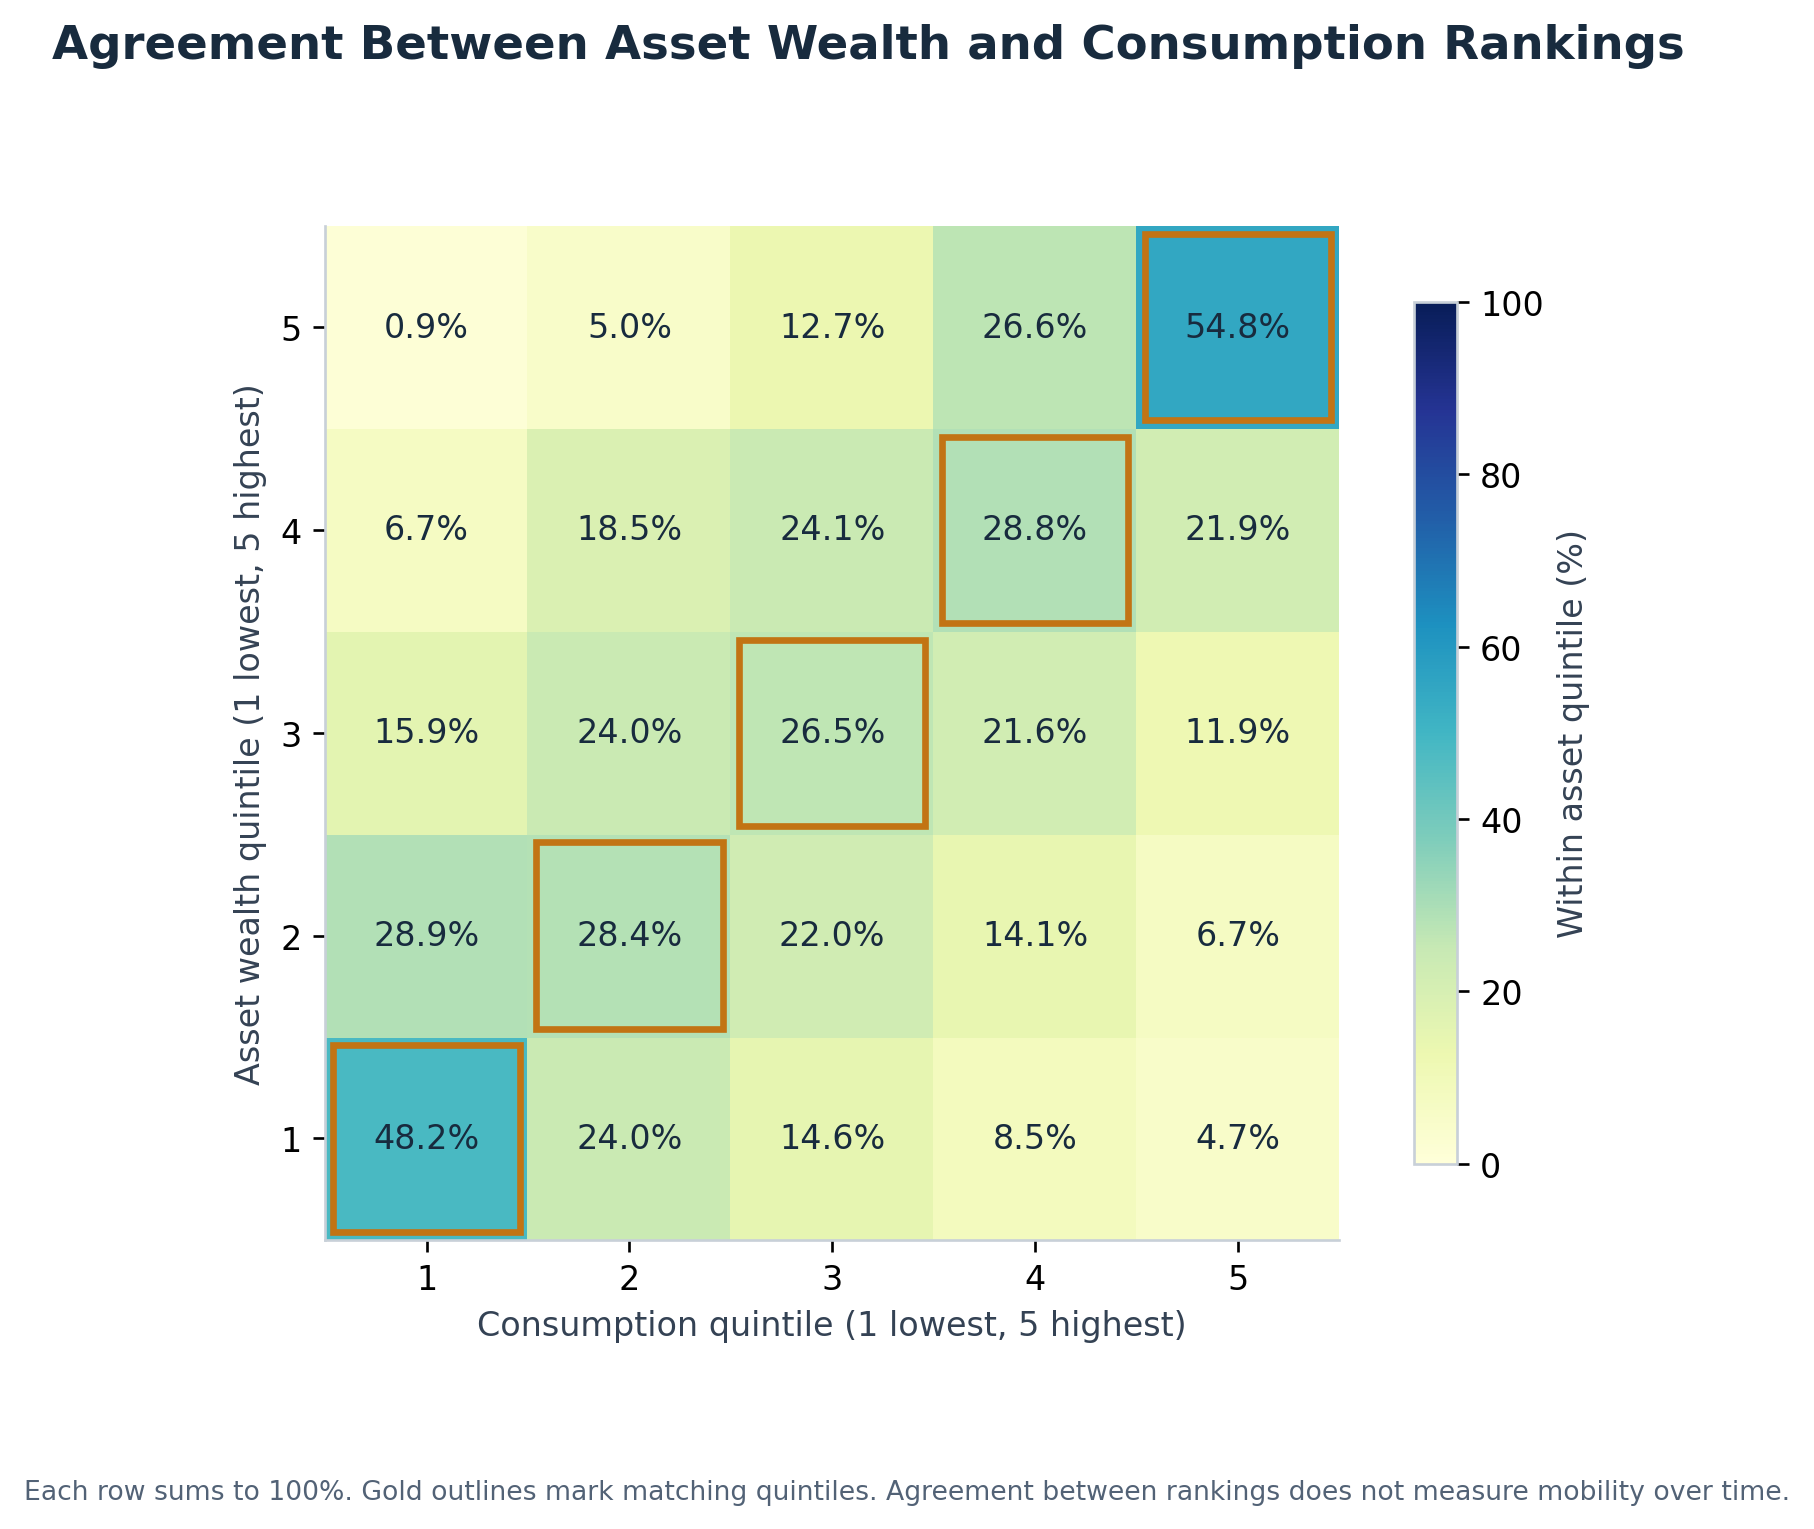

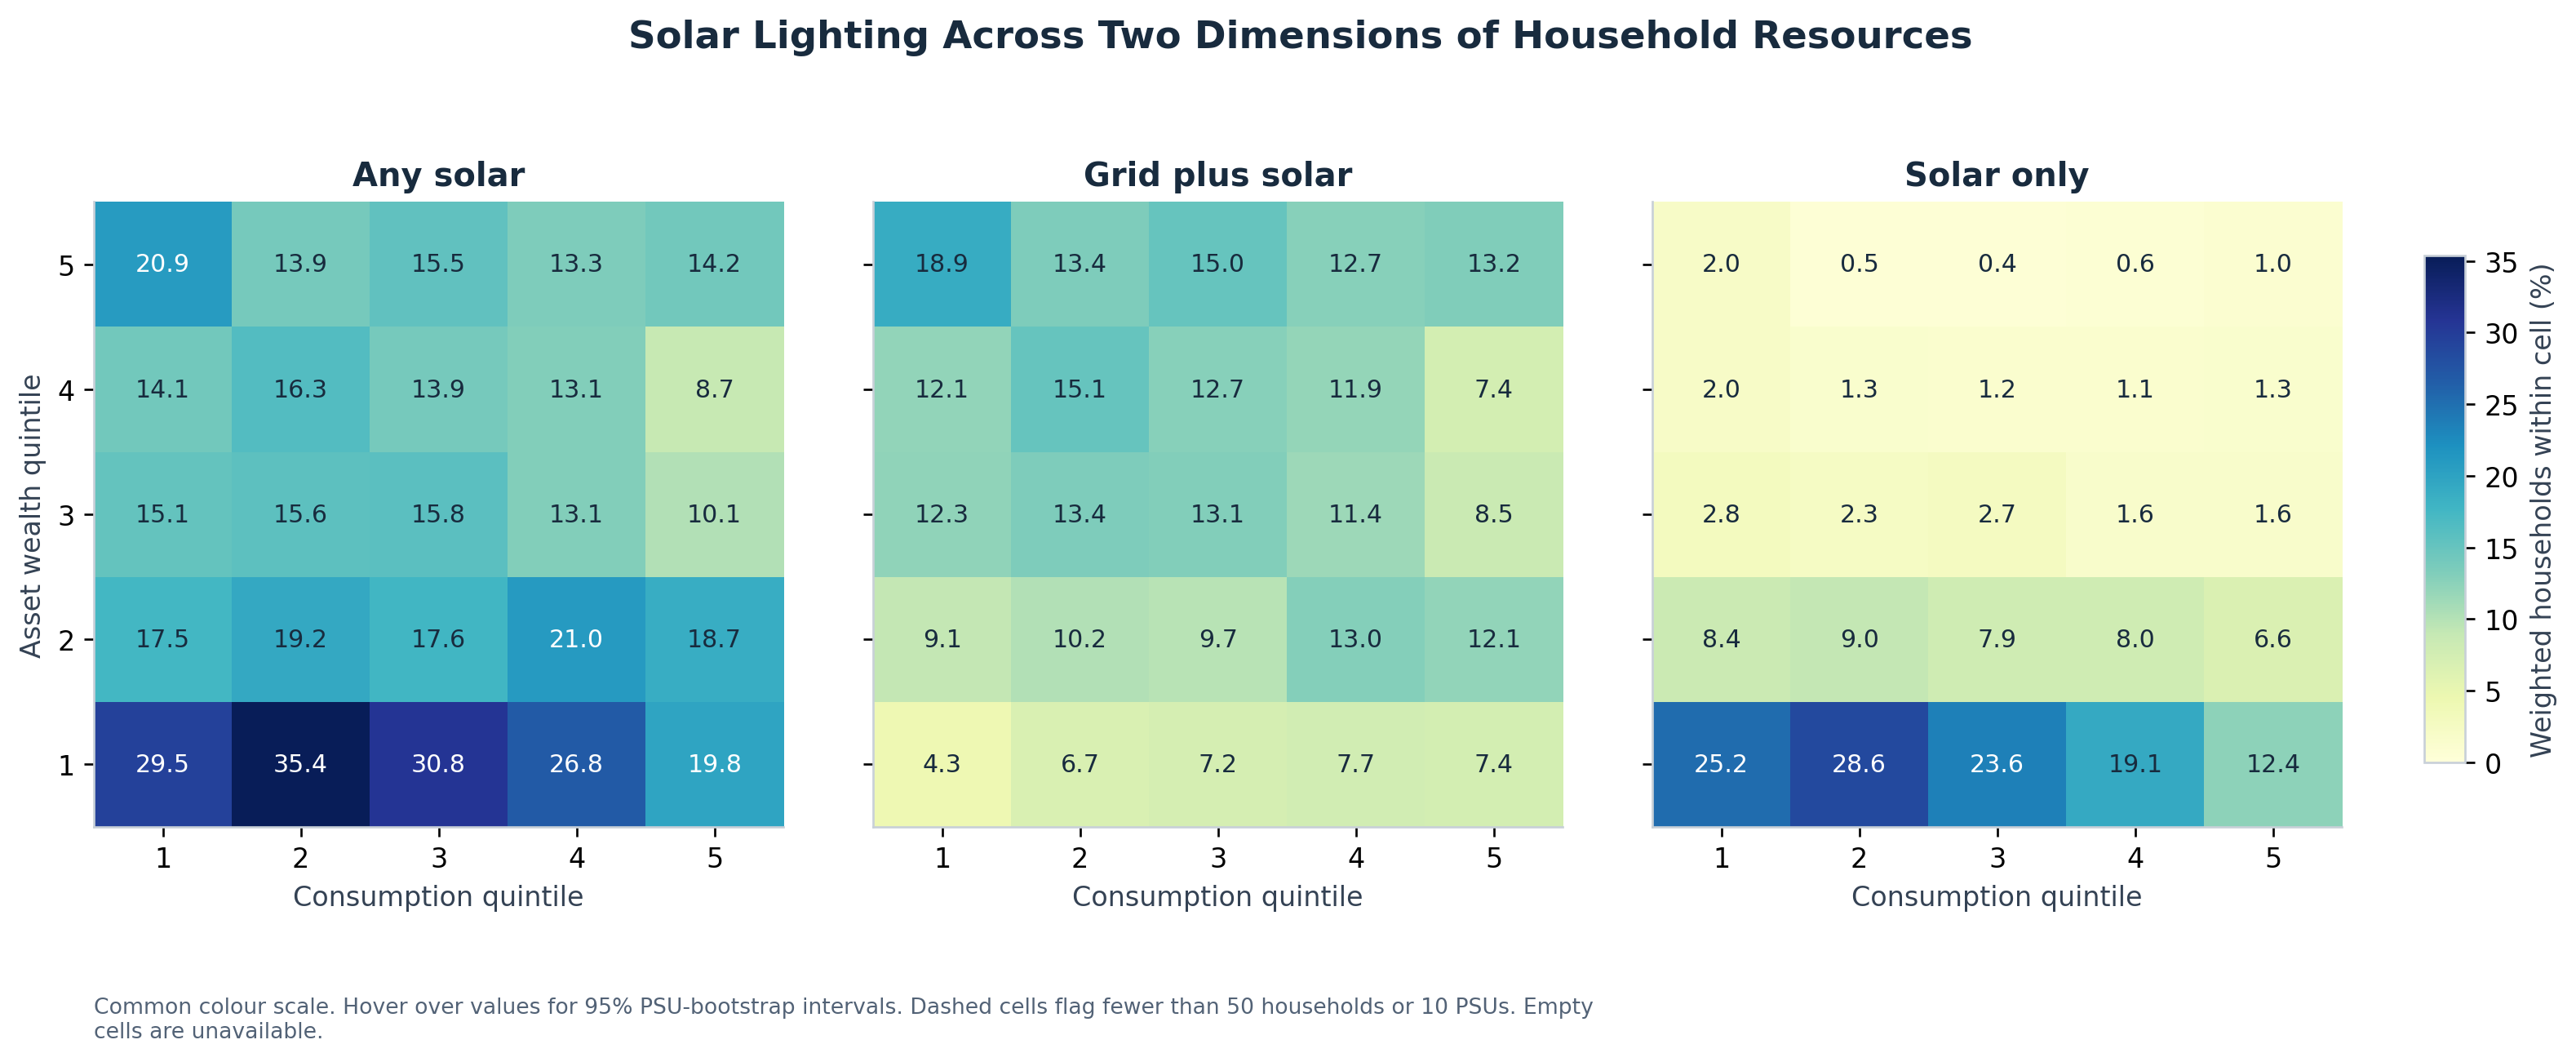

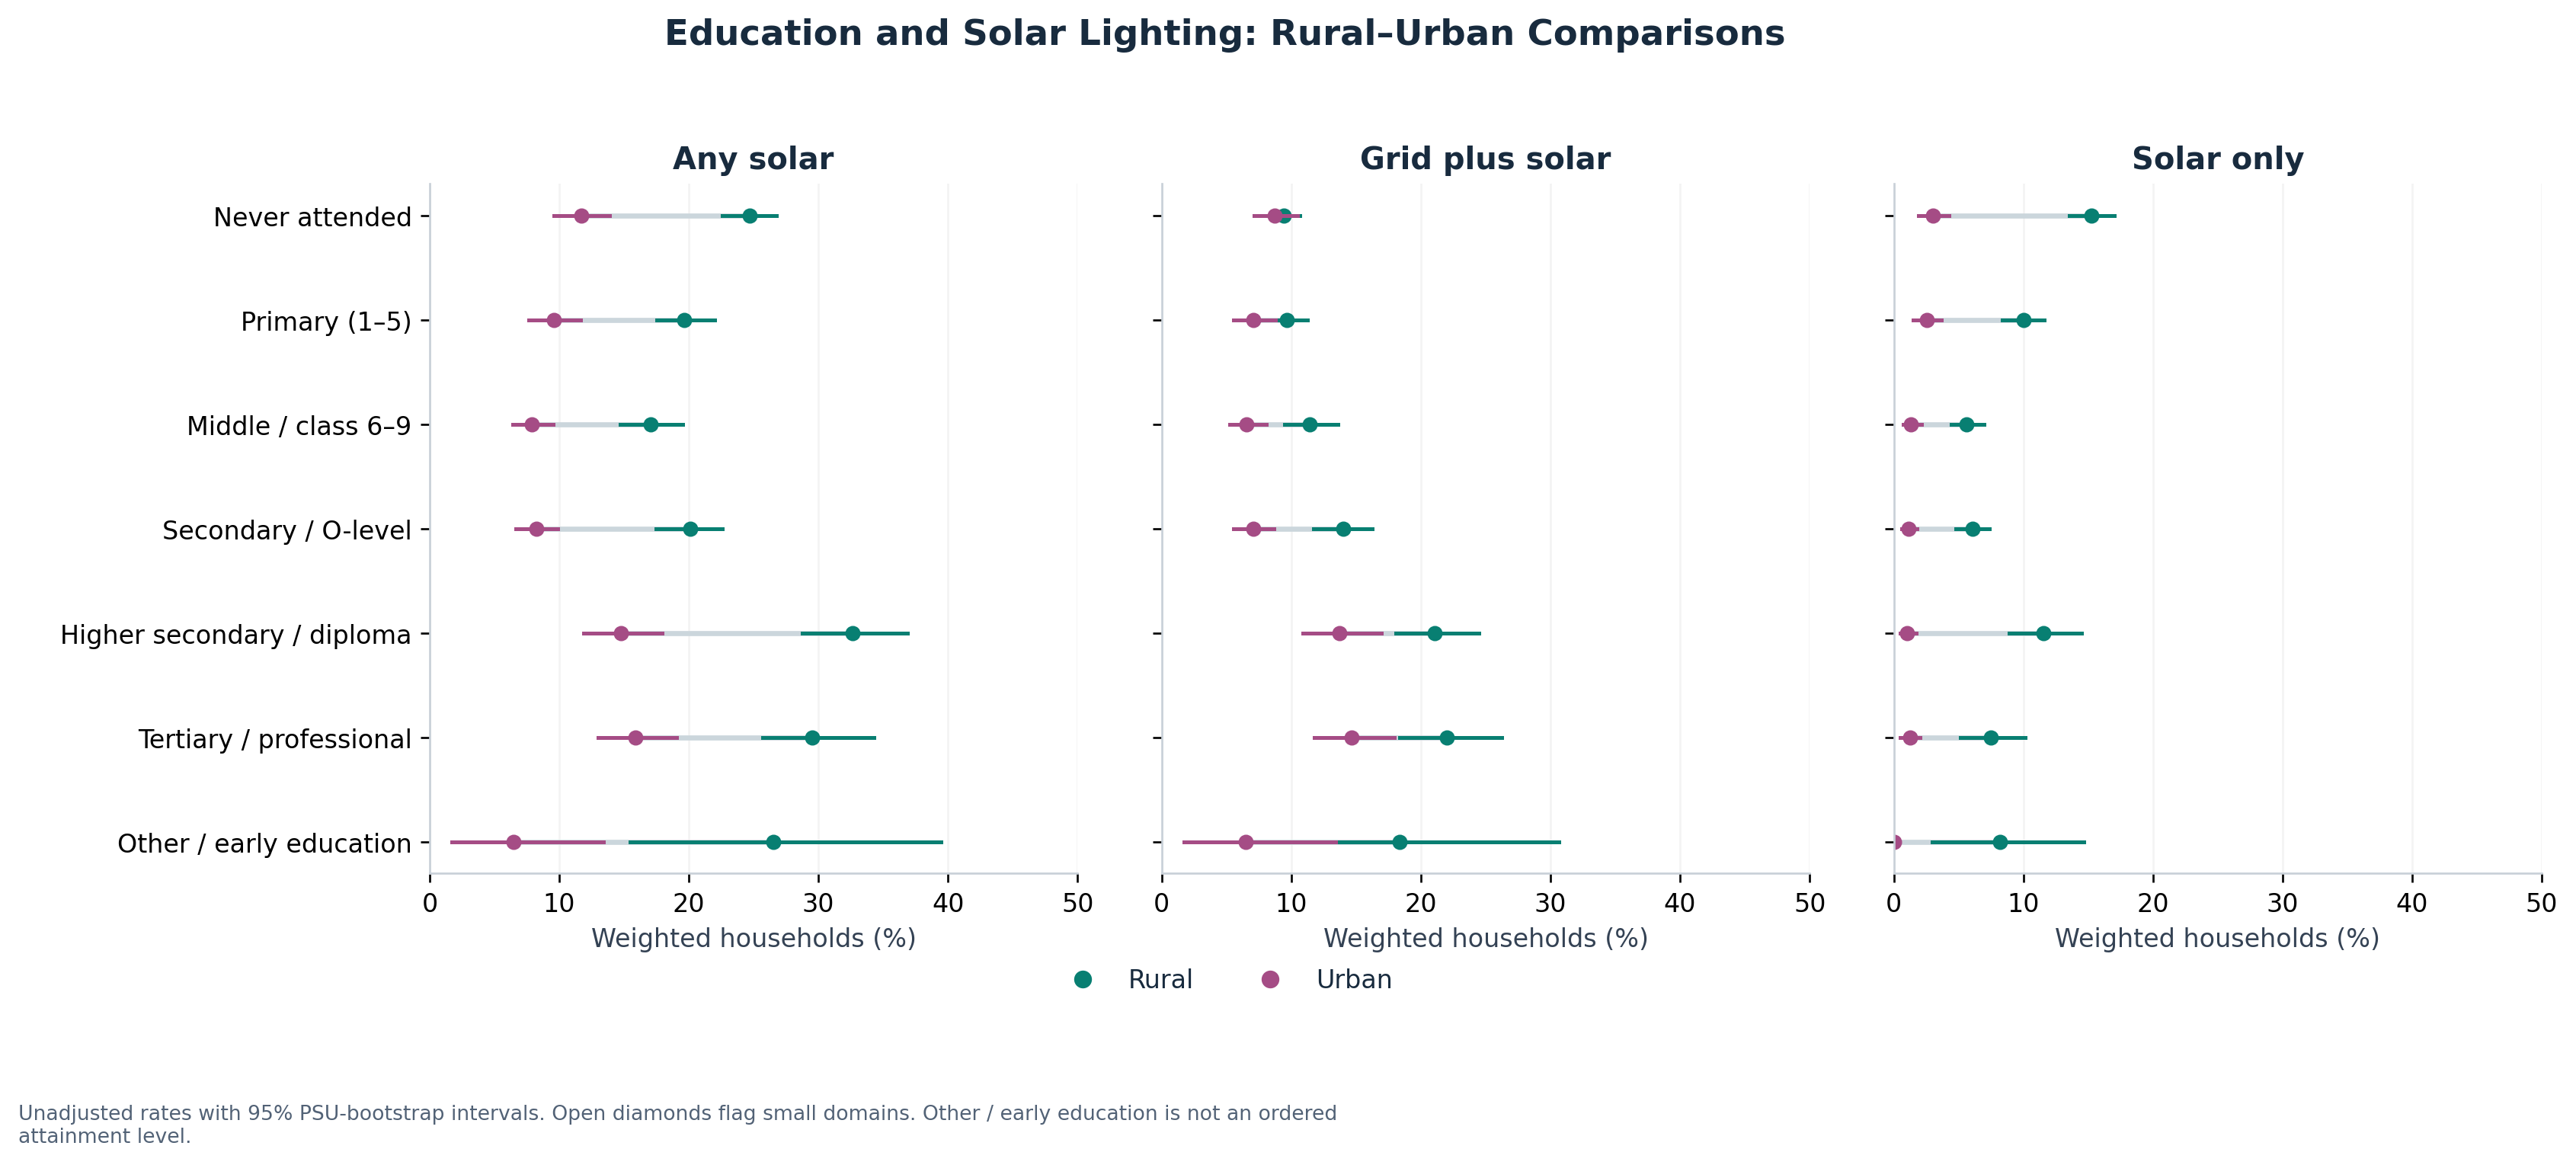

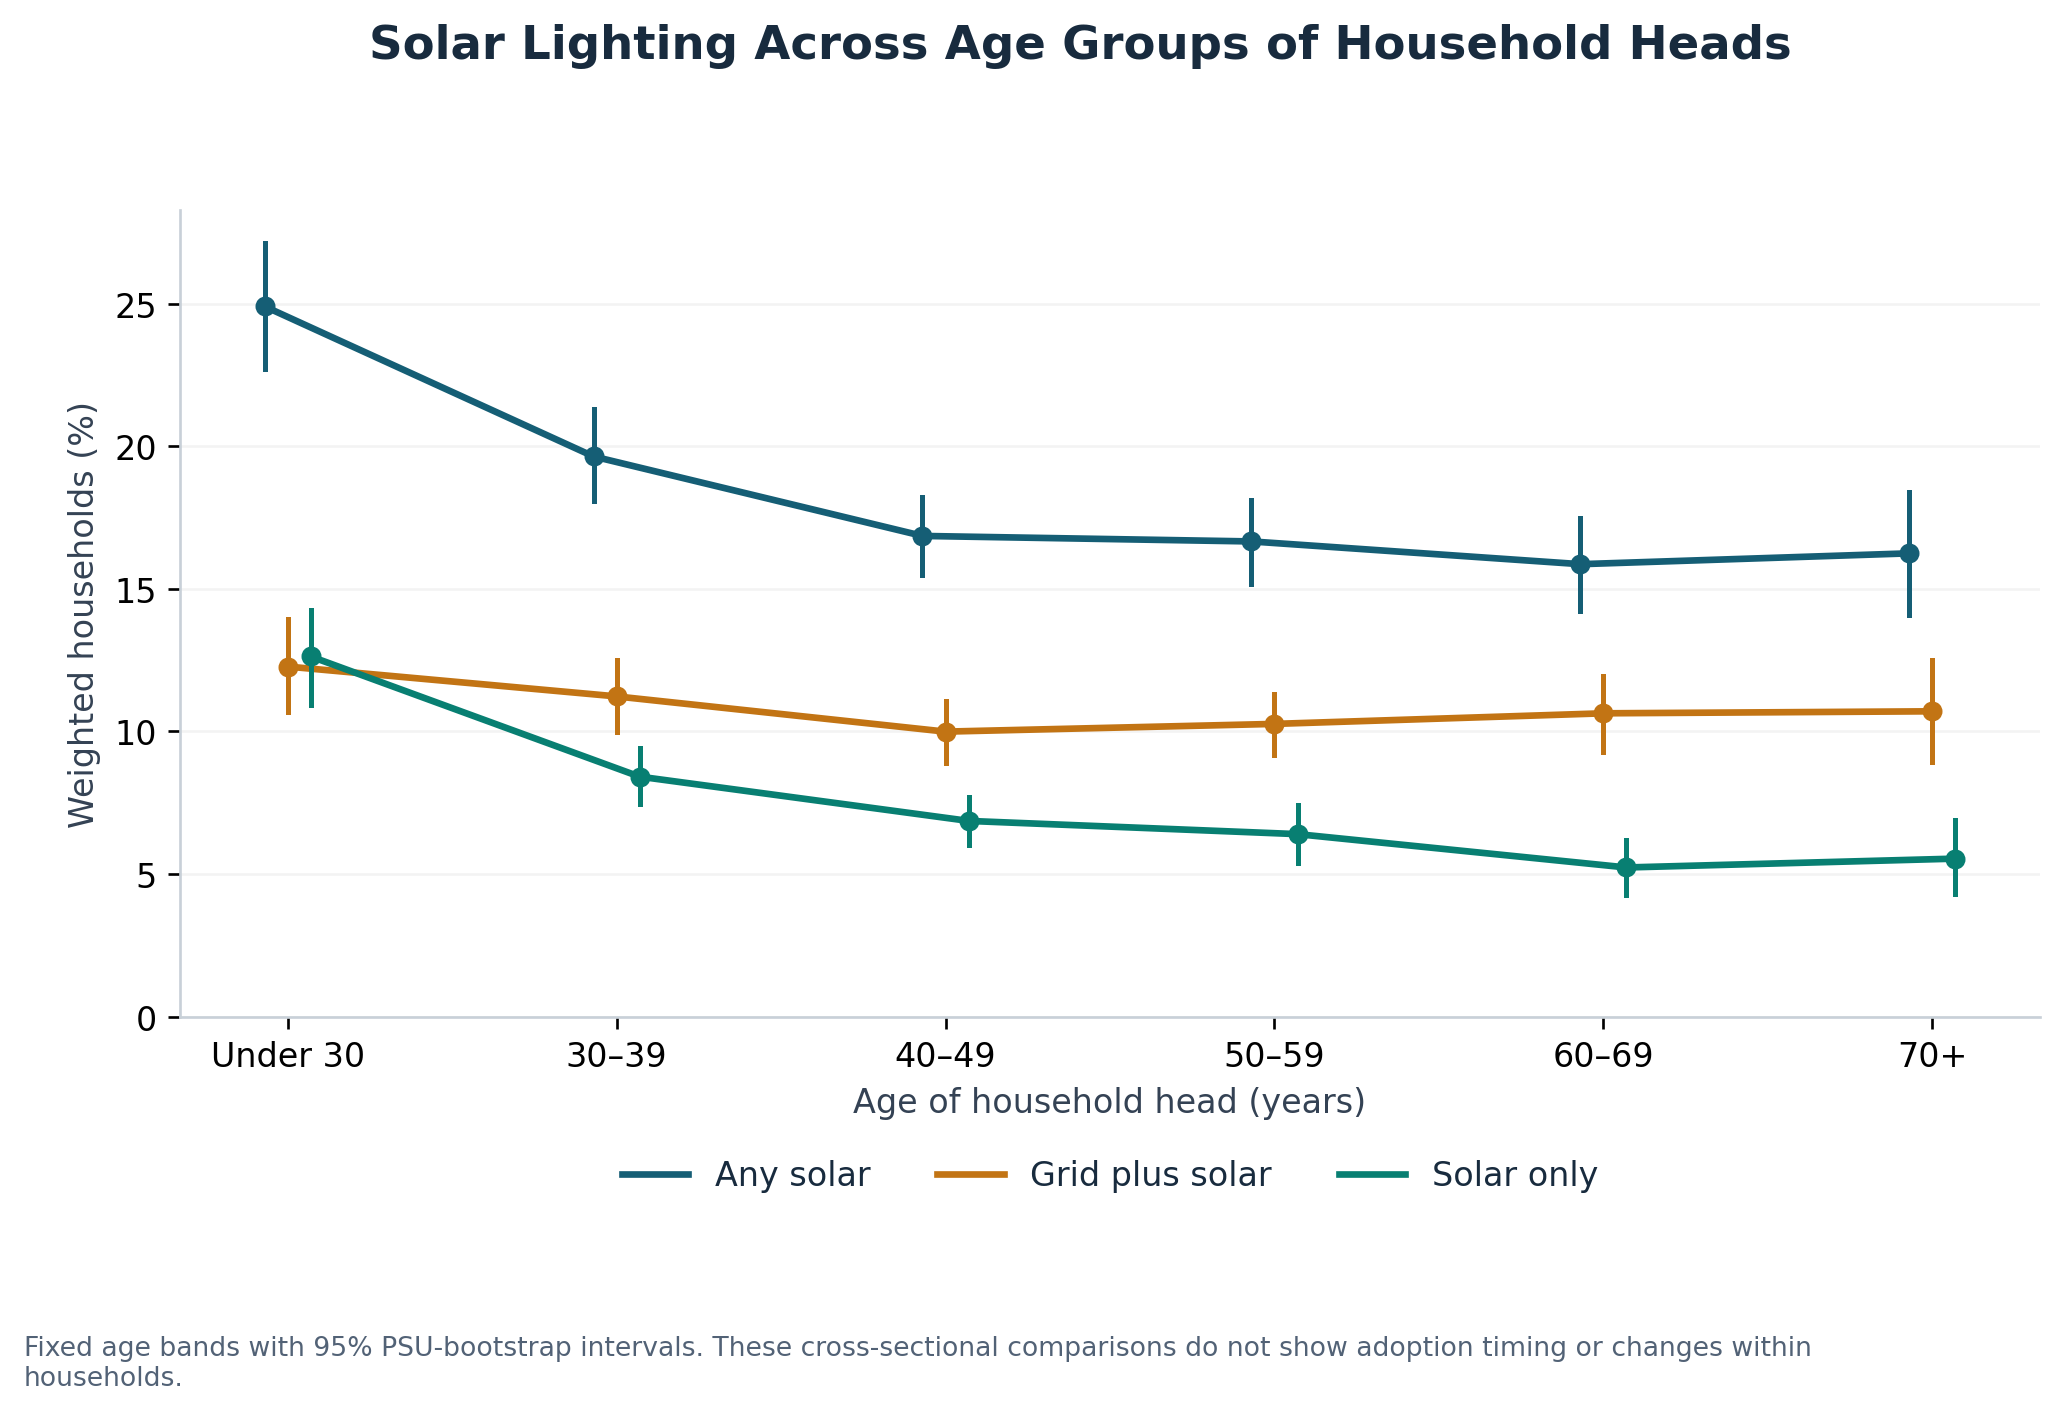

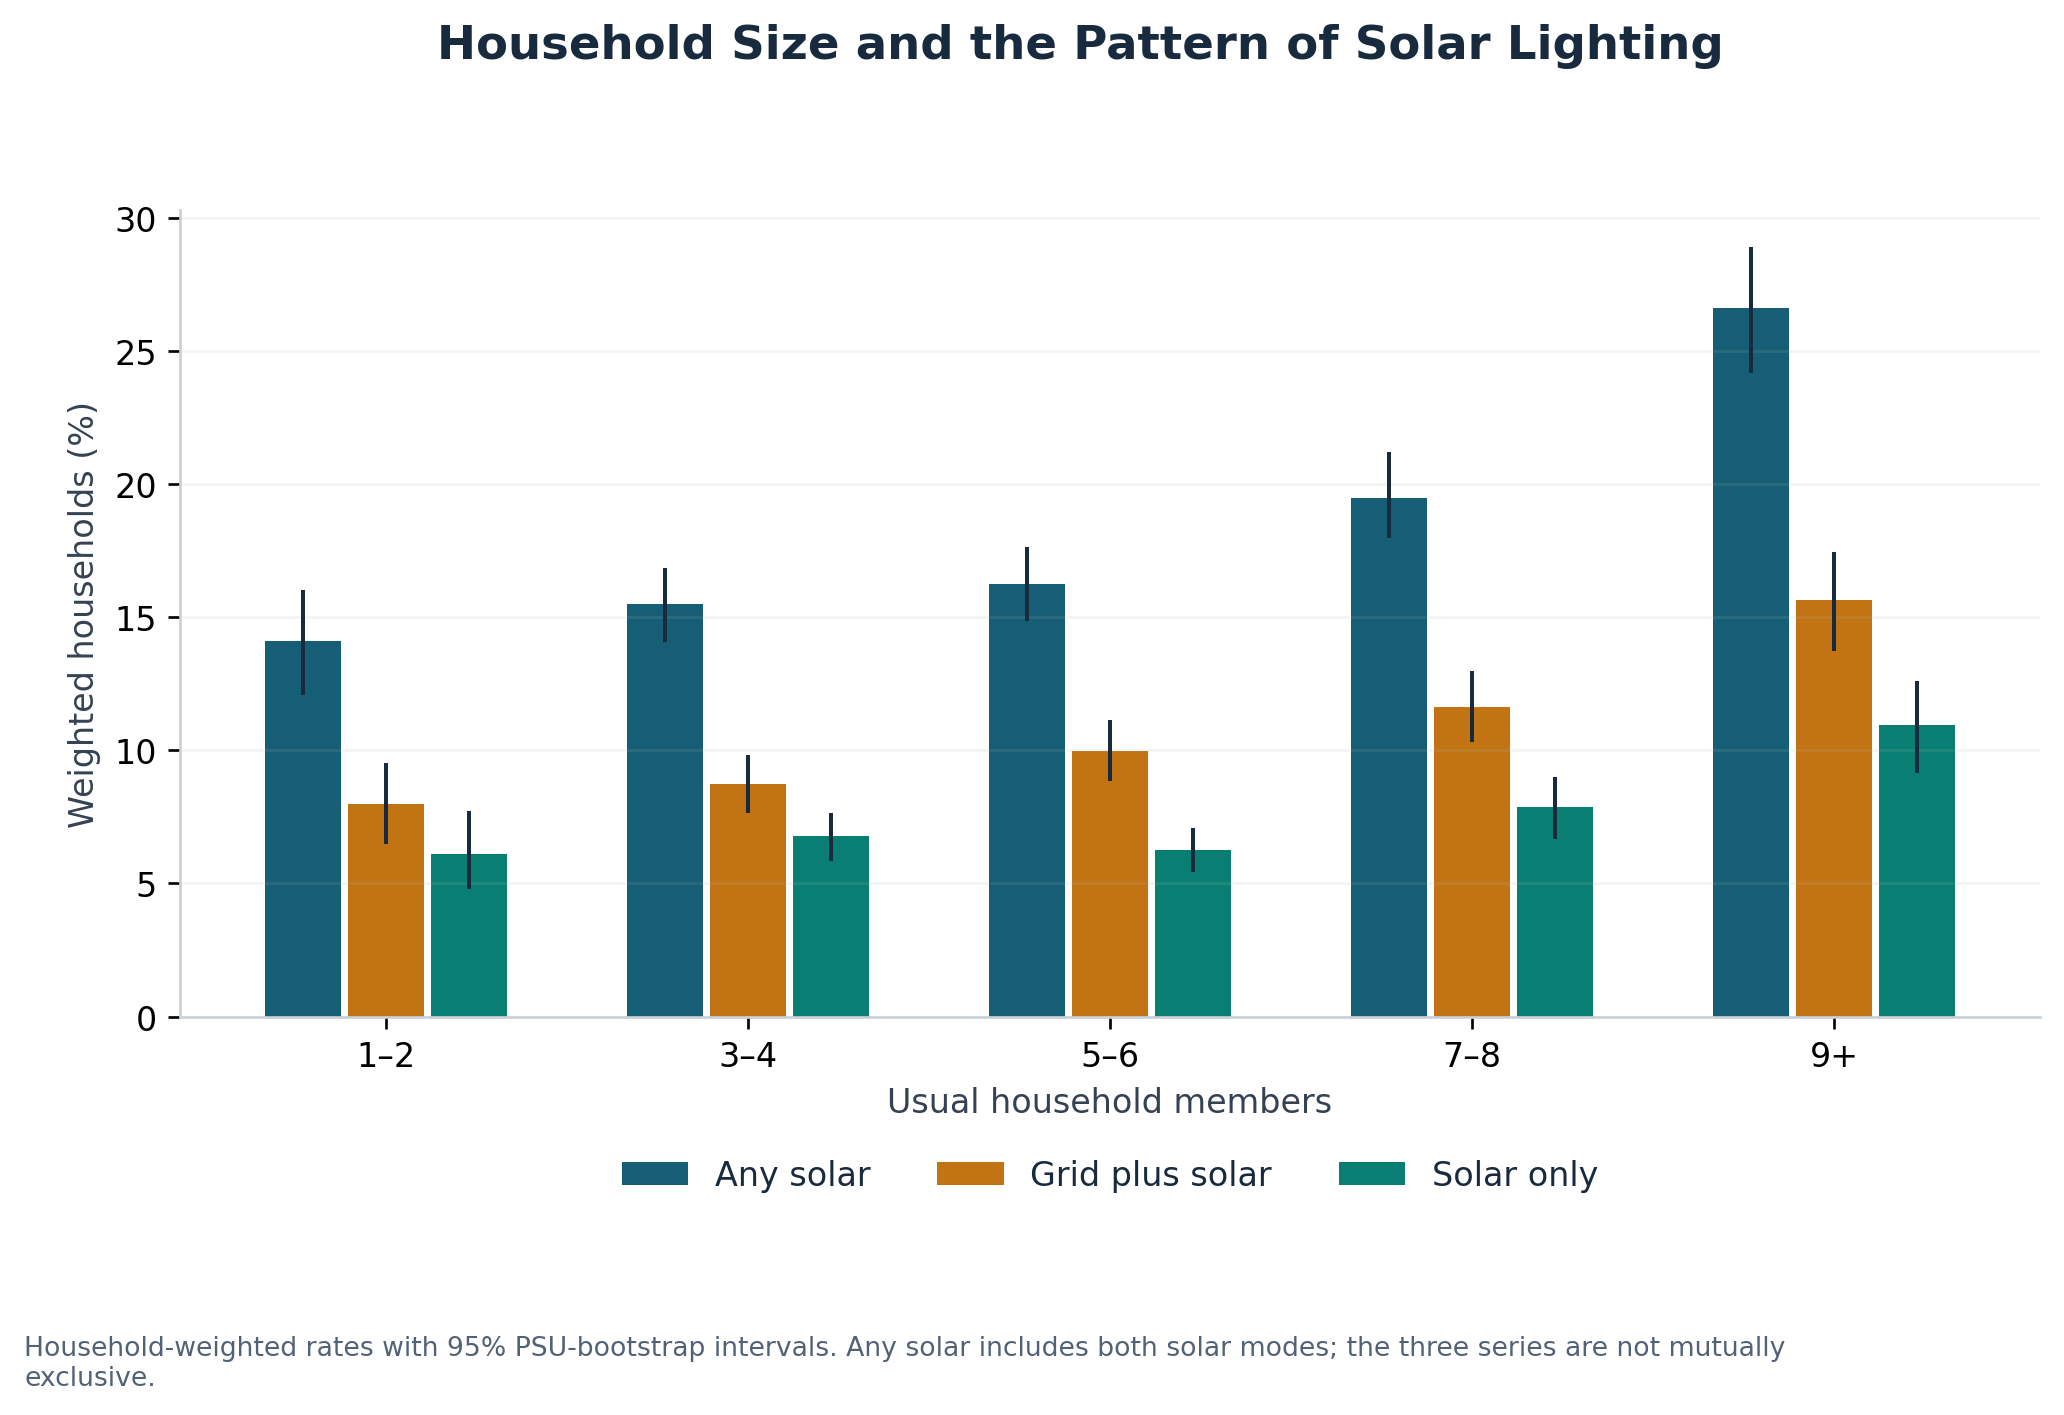

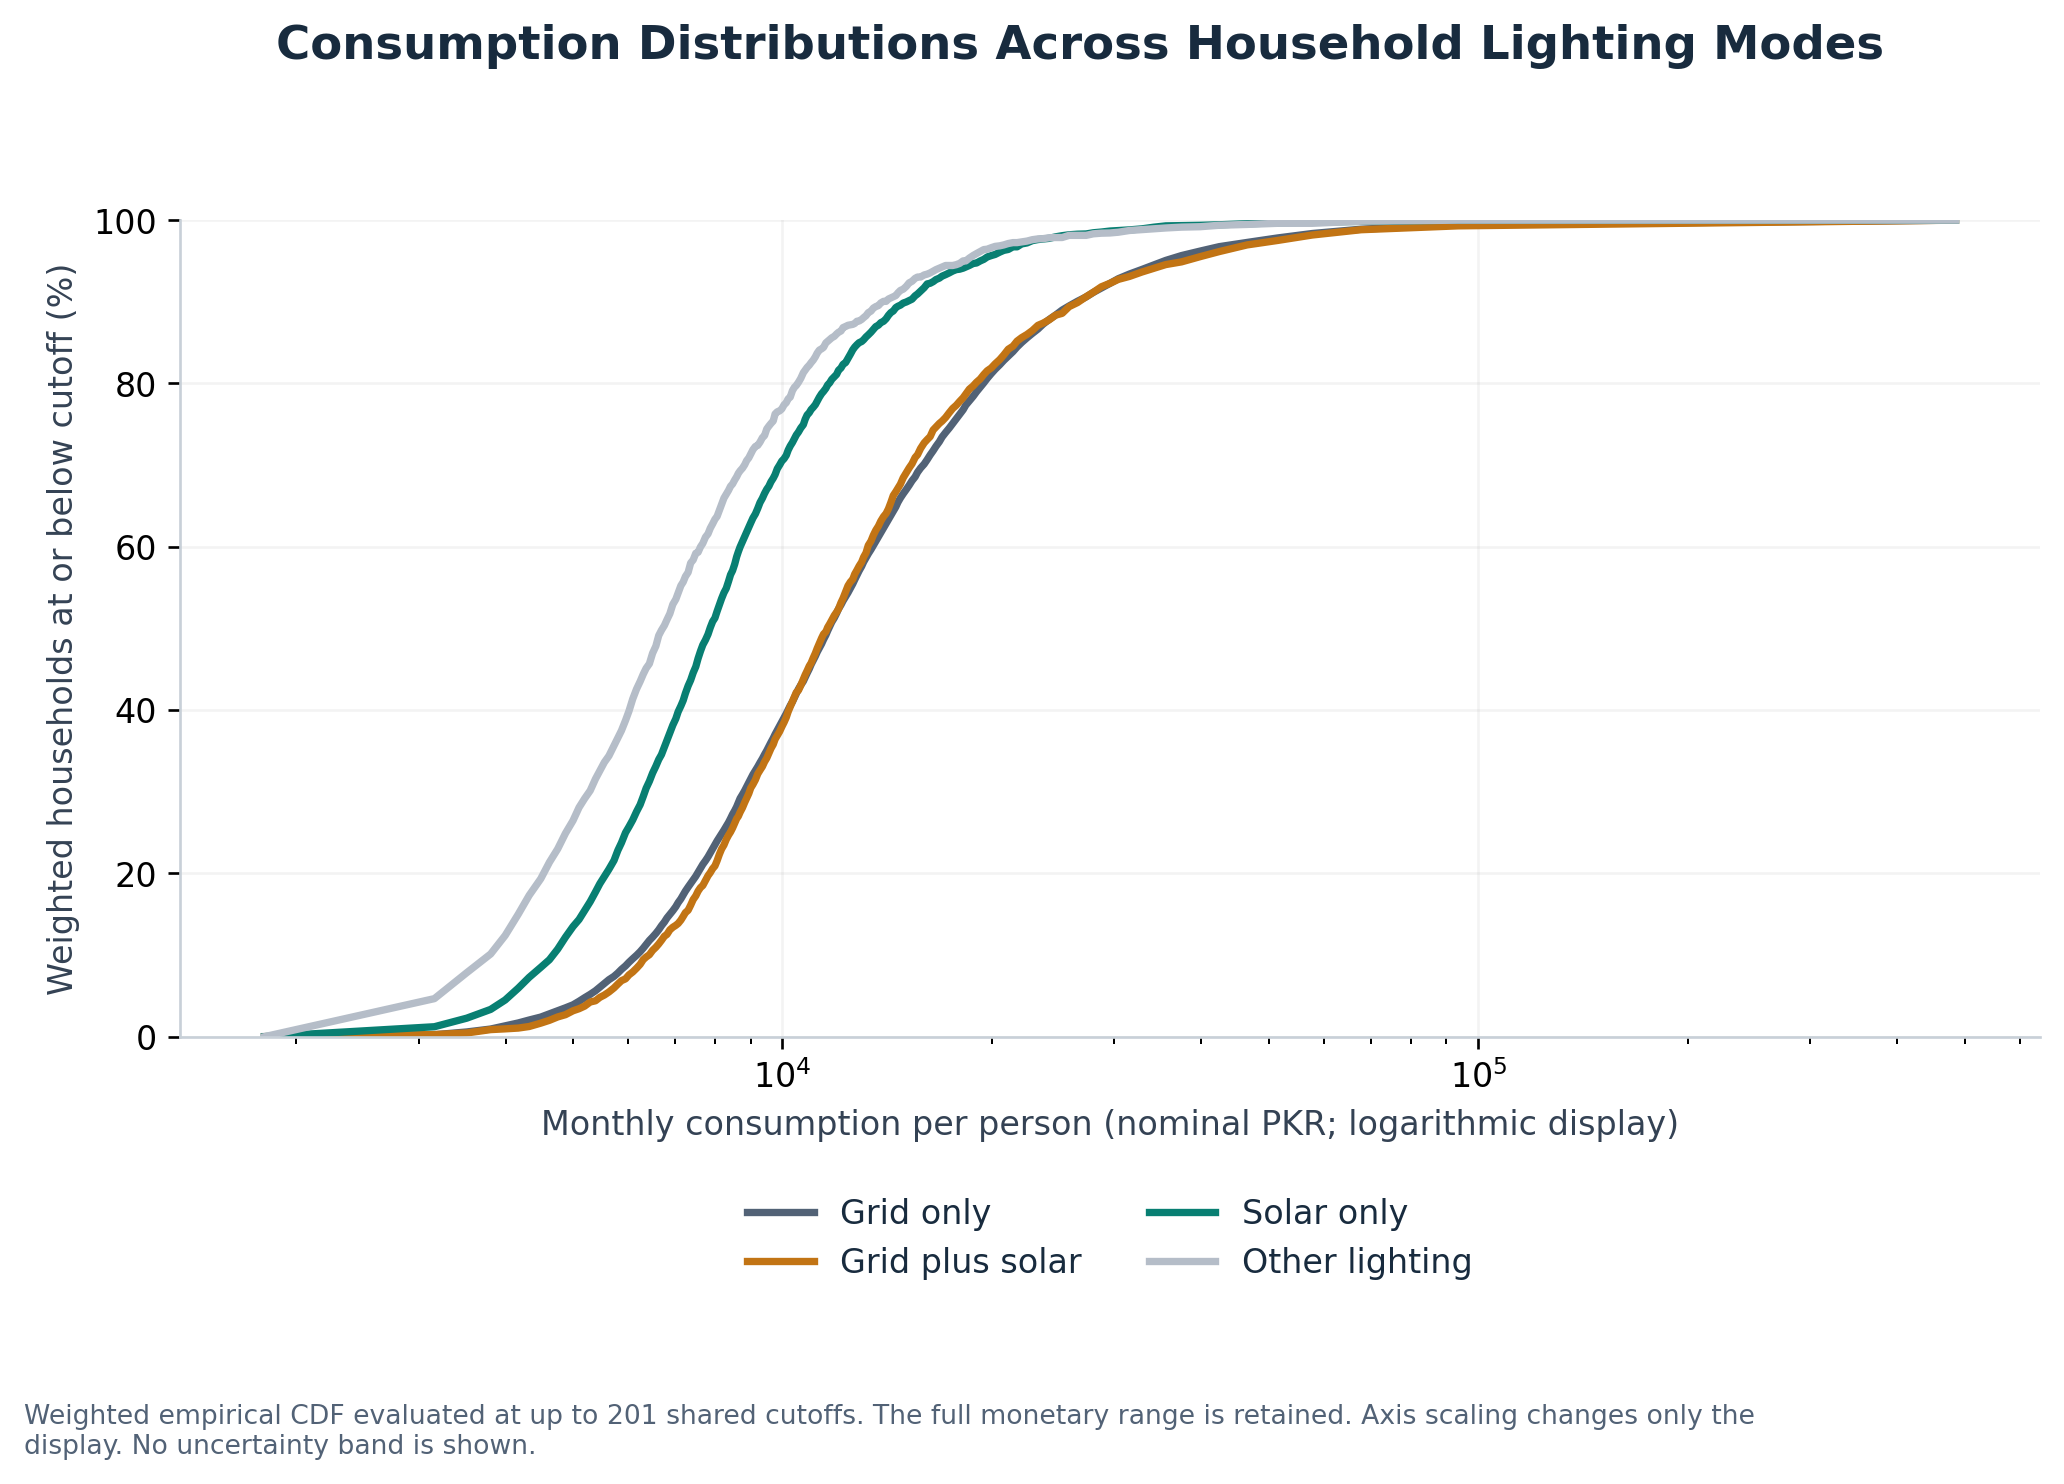

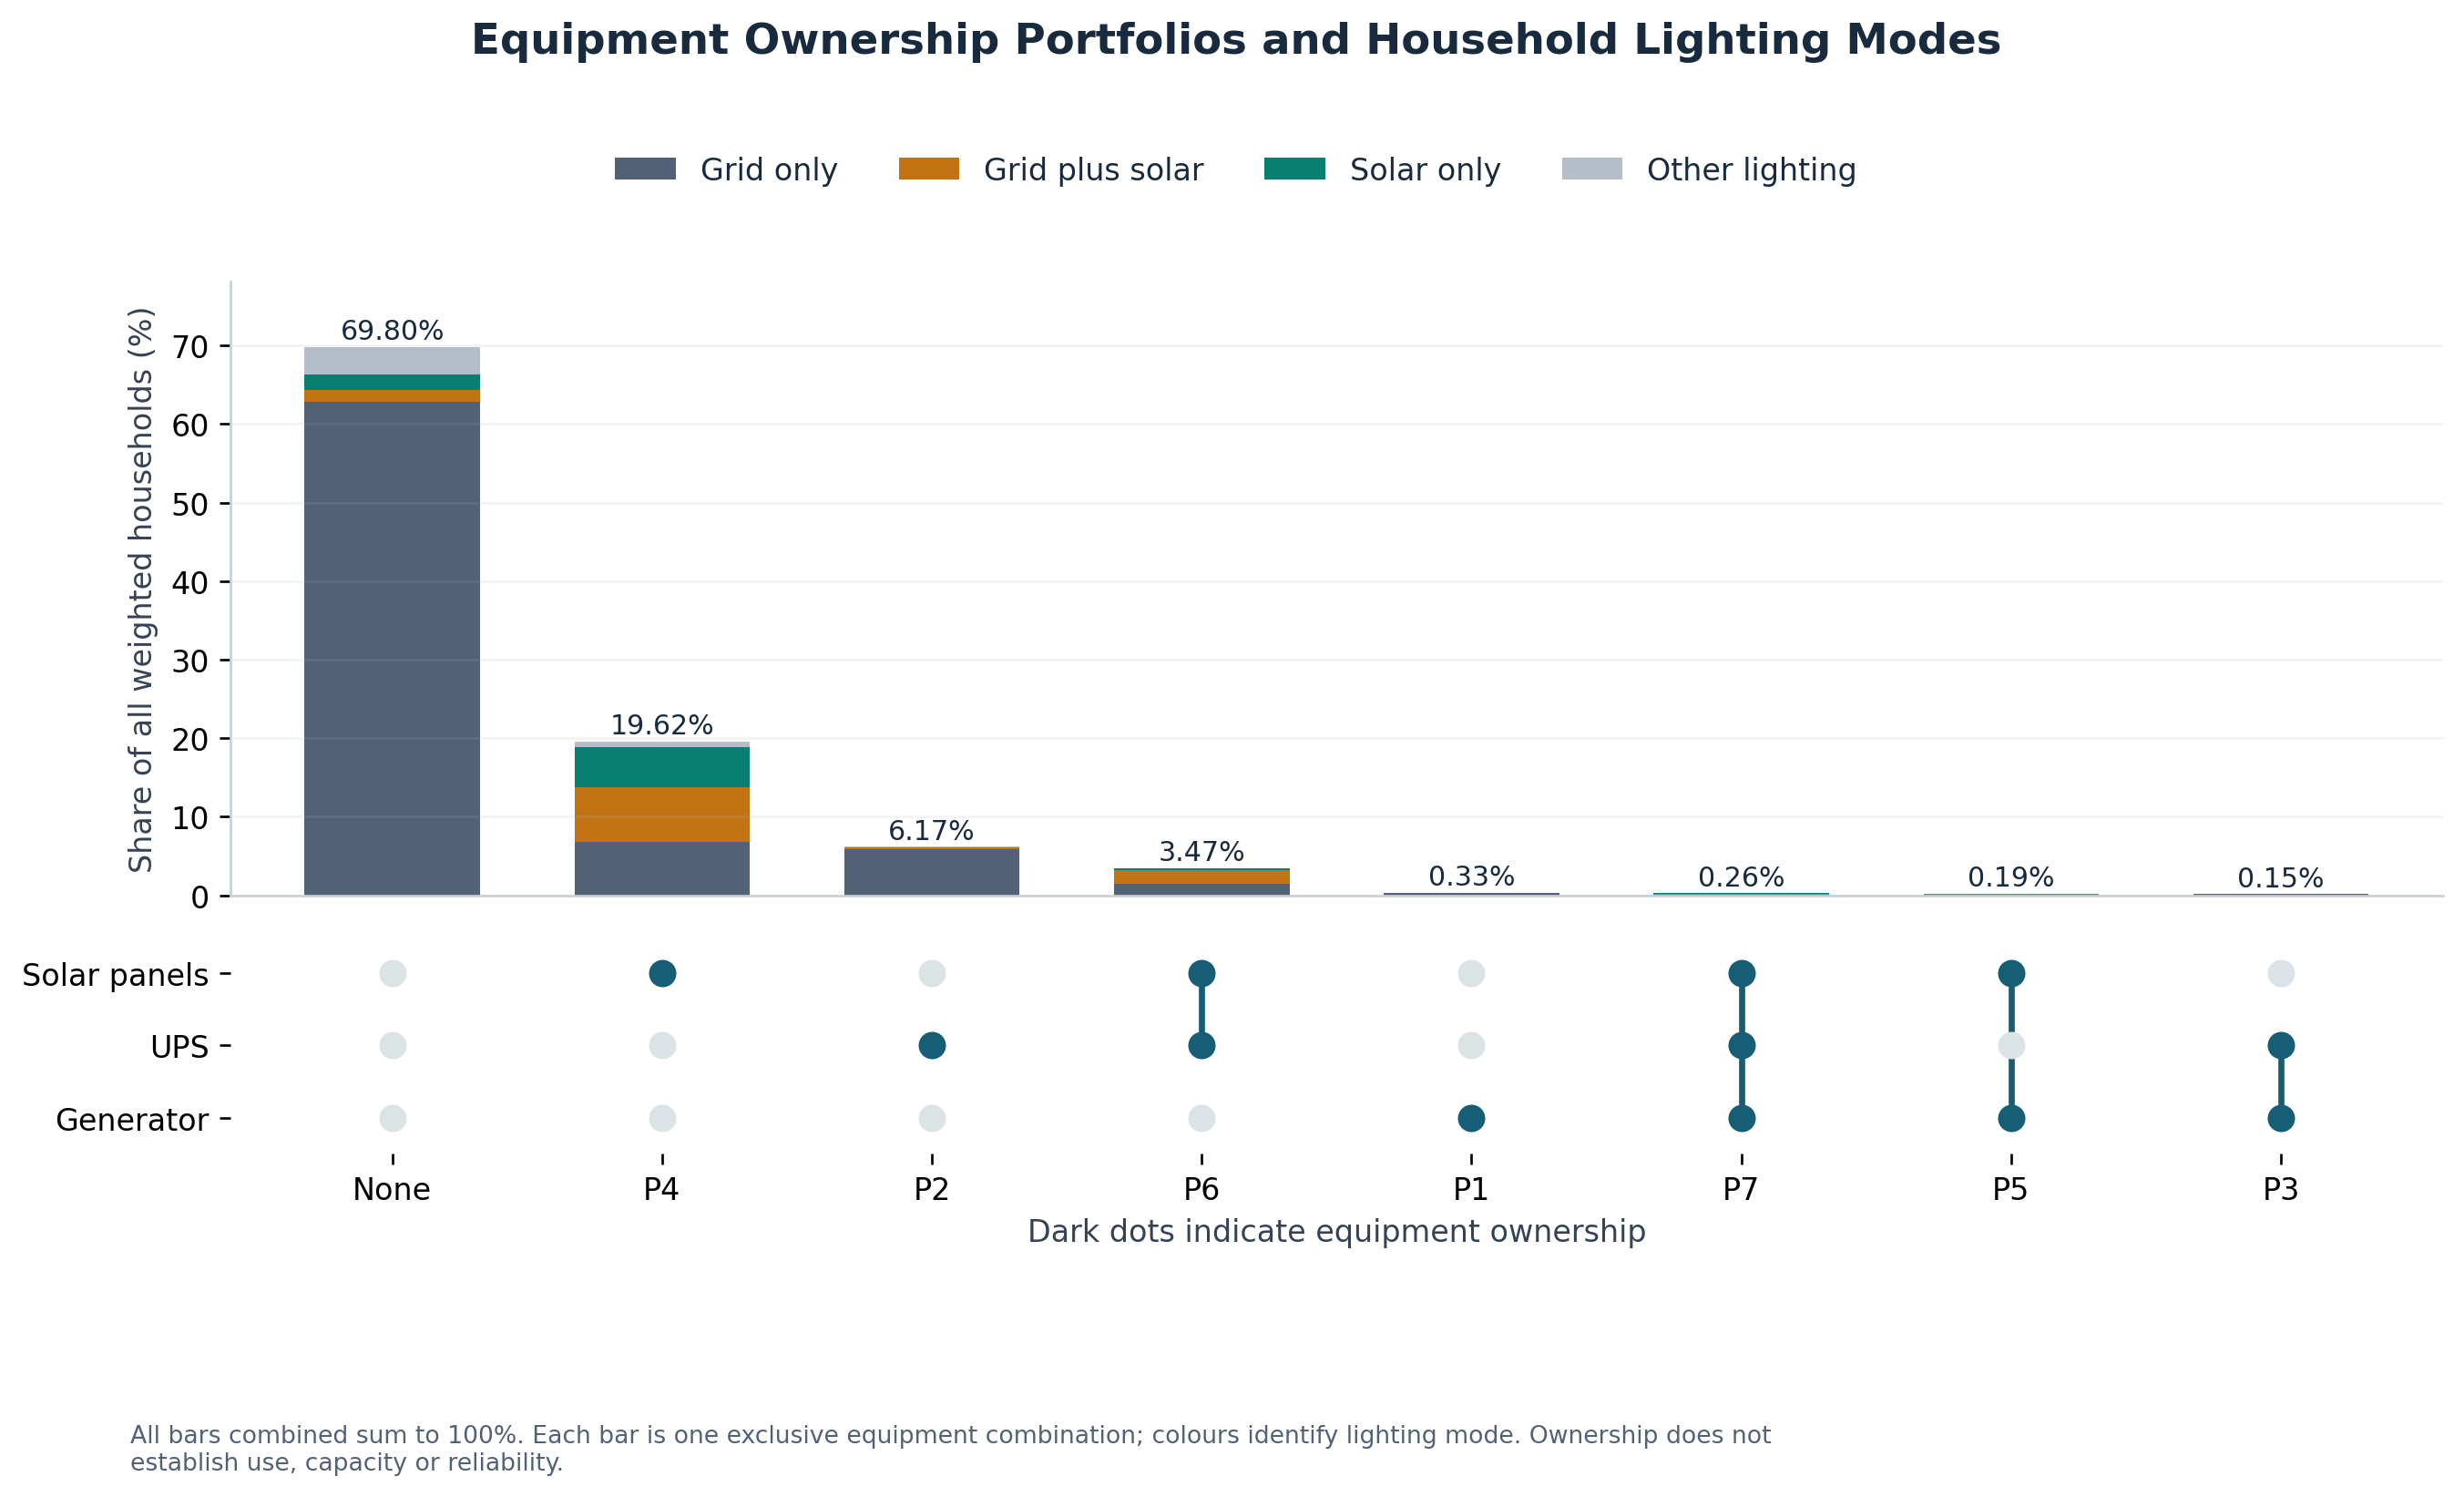

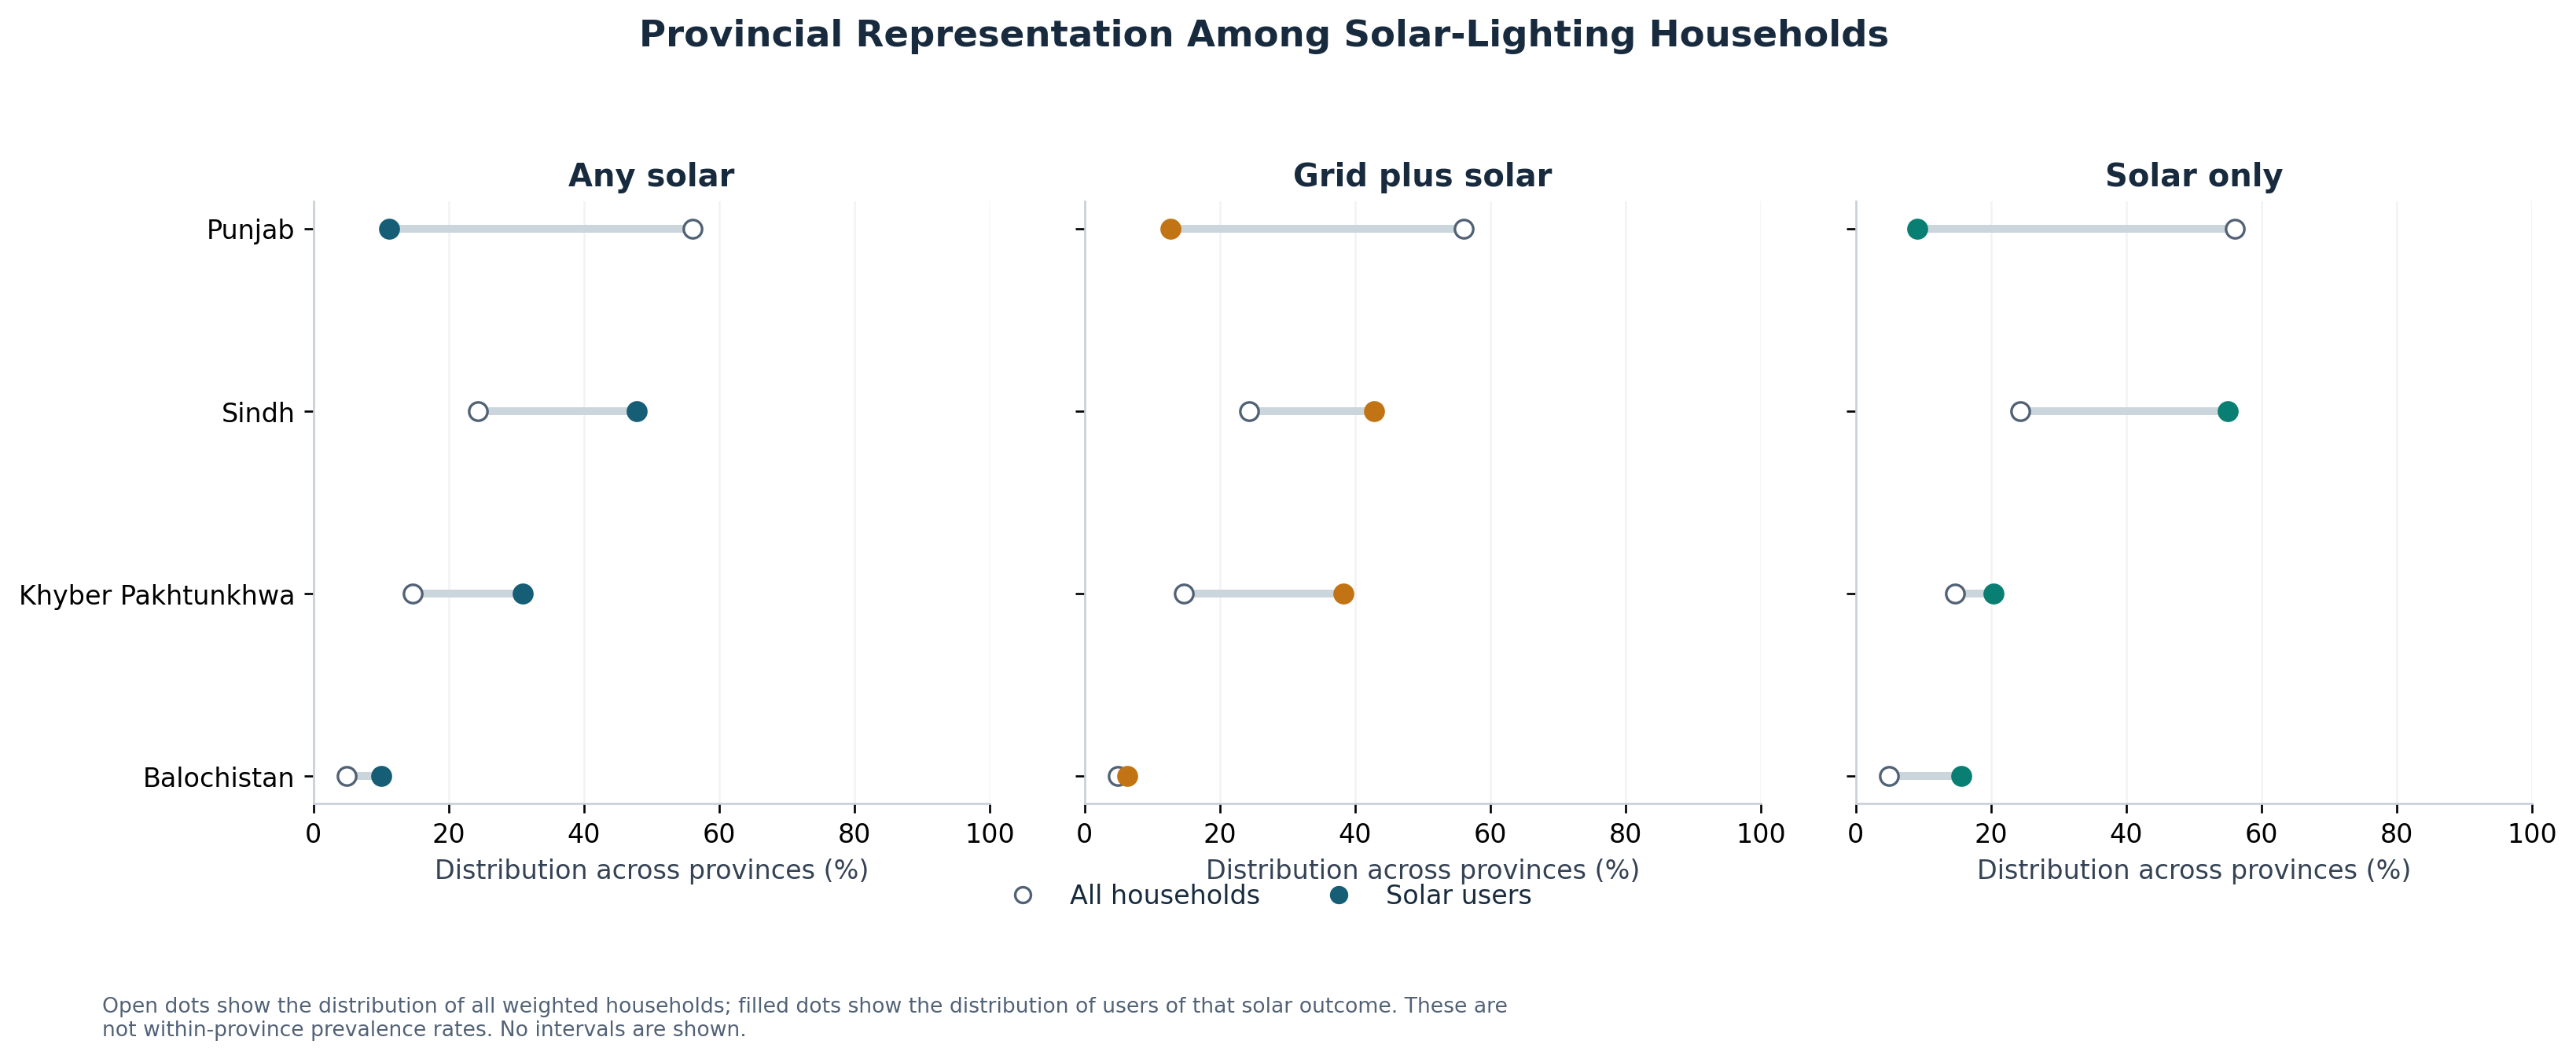

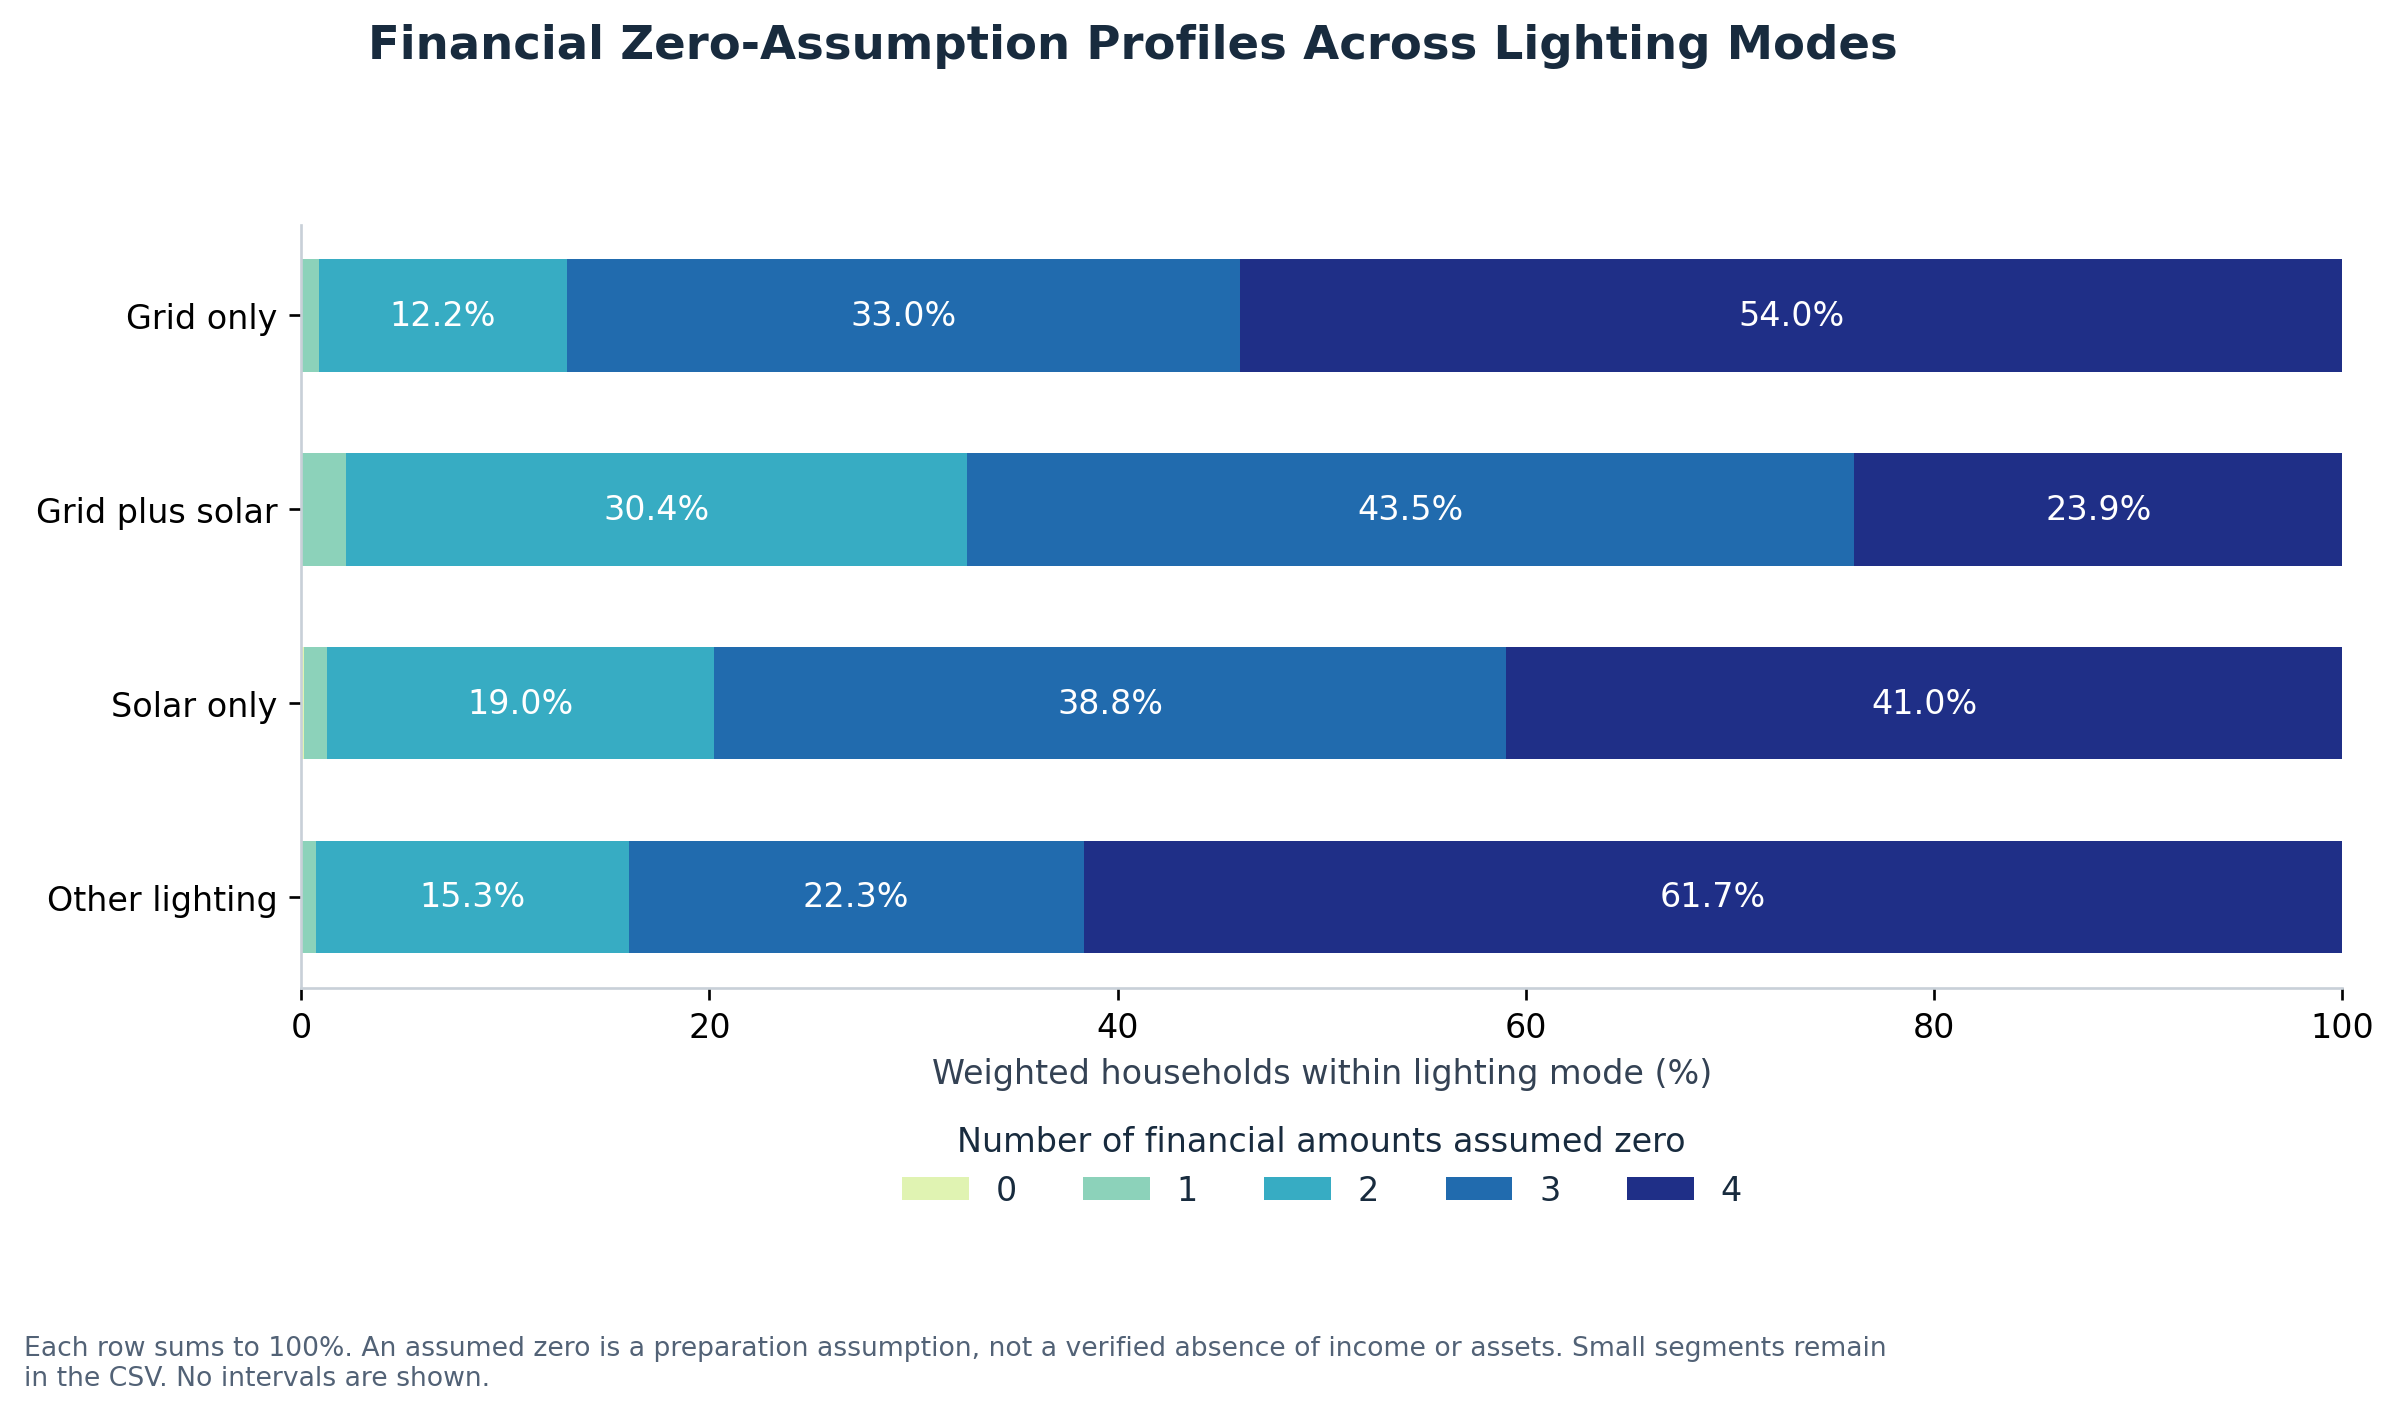

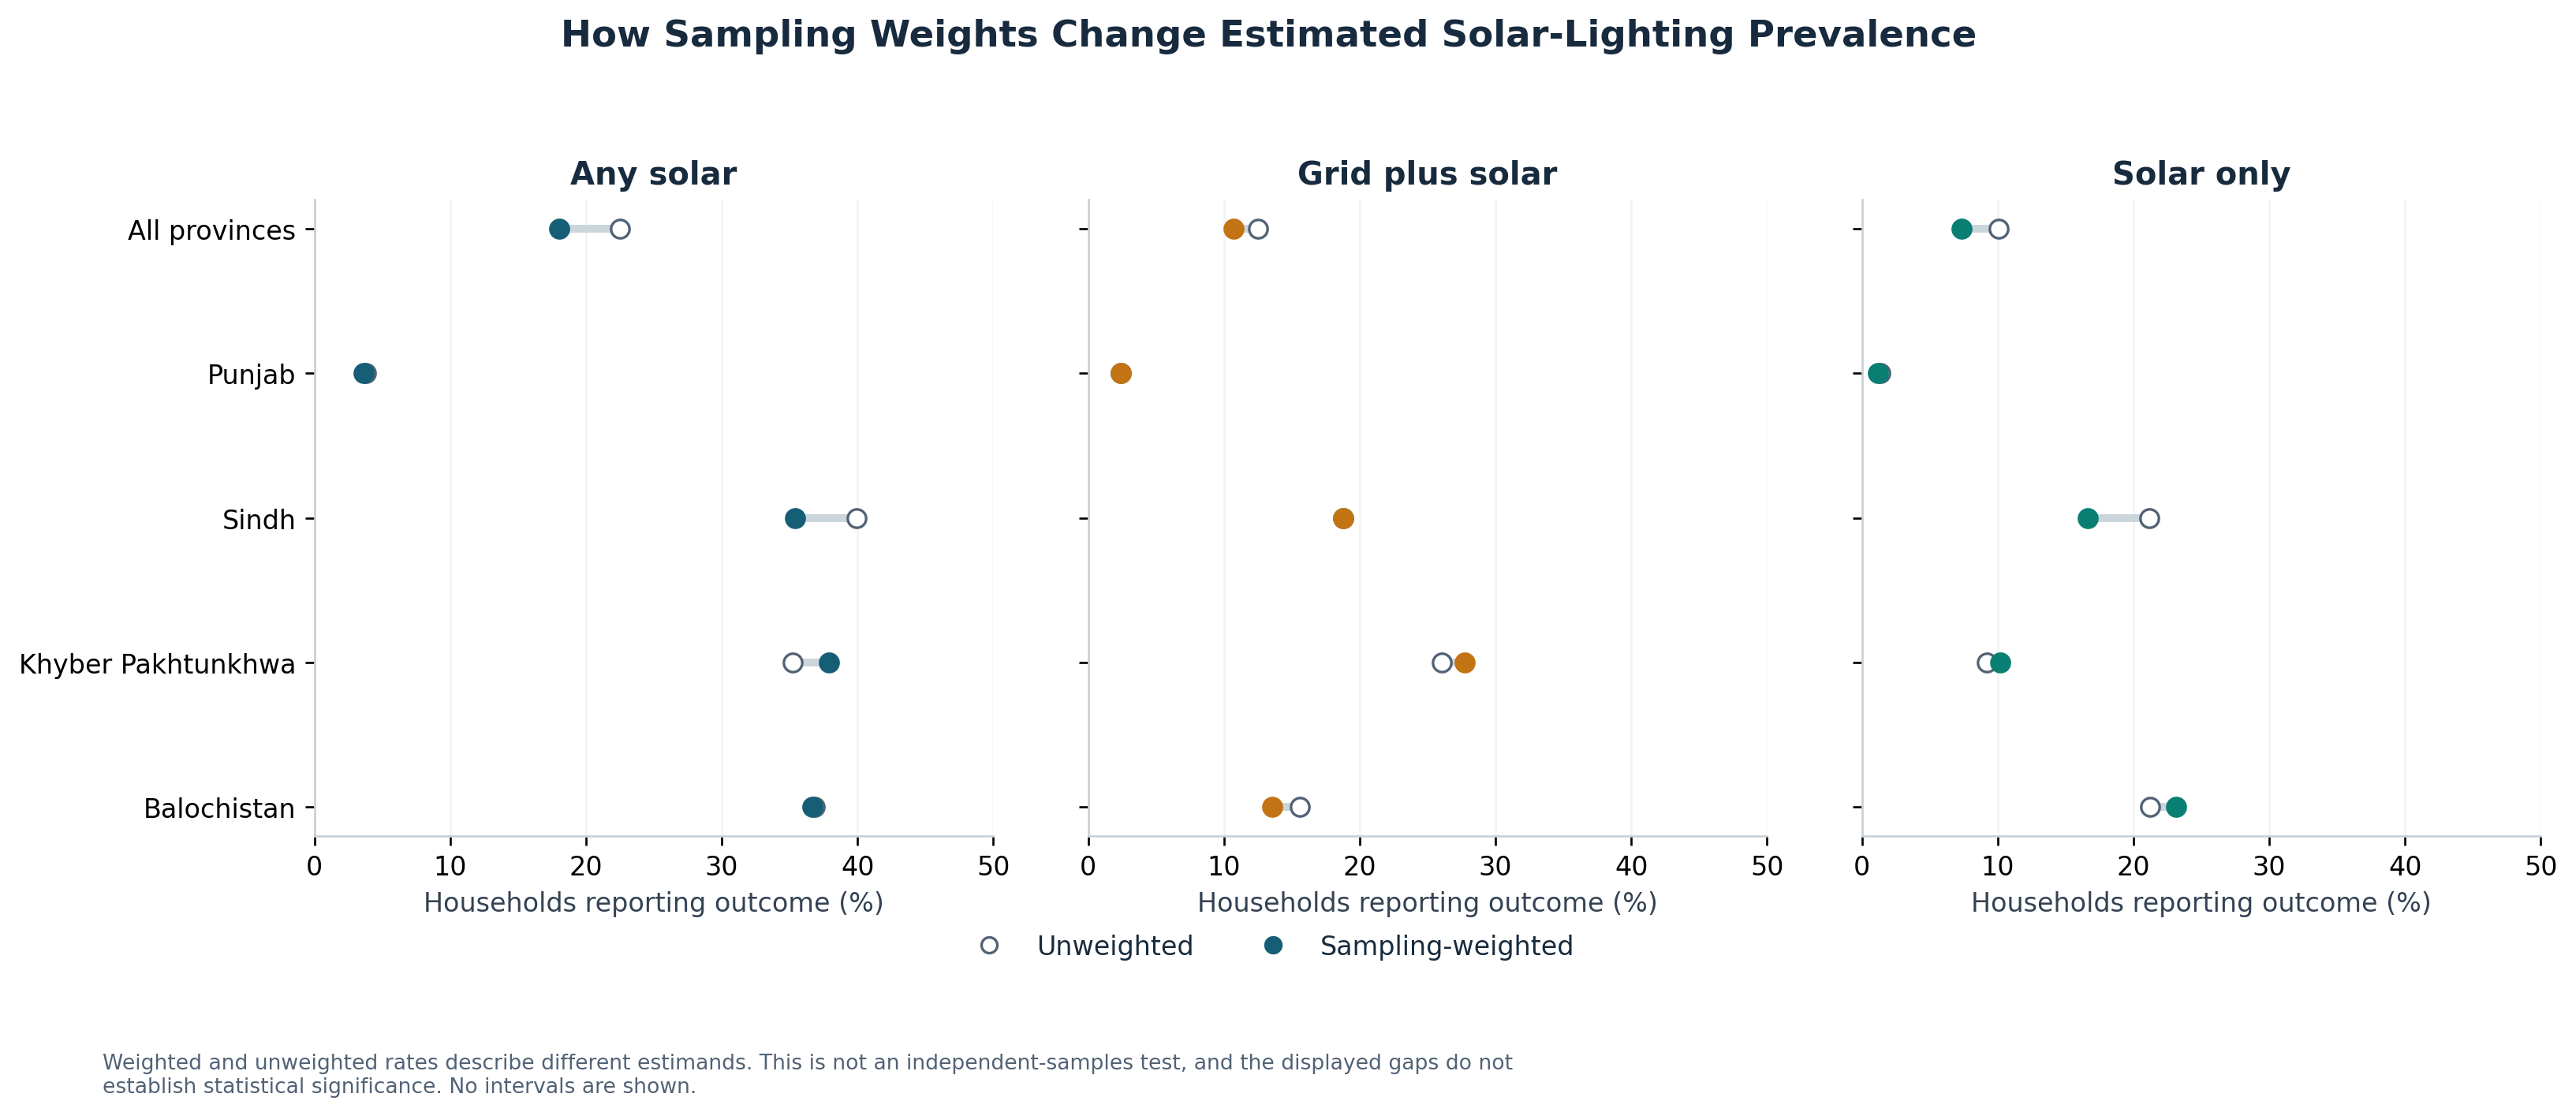

Created 10 additional visualizations.


In [15]:
# 06. Agreement Between Asset Wealth and Consumption Rankings

rows = []

for aq in range(1, 6):
    sub = v[v.wealth_quintile.eq(aq)]

    for cq in range(1, 6):
        cell = sub[sub.consumption_quintile.eq(cq)]

        rows.append({
            "asset_quintile": aq,
            "consumption_quintile": cq,
            "n": len(cell),
            "within_asset_quintile_percent": (
                100 * cell.survey_weight.sum()
                / sub.survey_weight.sum()
                if len(sub) else np.nan
            )
        })

t06 = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 6.5))
fig.subplots_adjust(bottom=.19, top=.84)

im = ax.imshow(
    t06.pivot(
        index="asset_quintile",
        columns="consumption_quintile",
        values="within_asset_quintile_percent"
    ),
    origin="lower", cmap="YlGnBu", vmin=0, vmax=100
)

for r in t06.itertuples():
    tip = (
        f"Asset quintile {r.asset_quintile}; "
        f"consumption quintile {r.consumption_quintile}\n"
        f"Within asset quintile: "
        f"{r.within_asset_quintile_percent:.2f}%\n"
        f"Households: {r.n:,}"
    )

    vmark(
        ax.text(
            r.consumption_quintile - 1,
            r.asset_quintile - 1,
            f"{r.within_asset_quintile_percent:.1f}%",
            ha="center", va="center",
            color=(
                "white"
                if r.within_asset_quintile_percent > 55
                else "#182b3e"
            )
        ),
        tip
    )

    if r.asset_quintile == r.consumption_quintile:
        ax.add_patch(Rectangle(
            (
                r.consumption_quintile - 1.46,
                r.asset_quintile - 1.46
            ),
            .92, .92,
            fill=False, edgecolor="#c27414", lw=2
        ))

ax.set(
    xlabel="Consumption quintile (1 lowest, 5 highest)",
    ylabel="Asset wealth quintile (1 lowest, 5 highest)",
    xticks=range(5), xticklabels=range(1, 6),
    yticks=range(5), yticklabels=range(1, 6)
)
fig.colorbar(
    im, ax=ax, label="Within asset quintile (%)", shrink=.85
)

vfinish(
    fig,
    "06_resource_rank_agreement",
    "Agreement Between Asset Wealth and Consumption Rankings",
    t06,
    "Each row sums to 100%. Gold outlines mark matching quintiles. "
    "Agreement between rankings does not measure mobility over time."
)


# 07. Solar Lighting Across Two Dimensions of Household Resources

t07 = vrates(
    ["wealth_quintile", "consumption_quintile"],
    {
        "wealth_quintile": range(1, 6),
        "consumption_quintile": range(1, 6)
    }
)

fig, axes = plt.subplots(
    1, 3, figsize=(14, 5.5), sharey=True
)
fig.subplots_adjust(
    left=.06, right=.88, bottom=.22, top=.8, wspace=.13
)

vmax = max(1, t07.weighted_percent.max())

for ax, y in zip(axes, ys):
    s = t07[t07.outcome.eq(y)]

    im = ax.imshow(
        s.pivot(
            index="wealth_quintile",
            columns="consumption_quintile",
            values="weighted_percent"
        ),
        origin="lower", vmin=0, vmax=vmax,
        cmap="YlGnBu", aspect="auto"
    )

    for r in s.itertuples():
        x = r.consumption_quintile - 1
        z = r.wealth_quintile - 1

        vmark(
            ax.text(
                x, z,
                (
                    f"{r.weighted_percent:.1f}"
                    if np.isfinite(r.weighted_percent) else "—"
                ),
                ha="center", va="center", fontsize=9,
                color=(
                    "white"
                    if r.weighted_percent > vmax * .55
                    else "#182b3e"
                )
            ),
            vtip(r, f"Asset Q{z+1}; consumption Q{x+1}")
        )

        if r.small_domain:
            ax.add_patch(Rectangle(
                (x - .46, z - .46), .92, .92,
                fill=False, edgecolor="#a54c85", ls="--"
            ))

    ax.set(
        title=ylab[y],
        xlabel="Consumption quintile",
        xticks=range(5), xticklabels=range(1, 6),
        yticks=range(5), yticklabels=range(1, 6)
    )

axes[0].set_ylabel("Asset wealth quintile")
fig.colorbar(
    im,
    cax=fig.add_axes([.91, .28, .015, .47]),
    label="Weighted households within cell (%)"
)

vfinish(
    fig,
    "07_two_resource_solar_heatmap",
    "Solar Lighting Across Two Dimensions of Household Resources",
    t07,
    f"Common colour scale. Hover over values for "
    f"{VIZ_CONFIDENCE:.0%} PSU-bootstrap intervals. "
    "Dashed cells flag fewer than 50 households or 10 PSUs. "
    "Empty cells are unavailable."
)


# 08. Education and Solar Lighting: Rural–Urban Comparisons

t08 = vrates(
    ["education_group", "residence"],
    {
        "education_group": education,
        "residence": ["Rural", "Urban"]
    }
)

fig, axes = plt.subplots(
    1, 3, figsize=(15, 6.5), sharey=True
)
fig.subplots_adjust(
    left=.21, right=.98, bottom=.25, top=.83, wspace=.13
)

ceiling = min(
    100, max(10, math.ceil((t08.ci_upper.max() + 2) / 10) * 10)
)

for ax, y in zip(axes, ys):
    for i, edu in enumerate(education):
        s = t08[
            t08.education_group.eq(edu)
            & t08.outcome.eq(y)
        ].set_index("residence")

        ax.plot(
            s.weighted_percent, [i] * len(s),
            color="#cbd6dc", lw=2
        )

        for place, color in [
            ("Rural", "#087f72"),
            ("Urban", "#a54c85")
        ]:
            r = s.loc[place]
            point = vpoint(ax, i, r, color, True)

            if point is not None:
                vmark(point, vtip(r, f"{edu}; {place}"))

    ax.set(
        title=ylab[y],
        yticks=range(len(education)),
        yticklabels=education,
        xlabel="Weighted households (%)",
        xlim=(0, ceiling)
    )
    ax.grid(axis="x", alpha=.15)

axes[0].invert_yaxis()

for place, color in [
    ("Rural", "#087f72"),
    ("Urban", "#a54c85")
]:
    axes[0].plot([], [], "o", color=color, label=place)

fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center", bbox_to_anchor=(.5, .13),
    ncol=2, frameon=False
)

vfinish(
    fig,
    "08_education_residence",
    "Education and Solar Lighting: Rural–Urban Comparisons",
    t08,
    f"Unadjusted rates with {VIZ_CONFIDENCE:.0%} "
    "PSU-bootstrap intervals. Open diamonds flag small domains. "
    "Other / early education is not an ordered attainment level."
)


# 09. Solar Lighting Across Age Groups of Household Heads

t09 = vrates(
    ["age_band"], {"age_band": age_labels}
)

fig, ax = plt.subplots(figsize=(10, 6))
fig.subplots_adjust(bottom=.28, top=.84)

for j, y in enumerate(ys):
    s = (
        t09[t09.outcome.eq(y)]
        .set_index("age_band")
        .reindex(age_labels)
    )
    x = np.arange(len(s)) + (j - 1) * .07

    ax.plot(
        x, s.weighted_percent,
        color=yc[y], label=ylab[y], lw=2
    )

    for pos, (_, r) in zip(x, s.iterrows()):
        point = vpoint(ax, pos, r, yc[y])

        if point is not None:
            vmark(point, vtip(r, f"Head age: {r.name}"))

ax.set(
    xticks=range(len(age_labels)),
    xticklabels=age_labels,
    xlabel="Age of household head (years)",
    ylabel="Weighted households (%)",
    ylim=(0, None)
)
ax.legend(
    ncol=3, frameon=False,
    loc="upper center", bbox_to_anchor=(.5, -.14)
)
ax.grid(axis="y", alpha=.15)

vfinish(
    fig,
    "09_head_age_profiles",
    "Solar Lighting Across Age Groups of Household Heads",
    t09,
    f"Fixed age bands with {VIZ_CONFIDENCE:.0%} "
    "PSU-bootstrap intervals. These cross-sectional comparisons "
    "do not show adoption timing or changes within households."
)


# 10. Household Size and the Pattern of Solar Lighting

t10 = vrates(
    ["size_band"], {"size_band": size_labels}
)

fig, ax = plt.subplots(figsize=(10, 6))
fig.subplots_adjust(bottom=.28, top=.84)

for j, y in enumerate(ys):
    s = (
        t10[t10.outcome.eq(y)]
        .set_index("size_band")
        .reindex(size_labels)
    )
    x = np.arange(len(s)) + (j - 1) * .23

    bars = ax.bar(
        x, s.weighted_percent,
        width=.21, color=yc[y], label=ylab[y]
    )

    for pos, bar, (_, r) in zip(x, bars, s.iterrows()):
        vmark(
            bar, vtip(r, f"Household members: {r.name}")
        )

        if np.isfinite(r.ci_lower):
            ax.plot(
                [pos, pos], [r.ci_lower, r.ci_upper],
                color="#182b3e", lw=1.2
            )

ax.set(
    xticks=range(len(size_labels)),
    xticklabels=size_labels,
    xlabel="Usual household members",
    ylabel="Weighted households (%)",
    ylim=(0, None)
)
ax.legend(
    ncol=3, frameon=False,
    loc="upper center", bbox_to_anchor=(.5, -.14)
)
ax.grid(axis="y", alpha=.15)

vfinish(
    fig,
    "10_household_size_profiles",
    "Household Size and the Pattern of Solar Lighting",
    t10,
    f"Household-weighted rates with {VIZ_CONFIDENCE:.0%} "
    "PSU-bootstrap intervals. Any solar includes both solar modes; "
    "the three series are not mutually exclusive."
)


# 11. Consumption Distributions Across Household Lighting Modes

values = v.consumption_nondurable_pc_pkr.to_numpy(float)
order = np.argsort(values, kind="stable")

cutoffs = np.unique(np.interp(
    np.linspace(0, 1, 201),
    (
        np.cumsum(vw[order]) - vw[order] / 2
    ) / vw.sum(),
    values[order]
))

rows = []
fig, ax = plt.subplots(figsize=(10, 6.3))
fig.subplots_adjust(bottom=.3, top=.84)

for mode in modes:
    s = (
        v[v.lighting_mode.eq(mode)]
        .sort_values("consumption_nondurable_pc_pkr")
    )

    if s.empty:
        continue

    x = s.consumption_nondurable_pc_pkr.to_numpy()
    cw = np.r_[0, s.survey_weight.cumsum().to_numpy()]

    cdf = (
        100 * cw[np.searchsorted(x, cutoffs, side="right")]
        / cw[-1]
    )

    line, = ax.plot(
        cutoffs, cdf,
        color=mc[mode], label=mode, lw=2.2
    )

    vmark(
        line,
        f"{mode}\nHouseholds: {len(s):,}\n"
        "Weighted cumulative consumption distribution"
    )

    rows += [
        {
            "lighting_mode": mode,
            "consumption_cutoff_pkr": a,
            "weighted_at_or_below_percent": b,
            "n": len(s)
        }
        for a, b in zip(cutoffs, cdf)
    ]

ax.set_xscale(
    "log" if cutoffs.min() > 0 else "symlog"
)
ax.set(
    xlabel=(
        "Monthly consumption per person "
        "(nominal PKR; logarithmic display)"
    ),
    ylabel="Weighted households at or below cutoff (%)",
    ylim=(0, 100)
)
ax.legend(
    ncol=2, frameon=False,
    loc="upper center", bbox_to_anchor=(.5, -.16)
)
ax.grid(alpha=.15)

vfinish(
    fig,
    "11_consumption_distribution",
    "Consumption Distributions Across Household Lighting Modes",
    pd.DataFrame(rows),
    "Weighted empirical CDF evaluated at up to 201 shared cutoffs. "
    "The full monetary range is retained. Axis scaling changes "
    "only the display. No uncertainty band is shown."
)


# 12. Equipment Ownership Portfolios and Household Lighting Modes

pc = (
    v.n_solar_panel.gt(0).to_numpy().astype(int) * 4
    + v.n_ups.gt(0).to_numpy().astype(int) * 2
    + v.n_generator.gt(0).to_numpy().astype(int)
)

po = sorted(
    range(8), key=lambda c: -vw[pc == c].sum()
)

fig = plt.figure(figsize=(11.5, 7))
gs = fig.add_gridspec(
    2, 1, height_ratios=[3.4, 1.2],
    left=.1, right=.98, bottom=.23, top=.8, hspace=.1
)
ax = fig.add_subplot(gs[0])
dots = fig.add_subplot(gs[1])

bottom = np.zeros(8)
rows = []

for mode in modes:
    shares = []

    for code in po:
        s = v[
            (pc == code)
            & v.lighting_mode.eq(mode).to_numpy()
        ]
        share = 100 * s.survey_weight.sum() / vw.sum()
        shares.append(share)

        rows.append({
            "portfolio_code": code,
            "panels_owned": int(bool(code & 4)),
            "ups_owned": int(bool(code & 2)),
            "generator_owned": int(bool(code & 1)),
            "lighting_mode": mode,
            "all_households_percent": share,
            "n": len(s)
        })

    bars = ax.bar(
        range(8), shares,
        bottom=bottom, color=mc[mode],
        label=mode, width=.65
    )

    for bar, code, share in zip(bars, po, shares):
        vmark(
            bar,
            f"Portfolio {code}; {mode}\n"
            f"Share of all weighted households: {share:.3f}%"
        )

    bottom += shares

for i, code in enumerate(po):
    ax.text(
        i, bottom[i] + 1, f"{bottom[i]:.2f}%",
        ha="center", fontsize=9
    )

    active = [
        j for j, bit in enumerate([4, 2, 1]) if code & bit
    ]

    if len(active) > 1:
        dots.plot(
            [i, i], [min(active), max(active)],
            color="#155e75", lw=2
        )

    for j, bit in enumerate([4, 2, 1]):
        point, = dots.plot(
            i, j, "o", ms=8,
            color="#155e75" if code & bit else "#dce3e7"
        )
        equipment = ["Solar panels", "UPS", "Generator"][j]

        vmark(
            point,
            f"Portfolio {code}\n"
            f"{equipment} owned: {bool(code & bit)}"
        )

ax.set(
    ylabel="Share of all weighted households (%)",
    xticks=[], xlim=(-.6, 7.6),
    ylim=(0, bottom.max() * 1.12)
)
ax.grid(axis="y", alpha=.15)

dots.set(
    yticks=range(3),
    yticklabels=["Solar panels", "UPS", "Generator"],
    xticks=range(8),
    xticklabels=[
        "None" if c == 0 else f"P{c}" for c in po
    ],
    xlim=(-.6, 7.6), ylim=(2.5, -.5),
    xlabel="Dark dots indicate equipment ownership"
)

for spine in dots.spines.values():
    spine.set_visible(False)

fig.legend(
    *ax.get_legend_handles_labels(),
    loc="upper center", bbox_to_anchor=(.5, .9),
    ncol=4, frameon=False
)

vfinish(
    fig,
    "12_equipment_portfolios",
    "Equipment Ownership Portfolios and Household Lighting Modes",
    pd.DataFrame(rows),
    "All bars combined sum to 100%. Each bar is one exclusive "
    "equipment combination; colours identify lighting mode. "
    "Ownership does not establish use, capacity or reliability."
)


# 13. Provincial Representation Among Solar-Lighting Households

rows = []

for y in ys:
    total = np.dot(vw, v[y])

    for province in provinces:
        s = v[v.province.eq(province)]

        rows.append({
            "province": province,
            "outcome": y,
            "household_distribution_percent": (
                100 * s.survey_weight.sum() / vw.sum()
            ),
            "solar_user_distribution_percent": (
                100 * np.dot(s.survey_weight, s[y]) / total
                if total > 0 else np.nan
            )
        })

t13 = pd.DataFrame(rows)

fig, axes = plt.subplots(
    1, 3, figsize=(14, 5.7), sharey=True
)
fig.subplots_adjust(
    left=.14, right=.98, bottom=.24, top=.8, wspace=.14
)

for ax, y in zip(axes, ys):
    s = (
        t13[t13.outcome.eq(y)]
        .set_index("province")
        .reindex(provinces)
    )

    for i, (place, r) in enumerate(s.iterrows()):
        ax.plot(
            [
                r.household_distribution_percent,
                r.solar_user_distribution_percent
            ],
            [i, i], color="#cbd6dc", lw=3
        )

        for value, color, fill in [
            (
                r.household_distribution_percent,
                "#526276", "white"
            ),
            (
                r.solar_user_distribution_percent,
                yc[y], yc[y]
            )
        ]:
            point, = ax.plot(
                value, i, "o", mec=color, mfc=fill, ms=7
            )
            vmark(
                point,
                f"{place}; {ylab[y]}\n"
                f"Share of all households: "
                f"{r.household_distribution_percent:.2f}%\n"
                f"Share of solar users: "
                f"{r.solar_user_distribution_percent:.2f}%"
            )

    ax.set(
        title=ylab[y],
        yticks=range(len(provinces)),
        yticklabels=provinces,
        xlabel="Distribution across provinces (%)",
        xlim=(0, 100)
    )
    ax.grid(axis="x", alpha=.15)

axes[0].invert_yaxis()
axes[0].plot(
    [], [], "o", mfc="white", mec="#526276",
    label="All households"
)
axes[0].plot(
    [], [], "o", color=yc[ys[0]], label="Solar users"
)

fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center", bbox_to_anchor=(.5, .12),
    ncol=2, frameon=False
)

vfinish(
    fig,
    "13_province_representation",
    "Provincial Representation Among Solar-Lighting Households",
    t13,
    "Open dots show the distribution of all weighted households; "
    "filled dots show the distribution of users of that solar "
    "outcome. These are not within-province prevalence rates. "
    "No intervals are shown."
)


# 14. Financial Zero-Assumption Profiles Across Lighting Modes

levels = sorted(v.finance_zero_assumptions.unique())
rows = []

for mode in modes:
    s = v[v.lighting_mode.eq(mode)]

    for count in levels:
        cell = s[s.finance_zero_assumptions.eq(count)]

        rows.append({
            "lighting_mode": mode,
            "assumed_financial_zeros": count,
            "within_mode_percent": (
                100 * cell.survey_weight.sum()
                / s.survey_weight.sum()
                if len(s) else np.nan
            ),
            "n": len(cell)
        })

t14 = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10.5, 6))
fig.subplots_adjust(
    left=.17, right=.98, bottom=.3, top=.83
)
left = np.zeros(4)

palette = plt.get_cmap("YlGnBu")(
    np.linspace(.17, .9, len(levels))
)

for color, count in zip(palette, levels):
    s = (
        t14[t14.assumed_financial_zeros.eq(count)]
        .set_index("lighting_mode")
        .reindex(modes)
    )
    vals = s.within_mode_percent.fillna(0).to_numpy()

    bars = ax.barh(
        range(4), vals,
        left=left, color=color,
        label=str(int(count)), height=.58
    )

    for i, (bar, (_, r)) in enumerate(
        zip(bars, s.iterrows())
    ):
        vmark(
            bar,
            f"{r.name}\n"
            f"Financial amounts assumed zero: {int(count)}\n"
            f"Within lighting mode: {r.within_mode_percent:.2f}%\n"
            f"Households: {int(r.n):,}"
        )

        if vals[i] >= 7:
            ax.text(
                left[i] + vals[i] / 2,
                i, f"{vals[i]:.1f}%",
                ha="center", va="center",
                color=(
                    "white"
                    if count >= levels[len(levels) // 2]
                    else "#182b3e"
                )
            )

    left += vals

ax.set(
    yticks=range(4), yticklabels=modes,
    xlim=(0, 100),
    xlabel="Weighted households within lighting mode (%)"
)
ax.invert_yaxis()
ax.legend(
    title="Number of financial amounts assumed zero",
    ncol=len(levels), frameon=False,
    loc="upper center", bbox_to_anchor=(.5, -.14)
)

vfinish(
    fig,
    "14_financial_assumptions",
    "Financial Zero-Assumption Profiles Across Lighting Modes",
    t14,
    "Each row sums to 100%. An assumed zero is a preparation "
    "assumption, not a verified absence of income or assets. "
    "Small segments remain in the CSV. No intervals are shown."
)


# 15. How Sampling Weights Change Estimated Solar-Lighting Prevalence

rows = []
places = ["All provinces"] + provinces

for place in places:
    s = (
        v if place == "All provinces"
        else v[v.province.eq(place)]
    )

    for y in ys:
        rows.append({
            "province": place,
            "outcome": y,
            "weighted_percent": (
                100 * np.average(
                    s[y], weights=s.survey_weight
                )
                if len(s) else np.nan
            ),
            "unweighted_percent": 100 * s[y].mean(),
            "n": len(s)
        })

t15 = pd.DataFrame(rows)
t15["difference_pp"] = (
    t15.weighted_percent - t15.unweighted_percent
)

ceiling = min(
    100,
    max(
        10,
        math.ceil(
            (
                t15[
                    ["weighted_percent", "unweighted_percent"]
                ].max().max() * 1.08 + 1
            ) / 10
        ) * 10
    )
)

fig, axes = plt.subplots(
    1, 3, figsize=(14, 6), sharey=True
)
fig.subplots_adjust(
    left=.14, right=.98, bottom=.25, top=.81, wspace=.14
)

for ax, y in zip(axes, ys):
    s = (
        t15[t15.outcome.eq(y)]
        .set_index("province")
        .reindex(places)
    )

    for i, (place, r) in enumerate(s.iterrows()):
        ax.plot(
            [r.unweighted_percent, r.weighted_percent],
            [i, i], color="#cbd6dc", lw=3
        )

        for value, color, fill in [
            (r.unweighted_percent, "#526276", "white"),
            (r.weighted_percent, yc[y], yc[y])
        ]:
            point, = ax.plot(
                value, i, "o", mec=color, mfc=fill, ms=7
            )
            vmark(
                point,
                f"{place}; {ylab[y]}\n"
                f"Weighted: {r.weighted_percent:.2f}%\n"
                f"Unweighted: {r.unweighted_percent:.2f}%\n"
                f"Difference: {r.difference_pp:+.2f} percentage points"
            )

    ax.set(
        title=ylab[y],
        yticks=range(len(places)),
        yticklabels=places,
        xlabel="Households reporting outcome (%)",
        xlim=(0, ceiling)
    )
    ax.grid(axis="x", alpha=.15)

axes[0].invert_yaxis()
axes[0].plot(
    [], [], "o", mfc="white", mec="#526276",
    label="Unweighted"
)
axes[0].plot(
    [], [], "o", color=yc[ys[0]],
    label="Sampling-weighted"
)

fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center", bbox_to_anchor=(.5, .12),
    ncol=2, frameon=False
)

vfinish(
    fig,
    "15_weighting_comparison",
    "How Sampling Weights Change Estimated Solar-Lighting Prevalence",
    t15,
    "Weighted and unweighted rates describe different estimands. "
    "This is not an independent-samples test, and the displayed "
    "gaps do not establish statistical significance. "
    "No intervals are shown."
)

print("Created", len(vcharts), "additional visualizations.")

In [16]:
if len(vcharts) != 10:
    raise RuntimeError(
        "Run Cells 1 and 2 first to create all ten charts."
    )

# A separate index supplies the proper titles and captions.
chart_index = pd.DataFrame([
    {
        "name": c["name"],
        "title": c["title"],
        "caption": c["caption"]
    }
    for c in vcharts
])

chart_index.to_csv(
    VIZ_DIR / "Chart_Titles_and_Captions.csv",
    index=False
)

# Build an offline HTML gallery with hover values and data tables.
sections = []

for c in vcharts:
    sections.append(
        f'<section>'
        f'<h2>{html_escape.escape(c["title"])}</h2>'
        f'{c["svg"]}'
        f'<p>{html_escape.escape(c["caption"])}</p>'
        '<details><summary>Show underlying data</summary>'
        f'<div class="table">'
        f'{c["table"].to_html(index=False, border=0)}'
        '</div></details>'
        f'<p><a download href="figures/{c["name"]}.png">PNG</a> · '
        f'<a download href="figures/{c["name"]}.svg">SVG</a> · '
        f'<a download href="tables/{c["name"]}.csv">CSV</a></p>'
        '</section>'
    )

options = (
    '<option value="all">All ten visualizations</option>'
    + "".join(
        f'<option value="{i}">'
        f'{html_escape.escape(c["title"])}</option>'
        for i, c in enumerate(vcharts)
    )
)

gallery = (
    '<!doctype html><html lang="en"><head>'
    '<meta charset="utf-8">'
    '<meta name="viewport" '
    'content="width=device-width,initial-scale=1">'
    f'<title>{html_escape.escape(VIZ_TITLE)}</title>'
    """
    <style>
    body{
        font:15px/1.6 Arial,sans-serif;
        color:#182b3e;background:#f3f6f5;margin:0
    }
    main{max-width:1280px;margin:auto;padding:24px}
    section{
        background:white;border:1px solid #dce4e7;
        border-radius:12px;margin:24px 0;padding:20px
    }
    h1{font-size:28px}
    h2{font-size:19px}
    svg{width:100%;height:auto}
    select{padding:10px;max-width:100%}
    a{color:#087f72}
    .table{overflow:auto;max-height:400px}
    td,th{
        padding:6px;border-bottom:1px solid #dce4e7;
        white-space:nowrap
    }
    summary{cursor:pointer;font-weight:bold}
    section[hidden]{display:none}
    </style>
    </head><body><main>
    """
    f'<h1>{html_escape.escape(VIZ_TITLE)}</h1>'
    f'<p>HIES FY '
    f'{html_escape.escape(str(v.fiscal_year.iloc[0]))}. '
    'Household-weighted descriptions of the retained sample. '
    'Hover over chart marks for values. Open a data table '
    'to inspect the estimates.</p>'
    '<p>Age groups and wealth rankings describe one cross-section. '
    'Confidence intervals approximate PSU clustering; verified '
    'original survey strata are unavailable. Intervals are '
    'pointwise and are not adjusted for multiple comparisons. '
    'Download links work from the extracted ZIP folder.</p>'
    '<label for="chart-picker">Choose a visualization: </label>'
    f'<select id="chart-picker">{options}</select>'
    + "".join(sections)
    + """
    </main>
    <script>
    document.getElementById("chart-picker")
      .addEventListener("change", event => {
        document.querySelectorAll("main>section")
          .forEach((section, i) => {
            section.hidden =
              event.target.value !== "all" &&
              Number(event.target.value) !== i;
          });
      });
    </script>
    </body></html>
    """
)

(VIZ_DIR / "Additional_Visualizations_Gallery.html").write_text(
    gallery, encoding="utf-8"
)

(VIZ_DIR / "README.txt").write_text(
    VIZ_TITLE
    + "\n\nUnzip this package before opening "
    "Additional_Visualizations_Gallery.html.\n"
    "figures/: ten PNG and ten SVG figures.\n"
    "tables/: ten aggregate CSV tables.\n"
    "Chart_Titles_and_Captions.csv: titles and reading notes.\n",
    encoding="utf-8"
)

# Package exactly the files belonging to these ten charts.
addon_zip = (
    VIZ_DIR.parent
    / "Pakistan_Solar_Wealth_10_Additional_Visualizations.zip"
)

expected = [
    VIZ_DIR / "Additional_Visualizations_Gallery.html",
    VIZ_DIR / "README.txt",
    VIZ_DIR / "Chart_Titles_and_Captions.csv"
]

expected += [
    VIZ_DIR / "figures" / f'{c["name"]}.{ext}'
    for c in vcharts
    for ext in ["png", "svg"]
]

expected += [
    VIZ_DIR / "tables" / f'{c["name"]}.csv'
    for c in vcharts
]

with zipfile.ZipFile(
    addon_zip, "w", zipfile.ZIP_DEFLATED
) as archive:
    for path in expected:
        archive.write(path, path.relative_to(VIZ_DIR))

display(chart_index[["name", "title"]])

print("ZIP created:", addon_zip)
print("Extract the ZIP, then open Additional_Visualizations_Gallery.html.")

from google.colab import files
files.download(str(addon_zip))

,name,title
0,06_resource_rank_agreement,Agreement Between Asset Wealth and Consumption...
1,07_two_resource_solar_heatmap,Solar Lighting Across Two Dimensions of Househ...
2,08_education_residence,Education and Solar Lighting: Rural–Urban Comp...
3,09_head_age_profiles,Solar Lighting Across Age Groups of Household ...
4,10_household_size_profiles,Household Size and the Pattern of Solar Lighting
5,11_consumption_distribution,Consumption Distributions Across Household Lig...
6,12_equipment_portfolios,Equipment Ownership Portfolios and Household L...
7,13_province_representation,Provincial Representation Among Solar-Lighting...
8,14_financial_assumptions,Financial Zero-Assumption Profiles Across Ligh...
9,15_weighting_comparison,How Sampling Weights Change Estimated Solar-Li...


ZIP created: /content/pakistan_solar_results/Pakistan_Solar_Wealth_10_Additional_Visualizations.zip
Extract the ZIP, then open Additional_Visualizations_Gallery.html.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>